# COMP662 Assignment 2: Natural-Hazard Land-Use Assistant (RAG)

**Student ID:** `1135036` &nbsp;|&nbsp; **Generator:** `Qwen/Qwen2.5-1.5B-Instruct` &nbsp;|&nbsp; **Embedder:** `BAAI/bge-small-en-v1.5` &nbsp;|&nbsp; **Vector store:** FAISS-cpu

This notebook is built up task by task (1-5). Everything (code, results, analysis) lives here.

**How to run:** set the environment variable `COMP662_DATA_DIR`, install the pinned packages from `requirements.txt`, then *Run All*. Task 1 needs no model and no GPU; it takes a few seconds and regenerates everything in `processed/`.

In [106]:
import os, sys, re, csv, json, math, platform, collections, textwrap, time, hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pdfplumber, pypdf, faiss
import huggingface_hub
import openpyxl
from IPython.display import display
from transformers import AutoTokenizer
from sentence_transformers import SentenceTransformer


DATA_DIR   = Path(os.environ.get("COMP662_DATA_DIR","../dataset/dataset"))   
POLICY_DIR = DATA_DIR / "policy_corpus"
OUT_DIR    = Path("processed")                                       # regenerated by this notebook (relative path)

assert POLICY_DIR.exists(), (f"Could not find {POLICY_DIR.resolve()}. Put the supplied dataset/ folder next to this "
                             "notebook or set COMP662_DATA_DIR.")
OUT_DIR.mkdir(exist_ok=True)

# All Task 1 design parameters in one place (justified in sections 1.2 and 1.5).
CONFIG = {
    "para_gap_pt": 5.0,           # vertical gap (points) above which two text lines belong to different paragraphs
    "chunk_cap_words": 250,       # maximum words per chunk (heading included)
    "tokens_per_regex_token": 1.15,  # crude WordPiece inflation used for the token *estimate* (checked in 1.7 if the tokenizer is available)
}


pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
print("python", platform.python_version(), "| pdfplumber", pdfplumber.__version__, "| pypdf", pypdf.__version__,
      "| pandas", pd.__version__, "| numpy", np.__version__, "| faiss", faiss.__version__)

python 3.14.3 | pdfplumber 0.11.10 | pypdf 6.19.0 | pandas 3.0.6 | numpy 2.5.3 | faiss 1.15.1


In [107]:

print("💻 --- SYSTEM INFO ---")
print(f"Python Version: {platform.python_version()}")
print(f"Python Executable: {sys.executable}\n")

print("📦 --- INSTALLED LIBRARIES ---")

libraries = [
    "pandas", 
    "numpy", 
    "pdfplumber", 
    "pypdf", 
    "faiss", 
    "transformers", 
    "huggingface_hub", 
    "sentence_transformers", 
    "torch", 
    "openpyxl"
]

for lib in libraries:
    try:
        # Dynamically import each library
        imported_lib = __import__(lib)
        
        # Pull the version property safely
        if hasattr(imported_lib, "__version__"):
            version = imported_lib.__version__
        elif lib == "faiss":
            # Faiss sometimes handles versions differently depending on the build
            import faiss
            version = "Installed (CPU)"
        else:
            version = "Detected (Version property hidden)"
            
        print(f"✅ {lib:<22} : {version}")
        
    except ImportError:
        print(f"❌ {lib:<22} : NOT INSTALLED")

💻 --- SYSTEM INFO ---
Python Version: 3.14.3
Python Executable: c:\Users\HP\Documents\AI_Lincoln University\COMP662\1135036_Asignment2\COMP662.venv\Scripts\python.exe

📦 --- INSTALLED LIBRARIES ---
✅ pandas                 : 3.0.6
✅ numpy                  : 2.5.3
✅ pdfplumber             : 0.11.10
✅ pypdf                  : 6.19.0
✅ faiss                  : 1.15.1
✅ transformers           : 5.17.0
✅ huggingface_hub        : 1.33.0
✅ sentence_transformers  : 6.1.0
✅ torch                  : 2.14.0+cpu
✅ openpyxl               : 3.1.5


### **Task 1: Corpus Understanding and Indexing**

**Goal:** turning four heterogeneous PDFs into a set of *traceable* chunks that keep the structure and authority of the policy evidence, not an undifferentiated pile of text.

Design principles (each is justified with evidence below):

1. **Evidence unit = `(document_id, clause_id)`.** Gold labels use this pair, so every chunk must carry its clause id, and the `clause_id` alone is *not* unique across documents.

2. **Chunks are clause-aligned and never span clauses.** A chunk that covered several clauses would be credited with all of them in Recall@5/MRR@5 and would blur several ideas into one embedding.

3. **Split on structure, not on character counts.** Rules stay with their exceptions, tables stay with their captions, and table rows keep their column meaning.

4. **Keep authority visible.** Every chunk carries document authority, status, effective date and content role (plan text vs. teaching note vs. table).

#### 1.1 First looking at the raw corpus

In [5]:
manifest = {r["document_id"]: r for r in csv.DictReader((DATA_DIR / "corpus_manifest.csv").open(encoding="utf-8"))}
MARKER_ANY = re.compile(r"\[\[CLAUSE (.+?)\]\]")

rows = []
for doc_id, m in manifest.items():
    path = POLICY_DIR / m["student_filename"]
    reader = pypdf.PdfReader(str(path))
    raw = "\n".join((p.extract_text() or "") for p in reader.pages)
    with pdfplumber.open(path) as pdf:
        n_chars = sum(len(p.chars) for p in pdf.pages)
    rows.append({"document_id": doc_id, "file": path.name, "size_kB": round(path.stat().st_size / 1024, 1),
                 "pages": len(reader.pages), "text_layer": n_chars > 0, "producer": reader.metadata.get("/Producer"),
                 "raw_chars": len(raw), "clause_markers": len(MARKER_ANY.findall(raw))})
raw_overview = pd.DataFrame(rows)
display(raw_overview)
print(f"TOTAL: {raw_overview.pages.sum()} pages, {raw_overview.clause_markers.sum()} clause markers")

,document_id,file,size_kB,pages,text_layer,producer,raw_chars,clause_markers
0,NPS_NH_2025,NPS_NH_2025.pdf,13.1,5,True,ReportLab PDF Library - (opensource),12154,21
1,NPS_NH_GUIDE_2026,NPS_NH_Implementation_Guide_2026.pdf,18.4,6,True,ReportLab PDF Library - (opensource),22452,22
2,CRPS_CH11,CRPS_Chapter11_Natural_Hazards.pdf,13.2,5,True,ReportLab PDF Library - (opensource),14470,20
3,SELWYN_NH,Selwyn_POSDP_Natural_Hazards_2026-09-06.pdf,14.7,5,True,ReportLab PDF Library - (opensource),17272,21


TOTAL: 21 pages, 84 clause markers


**Observations.** All four files are born-digital PDFs with a real text layer (ReportLab output), so **no OCR is needed**. The totals match the brief (21 pages, 84 marked clauses), and the markers survive plain text extraction, so clause ids can be attached from the marker rather than guessed from heading formats.

The interesting problems are therefore *structural*, not OCR problems. First, tables: what does a generic extractor do to them?

In [6]:
# Naive extraction (pypdf, the extractor used in the support notebook) of NPS-NH Appendix 1 Table 1 (the likelihood table)

naive_page = pypdf.PdfReader(str(POLICY_DIR / manifest["NPS_NH_2025"]["student_filename"])).pages[3].extract_text()
start = naive_page.index("Likelihood level")
print(naive_page[start:start + 330])
print("...")
lines_matrix = naive_page[naive_page.index("Consequence \\"):naive_page.index("[[CLAUSE Appendix 1 Table 1]]")].split("\n")
print(f"\nThe 5x7 risk matrix (35 cells + headers) is flattened into {len(lines_matrix)} single-value lines with no row/column markers.")

Likelihood level
Annual exceedance probability (AEP)
ARI / return period
Almost certain
10% or more
Up to and including 10 years
Very likely
10% to 5%
Over 10 and up to and including 20 years
Likely
5% to 2%
Over 20 and up to and including 50 years
Possible
2% to 1%
Over 50 and up to and including 100 years
Unlikely
1% to 0.2%
O
...

The 5x7 risk matrix (35 cells + headers) is flattened into 52 single-value lines with no row/column markers.


**Problem 1: table structure is destroyed.** With `pypdf` every table cell becomes its own line (wrapped headers such as *Almost / certain* even split across two lines). Reading the flat text you can no longer tell which value belongs to which column: `10% to 5%` is just a line between `Very likely` and `Over 10 and up to and including 20 years`. For the 5×7 risk matrix the reader must *count* lines to know the consequence/likelihood pair. An embedding model or a 1.5B generator cannot be expected to do that reliably, and the Appendix itself warns against reproducing the matrix from memory.

**Decision:** use `pdfplumber` for extraction. It (a) detects ruled tables and returns them as grids, and (b) gives line positions, which we will use to recover paragraph boundaries. Tables are then re-serialised so every row is self-describing (section 1.2).

### 1.2 Extraction pipeline

`extract_elements` returns an ordered stream of **text lines** (outside tables) and **tables** (as cell grids), each with page number and vertical position. Text that lies inside a table's bounding box is excluded from the line stream so nothing is duplicated.

*Paragraph recovery.* The PDFs are hard-wrapped, so line breaks carry no meaning; paragraph breaks are only visible as extra vertical space. Let us measure the spacing rather than assume it.

In [7]:
PARA_GAP = CONFIG["para_gap_pt"]
MARKER_RE = re.compile(r"^\[\[CLAUSE (.+?)\]\]$")
ITEM_RE   = re.compile(r"^(?:\(\d+\)|\d+\.|[a-z]\.)\s")          # list-item starts: (1)  1.  a.   (not inline "(a)")
NOTE_RE   = re.compile(r"^(Teaching note|Advice note)\.")

def words(s): return len(s.split())

def est_tokens(text):
    # Rough WordPiece estimate: regex tokens (words + punctuation) x an inflation factor (compared with the real tokenizer in 1.7 when available)
    return math.ceil(CONFIG["tokens_per_regex_token"] * len(re.findall(r"\w+|[^\w\s]", text)))

def clean_cell(c):
    return re.sub(r"\s+", " ", (c or "").replace("\n", " ")).strip()

def extract_elements(path):
    # Ordered stream of text lines and tables for one PDF; tables split across a page break are merged.
    elems = []
    with pdfplumber.open(path) as pdf:
        for pno, page in enumerate(pdf.pages, 1):
            tabs  = page.find_tables()
            boxes = [t.bbox for t in tabs]
            def outside(obj, boxes=boxes):                        # drop characters that sit inside a table
                if obj.get("object_type") != "char": return True
                cx, cy = (obj["x0"] + obj["x1"]) / 2, (obj["top"] + obj["bottom"]) / 2
                return not any(b[0] <= cx <= b[2] and b[1] <= cy <= b[3] for b in boxes)
            for ln in page.filter(outside).extract_text_lines():
                elems.append(dict(kind="line", page=pno, top=ln["top"], bottom=ln["bottom"], text=ln["text"].strip()))
            for t in tabs:
                elems.append(dict(kind="table", page=pno, top=t.bbox[1], bottom=t.bbox[3], pages=[pno],
                                  rows=[[clean_cell(c) for c in r] for r in t.extract()]))
    elems.sort(key=lambda e: (e["page"], e["top"]))
    for prev, cur in zip([None] + elems, elems):                  # vertical gap to the previous line on the same page
        cur["gap"] = None
        if prev and prev["kind"] == "line" and cur["kind"] == "line" and prev["page"] == cur["page"]:
            cur["gap"] = round(cur["top"] - prev["bottom"], 1)
    merged = []                                                   # a table that continues on the next page repeats its header row
    for e in elems:
        p = merged[-1] if merged else None
        if (e["kind"] == "table" and p and p["kind"] == "table" and e["page"] == p["pages"][-1] + 1
                and e["rows"][0] == p["rows"][0]):
            p["rows"] += e["rows"][1:]; p["pages"].append(e["page"]); p["merged_across_pages"] = True
            continue
        merged.append(e)
    return merged

ELEMS = {d: extract_elements(POLICY_DIR / m["student_filename"]) for d, m in manifest.items()}

gaps = collections.Counter(e["gap"] for els in ELEMS.values() for e in els if e["gap"] is not None)
print("Vertical gap between consecutive lines (points) -> number of occurrences, all four documents:")
for g, n in sorted(gaps.items(), key=lambda kv: -kv[1])[:9]:
    meaning = {3.5: "wrapped line inside a paragraph", 8.5: "paragraph / list-item break", 8.0: "paragraph / list-item break",
               14.3: "space before a [[CLAUSE]] marker", 4.5: "marker -> heading", 6.7: "heading -> first body line"}.get(g, "")
    print(f"  {g:5.1f} pt  x{n:4d}   {meaning}")

n_hyphen = sum(1 for els in ELEMS.values() for e in els if e["kind"] == "line" and e["text"].endswith("-"))
print(f"\nlines ending in a hyphen: {n_hyphen}")
repeats = {d: [t for t, n in collections.Counter(e["text"] for e in els if e["kind"] == "line").items() if n >= 3] for d, els in ELEMS.items()}
print("line texts that occur >= 3 times in a document (running headers/footers would show up here):", {d: v for d, v in repeats.items() if v} or "none")

Vertical gap between consecutive lines (points) -> number of occurrences, all four documents:
    3.5 pt  x 362   wrapped line inside a paragraph
    8.5 pt  x 176   paragraph / list-item break
    4.5 pt  x  84   marker -> heading
    6.7 pt  x  84   heading -> first body line
   14.3 pt  x  70   space before a [[CLAUSE]] marker
    3.0 pt  x  16   
    6.8 pt  x   4   
   13.9 pt  x   4   
    4.0 pt  x   2   

lines ending in a hyphen: 0
line texts that occur >= 3 times in a document (running headers/footers would show up here): {'CRPS_CH11': ['This policy implements Objective 11.2.1.']}


**Evidence for the paragraph rule.** Spacing is bimodal and completely regular: 3.5 pt is a wrapped line inside a paragraph, ≥ 8 pt is a real paragraph or list-item break, and the marker/heading/body spacings (4.5, 6.7, 14.3 pt) are distinct again. A threshold of **5 pt** (`para_gap_pt`) separates them with a wide margin on both sides, so paragraph reconstruction is deterministic. The check below finds no hyphenated line-ends and no running headers or footers (the only repeated line in any document is a body sentence that legitimately recurs across CRPS policies), so no text needs to be stripped.

Two structural risks that a page-by-page pipeline would get wrong, both handled by working on the **document-wide stream** rather than per page:

* a **paragraph can break across a page** (e.g. the Selwyn *NH-Overlays* sentence "…Waimakariri Flood Management | Overlay the same activity…"), and

* a **rule can be separated from its exceptions by a page break** (CRPS *11.3.1*: the lead-in "…unless the subdivision, use or development:" is at the bottom of page 2; the seven exceptions are on page 3).

Now the tables. `pdfplumber` recovers them as grids; the consequence table is split across pages 4–5 with its header row repeated, and I am merging it back.

In [8]:
tab_rows = []
for d, els in ELEMS.items():
    for e in els:
        if e["kind"] == "table":
            tab_rows.append({"document_id": d, "pages": e["pages"], "rows x cols": f"{len(e['rows'])} x {len(e['rows'][0])}",
                             "header row": " | ".join(e["rows"][0])[:70], "merged across pages": e.get("merged_across_pages", False)})
display(pd.DataFrame(tab_rows))

,document_id,pages,rows x cols,header row,merged across pages
0,NPS_NH_2025,[1],11 x 2,Field | Value,False
1,NPS_NH_2025,[4],6 x 8,Consequence \ Likelihood | Almost certain | Ve...,False
2,NPS_NH_2025,[4],8 x 3,Likelihood level | Annual exceedance probabili...,False
3,NPS_NH_2025,"[4, 5]",6 x 3,Consequence level | Damage to property | Poten...,True
4,NPS_NH_GUIDE_2026,[1],8 x 2,Field | Value,False
5,CRPS_CH11,[1],8 x 2,Field | Value,False
6,SELWYN_NH,[1],9 x 2,Field | Value,False


Each PDF has a **page-1 metadata table** (Field/Value). The other three tables are all in NPS-NH Appendix 1: the risk matrix (5×7 grid), the likelihood table, and the consequence table (page-spanning, merged above).

**Table serialisation.** A grid is not a good retrieval unit as-is, so each row is rewritten as a *self-describing* line, column name attached to every value:

* flat tables: `Likelihood level = Likely; Annual exceedance probability (AEP) = 5% to 2%; ARI / return period = Over 20 and up to and including 50 years`

* the cross-tab risk matrix (its top-left header is `Consequence \ Likelihood`): one line per consequence level, `Consequence = Major: Almost certain → Very high; Very likely → Very high; Likely → High; …`

The trade-off is verbosity: column names repeat on every row, and the increase is measured below. Measured this way it nearly doubles the text of the three Appendix 1 tables (both in words and in estimated tokens), because column names are repeated on every row and `=` / `→` are extra tokens. It is a real cost that will reappear as prompt length in Task 4 whenever a table chunk is retrieved; a compact Markdown-table variant is a possible Task 3/4 alternative. In exchange, rows survive being retrieved, embedded and read in isolation. The overhead applies to only 3 of 84 clauses. Rows are never split across chunks, and if a table ever had to be split, its caption and header line would be repeated on every part.

In [9]:
def serialise_table(rows):
    # Self-describing lines for one table grid: (marker_line, [row_lines])
    hdr, body = rows[0], rows[1:]
    if "\\" in hdr[0]:                                             # cross-tab such as 'Consequence \ Likelihood'
        ra, ca = [s.strip() for s in hdr[0].split("\\", 1)]
        marker = f"[Table — rows: {ra}; columns: {ca}]"
        lines = [f"{ra} = {r[0]}: " + "; ".join(f"{h} → {v}" for h, v in zip(hdr[1:], r[1:])) for r in body]
    else:
        marker = "[Table — columns: " + " | ".join(hdr) + "]"
        lines = ["; ".join(f"{h} = {v}" for h, v in zip(hdr, r) if v) for r in body]
    return marker, lines

tbl = [e for e in ELEMS["NPS_NH_2025"] if e["kind"] == "table"]
likelihood_grid = tbl[2]["rows"]
print("pdfplumber grid, first 3 rows:"); [print("  ", r) for r in likelihood_grid[:3]]
marker, lines = serialise_table(likelihood_grid)
print("\nserialised:"); print("  ", marker); [print("  ", l) for l in lines[:3]]
print("\nrisk matrix serialised (first 2 rows):")
mk, ls = serialise_table(tbl[1]["rows"]); print("  ", mk); [print("  ", l) for l in ls[:2]]

raw_w = sum(words(c) for t in tbl[1:] for r in t["rows"] for c in r)                       # words in the raw cell contents
ser_w = sum(words(t_) for t in tbl[1:] for t_ in [serialise_table(t["rows"])[0]] + serialise_table(t["rows"])[1])
raw_t = est_tokens(" ".join(c for t in tbl[1:] for r in t["rows"] for c in r))
ser_t = est_tokens("\n".join(l for t in tbl[1:] for l in [serialise_table(t["rows"])[0]] + serialise_table(t["rows"])[1]))
print(f"\nAppendix 1 tables: {raw_w} words as raw cells -> {ser_w} words serialised (+{100 * (ser_w - raw_w) / raw_w:.0f}% by whitespace words; "
      f"+{100 * (ser_t - raw_t) / raw_t:.0f}% by estimated tokens: {raw_t} -> {ser_t})")

pdfplumber grid, first 3 rows:
   ['Likelihood level', 'Annual exceedance probability (AEP)', 'ARI / return period']
   ['Almost certain', '10% or more', 'Up to and including 10 years']
   ['Very likely', '10% to 5%', 'Over 10 and up to and including 20 years']

serialised:
   [Table — columns: Likelihood level | Annual exceedance probability (AEP) | ARI / return period]
   Likelihood level = Almost certain; Annual exceedance probability (AEP) = 10% or more; ARI / return period = Up to and including 10 years
   Likelihood level = Very likely; Annual exceedance probability (AEP) = 10% to 5%; ARI / return period = Over 10 and up to and including 20 years
   Likelihood level = Likely; Annual exceedance probability (AEP) = 5% to 2%; ARI / return period = Over 20 and up to and including 50 years

risk matrix serialised (first 2 rows):
   [Table — rows: Consequence; columns: Likelihood]
   Consequence = Catastrophic: Almost certain → Very high; Very likely → Very high; Likely → Very high; Po

#### 1.3 Document-level metadata

Page 1 of every PDF carries a Field/Value table (document id, authority, status, official source, dates) and a *teaching-use note*. These are **document-level metadata**, not policy clauses: they come before the first `[[CLAUSE]]` marker, and no gold label points at them, so they are parsed into metadata rather than indexed as evidence (indexing them would only add noise that competes with real clauses).

I cross-check the PDF's own metadata table against `corpus_manifest.csv`, and record an **effective date** for each document with the text that supports it (assertion below), because "which version / how current" matters for source authority later.

In [10]:
def split_doc(elems):
    # (preamble_elements, [ {clause_id, elems} ]) using the [[CLAUSE ...]] marker lines
    pre, clauses, cur = [], [], None
    for e in elems:
        m = MARKER_RE.match(e["text"]) if e["kind"] == "line" else None
        if m:
            cur = {"clause_id": m.group(1).strip(), "elems": []}; clauses.append(cur); continue
        (cur["elems"] if cur else pre).append(e)
    return pre, clauses

def parse_preamble(pre):
    kv = {}
    for r in next(e for e in pre if e["kind"] == "table")["rows"][1:]:
        kv[r[0]] = re.sub(r"\s+", "", r[1]) if r[1].startswith("http") else r[1]     # URLs are wrapped mid-token in the PDF
    lines = [e["text"] for e in pre if e["kind"] == "line"]
    note = " ".join(lines[[i for i, l in enumerate(lines) if l.startswith("Teaching-use note")][0]:])
    return kv, note

PREAMBLE, CLAUSE_STREAMS = {}, {}
for d, els in ELEMS.items():
    pre, cl = split_doc(els)
    PREAMBLE[d] = parse_preamble(pre); CLAUSE_STREAMS[d] = cl

# Effective date per document, chosen by hand from the page-1 metadata; the evidence string must appear in the PDF preamble.
EFFECTIVE = {  # document_id: (effective_date, basis, evidence string that must be present in the PDF preamble)
    "NPS_NH_2025":       ("2026-01-15", "commencement (in force)",                       "15 January 2026"),
    "NPS_NH_GUIDE_2026": ("2026-05",    "published (ME 1962, May 2026)",                 "May 2026"),
    "CRPS_CH11":         ("2013",       "operative 2013; changes to July 2021 included", "July 2021"),
    "SELWYN_NH":         ("2026-05-19", "Appeals Version snapshot",                      "19 May 2026"),
}
TOPIC = {
    "NPS_NH_2025":       "National direction: risk-based management of natural hazard risk (risk matrix, avoid very high risk, best available information, climate change)",
    "NPS_NH_GUIDE_2026": "Interpretation of the NPS-NH: scope, likelihood/consequence, residual risk, best available information",
    "CRPS_CH11":         "Regional issues, objectives and policies: avoid development in high hazard areas, inundation, liquefaction, mitigation works, climate change",
    "SELWYN_NH":         "District rules: flood overlays, floor levels, Flood Assessment Certificates, liquefaction, earthworks",
}
check = []
for d, m in manifest.items():
    kv, note = PREAMBLE[d]
    blob = " ".join(kv.values()) + " " + note
    ev = EFFECTIVE[d][2]
    check.append({"document_id": d,
                  "id matches manifest":        kv["document_id"] == d,
                  "authority matches manifest": kv["authority_level"] == m["authority_level"],
                  "status matches manifest":    kv["document_status"] == m["document_status"],
                  "freeze date matches":        kv["freeze_date"] == m["freeze_date"],
                  "effective-date evidence present": ev in blob})
check = pd.DataFrame(check); display(check)
assert check.drop(columns="document_id").all().all(), "PDF metadata disagrees with the manifest"

print("Source URL in PDF vs manifest (informational):")
for d, m in manifest.items():
    url = next(v for k, v in PREAMBLE[d][0].items() if "URL" in k)
    print(f"  {d:18s} PDF==manifest: {url == m['source_url']}   {'' if url == m['source_url'] else '(PDF: ' + url + ')'}")

,document_id,id matches manifest,authority matches manifest,status matches manifest,freeze date matches,effective-date evidence present
0,NPS_NH_2025,True,True,True,True,True
1,NPS_NH_GUIDE_2026,True,True,True,True,True
2,CRPS_CH11,True,True,True,True,True
3,SELWYN_NH,True,True,True,True,True


Source URL in PDF vs manifest (informational):
  NPS_NH_2025        PDF==manifest: True   
  NPS_NH_GUIDE_2026  PDF==manifest: True   
  CRPS_CH11          PDF==manifest: True   
  SELWYN_NH          PDF==manifest: False   (PDF: https://eplan.selwyn.govt.nz/review/0/232)


The PDF metadata and the manifest agree on id, authority, status and freeze date. One small inconsistency worth noting: for `SELWYN_NH` the URL in the PDF (the ePlan chapter) differs from the manifest's district-plan landing page; both point to the same Selwyn plan, so it does not affect the evidence, but the manifest is treated as the source of truth for metadata. Also note the CRPS URL is *wrapped mid-word* inside the PDF table cell (`…state` / `ment/`), which is why URLs are re-joined without spaces above.

Next, structure recovery: clauses → paragraph blocks → *units* (the atoms that chunking will not cut through).

#### 1.4 Recovering clause structure

For every clause I rebuild, in order:

1. **heading** = the line(s) after the marker up to the first paragraph-sized gap;

2. **blocks** = paragraphs (merged from wrapped lines using the gap rule, and across page breaks unless the previous line closes a sentence or the next line starts a list item / note) and tables;

3. **role** of each paragraph: `provision`, `teaching_note` or `advice_note`. This matters: the Selwyn PDF states that paragraphs marked *Teaching note* are **course explanation, not plan text**, and the NPS-NH says explanatory material has the status of explanation rather than binding direction;

4. **units** the pieces I refuse to cut:

   * a **lead-in paragraph ending in `:` together with its list items** (rule + exceptions stay together);

   * a **table together with the paragraph immediately before it** (its caption or interpretive rule, e.g. the *boundary convention* that puts a 100-year return period in the *Possible* band);
   
   * any other paragraph on its own.

In [11]:
def heading_and_body(el):
    i, head = 0, []
    while i < len(el) and el[i]["kind"] == "line" and (i == 0 or (el[i]["gap"] is not None and el[i]["gap"] <= PARA_GAP)):
        head.append(el[i]["text"]); i += 1
    return " ".join(head), el[i:]

def build_blocks(body):
    blocks, cur, prev = [], None, None
    for e in body:
        if e["kind"] == "table":
            blocks.append(dict(type="table", rows=e["rows"], pages=e["pages"], merged=e.get("merged_across_pages", False)))
            cur, prev = None, e; continue
        new = True
        if cur is not None and prev is not None and prev["kind"] == "line":
            if e["page"] == prev["page"]:
                new = not (e["gap"] is not None and e["gap"] <= PARA_GAP)                  # same page: spacing decides
            else:                                                                           # page break: continue unless a new paragraph clearly starts
                new = prev["text"][-1] in ".:;!?" or bool(ITEM_RE.match(e["text"])) or bool(NOTE_RE.match(e["text"]))
        if new:
            cur = dict(type="para", lines=[e["text"]], pages=[e["page"]]); blocks.append(cur)
        else:
            cur["lines"].append(e["text"])
            if e["page"] not in cur["pages"]: cur["pages"].append(e["page"])
        prev = e
    for b in blocks:
        if b["type"] == "para":
            b["text"]    = re.sub(r"\s+", " ", " ".join(b.pop("lines")))
            b["is_item"] = bool(ITEM_RE.match(b["text"]))
            m = NOTE_RE.match(b["text"])
            b["role"]    = {"Teaching note": "teaching_note", "Advice note": "advice_note"}[m.group(1)] if m else "provision"
        else:
            b["role"] = "table"
    return blocks

def build_units(blocks):
    units, i = [], 0
    while i < len(blocks):
        b = blocks[i]
        if b["type"] == "table":
            cap = units.pop() if units and units[-1]["kind"] == "para" and units[-1]["role"] == "provision" else None
            marker, tlines = serialise_table(b["rows"])
            head = ([cap["lines"][0]] if cap else []) + [marker]
            units.append(dict(kind="table", head=head, rows=tlines, raw_rows=b["rows"], pages=(cap["pages"] if cap else []) + b["pages"],
                              role="table", has_caption=bool(cap), merged=b["merged"]))
            i += 1; continue
        if b["text"].endswith(":") and i + 1 < len(blocks) and blocks[i + 1]["type"] == "para" and blocks[i + 1]["is_item"]:
            items, j = [], i + 1
            while j < len(blocks) and blocks[j]["type"] == "para" and blocks[j]["is_item"]:
                items.append(blocks[j]); j += 1
            units.append(dict(kind="list", lead=b["text"], items=[x["text"] for x in items], role="provision",
                              pages=sorted({p for x in [b] + items for p in x["pages"]})))
            i = j; continue
        units.append(dict(kind="para", lines=[b["text"]], pages=b["pages"], role=b["role"])); i += 1
    return units

def unit_lines(u):
    return [u["lead"]] + u["items"] if u["kind"] == "list" else (u["head"] + u["rows"] if u["kind"] == "table" else u["lines"])
def unit_words(u):  return sum(words(l) for l in unit_lines(u))

CLAUSES = []
for d, cl in CLAUSE_STREAMS.items():
    for c in cl:
        heading, body = heading_and_body(c["elems"])
        units = build_units(build_blocks(body))
        CLAUSES.append({"document_id": d, "clause_id": c["clause_id"], "heading": heading, "units": units})
print(len(CLAUSES), "clauses;", len({(c["document_id"], c["clause_id"]) for c in CLAUSES}), "unique (document_id, clause_id) pairs")

# Show how the hardest clause is understood: Selwyn NH-P1 (rule + 2 limbs + teaching note)
c = next(c for c in CLAUSES if c["clause_id"] == "NH-P1")
print(f"\n{c['document_id']} / {c['clause_id']}  |  {c['heading']}")
for u in c["units"]:
    print(f"  unit kind={u['kind']:5s} role={u['role']:13s} pages={u['pages']} words={unit_words(u)}")
    for l in unit_lines(u): print("      ", textwrap.shorten(l, 105))

84 clauses; 84 unique (document_id, clause_id) pairs

SELWYN_NH / NH-P1  |  Policy — High hazard areas
  unit kind=list  role=provision     pages=[2, 3] words=133
       Avoid new subdivision, use, or development of land in high hazard areas, except for important [...]
       1. is not likely to: (a) result in loss of life or serious injuries; and (b) suffer significant [...]
       2. alternatively, is located in any of the following areas as at 6 December 2013, in which case the [...]
  unit kind=para  role=teaching_note pages=[3] words=35
       Teaching note. Limb 1 requires all four of (a) to (d) to be satisfied. A proposal that would place [...]


In [12]:
# What kinds of structure did I find?  (drives the chunking choices below)

kinds = collections.Counter(); roles = collections.Counter(); heads = []
for c in CLAUSES:
    for u in c["units"]:
        kinds[u["kind"]] += 1; roles[u["role"]] += 1
print("units by kind:", dict(kinds)); print("units by role:", dict(roles))

cw = pd.DataFrame([{"document_id": c["document_id"], "clause_id": c["clause_id"], "words": words(c["heading"]) + sum(unit_words(u) for u in c["units"])}
                   for c in CLAUSES])
print("\nclause length (words incl. heading):  min %d | median %d | p75 %d | p90 %d | max %d" %
      (cw.words.min(), cw.words.median(), cw.words.quantile(.75), cw.words.quantile(.90), cw.words.max()))
big = sorted(((unit_words(u), c["document_id"], c["clause_id"], u["kind"]) for c in CLAUSES for u in c["units"]), reverse=True)[:5]
print("largest atomic units (words, doc, clause, kind):"); [print("  ", b) for b in big]
dups = collections.defaultdict(list)
for c in CLAUSES: dups[c["clause_id"]].append(c["document_id"])
print("\nclause ids that occur in more than one document:", {k: v for k, v in dups.items() if len(v) > 1})

units by kind: {'para': 226, 'table': 3, 'list': 9}
units by role: {'provision': 215, 'table': 3, 'teaching_note': 19, 'advice_note': 1}

clause length (words incl. heading):  min 12 | median 95 | p75 155 | p90 226 | max 306
largest atomic units (words, doc, clause, kind):
   (240, 'NPS_NH_2025', 'Appendix 1 Table 1', 'table')
   (225, 'NPS_NH_2025', 'Appendix 1 Table 2', 'table')
   (221, 'CRPS_CH11', '11.3.1', 'list')
   (184, 'NPS_NH_2025', 'Appendix 1', 'table')
   (133, 'SELWYN_NH', 'NH-P1', 'list')

clause ids that occur in more than one document: {'Appendix 1': ['NPS_NH_2025', 'NPS_NH_GUIDE_2026']}


**What the structure tells here**

* Clauses are **short**: median ≈ 95 words, 90% ≤ 226, longest 306. Every clause is well inside `bge-small`'s 512-token limit, so unlike a typical long-document RAG — chunk size is *not* forced by the embedder. The real risk is the opposite: cutting clauses that are already short, and separating rules from their conditions.

* The **largest atomic units are the tables and one exception list** (240, 225, 221 words). These are the units that must never be cut.

* `clause_id` is **not unique across documents**, e.g. `Appendix 1` exists in both the NPS-NH and the Implementation Guide. Only the pair `(document_id, clause_id)` identifies evidence, so chunk metadata and all later matching use the pair.

* Several clauses are tiny (12–30 words, e.g. NPS *1.1 Title*, *2.2 Policy 3 Very high risk*), and five gold units have ≤ 40 words (all *required* NPS-NH policies: 2.2 Policy 1, 2, 3, 5 and 6). They must remain retrievable as their own units.

### 1.5 Chunking strategy

**Decision: one chunk per clause; split a clause only if it exceeds the cap, and then only between units.**

| Aspect | Choice | Justification |
|---|---|---|
| Boundary | Clause-aligned; **never merge clauses** | Gold is per `(document, clause)`. A chunk covering *n* clauses is credited with all *n* in Recall@5 (inflating it) and mixes topics in one vector. Tiny clauses are kept as separate chunks; short text is compensated for by a contextual header (below), not by merging. |
| Size cap | **250 words** (≈ 350 estimated tokens) | See sensitivity table below: 250 is the smallest round cap at which **no atomic unit is cut**; 200 already severs Table 1, the consequence table and CRPS 11.3.1. It stays under 512 tokens with margin (audited in 1.7). |
| Split points | Only between units; never inside a lead-in + items, a table row, or a caption + table | Keeps *rule + exceptions* (NH-P1, 11.3.1) and *boundary convention + likelihood table* together. |
| Overlap | **No sliding-window overlap.** Structural carry-over instead: (i) the clause heading is repeated on every chunk, (ii) if a list had to be split, the lead-in is repeated on each part, (iii) if a table had to be split, its caption and header are repeated | Splits fall on paragraph boundaries, so no sentence is cut and a token overlap would only duplicate text and make two chunks compete for the same top-5 slots. Whether an overlap helps is an empirical question left for the Task 3 ablations. |
| Headings | Kept as the first line of the chunk text | Keeps heading semantics in the embedding and in what the generator reads. |
| Tables | Row-serialised, columns named on every row; caption bound to table | Section 1.2. |
| Definitions | Kept whole with their clause (`Interpretation`, `Defined terms`, `Definition — High hazard areas`) | Definitions are only meaningful with their scoping sentence and their caveats (the high-hazard-area test applies to a 0.2% AEP event). |
| Exceptions | `unless / except / excluding` detected and flagged (`has_exception`) | The flag is metadata for analysis; the protection itself is the unit rule above. |
| Teaching notes | Kept with their clause but flagged (`content_roles`, `has_teaching_note`) and left labelled in the text | They carry the operative interpretation cues, but they are *not* plan text, so downstream prompts must be able to tell them apart. |
| Contextual header | `embed_text` = document title + clause id + chunk text | Short clauses such as *Very high risk* gain document/authority context without merging. |

Below, `pack()` implements this, and the sensitivity table compares candidate caps *on this corpus* rather than asserting one.

In [13]:
def split_unit(u, cap):
    # Fallback for a unit larger than the cap: split on structure and repeat the lead-in / caption+header on every part.
    if u["kind"] == "list":
        parts, cur = [], []
        for it in u["items"]:
            if cur and words(u["lead"]) + sum(map(words, cur)) + words(it) > cap: parts.append(cur); cur = []
            cur.append(it)
        return [dict(u, items=p) for p in parts + [cur]]
    if u["kind"] == "table":
        parts, cur = [], []
        for r in u["rows"]:
            if cur and sum(map(words, u["head"])) + sum(map(words, cur)) + words(r) > cap: parts.append(cur); cur = []
            cur.append(r)
        return [dict(u, rows=p) for p in parts + [cur]]
    sents, parts, cur = re.split(r"(?<=[.;])\s+", u["lines"][0]), [], []          # last resort: sentence boundaries
    for s in sents:
        if cur and sum(map(words, cur)) + words(s) > cap: parts.append(" ".join(cur)); cur = []
        cur.append(s)
    return [dict(u, lines=[p]) for p in parts + [" ".join(cur)]]

def pack(heading, units, cap):
    # Greedy packing of whole units into chunks of <= cap words (heading counted). Returns (chunks, n_forced_unit_splits).
    hw, forced, expanded = words(heading), 0, []
    for u in units:
        if hw + unit_words(u) > cap:
            parts = split_unit(u, cap - hw); forced += len(parts) > 1; expanded += parts
        else:
            expanded.append(u)
    chunks, cur, cw = [], [], hw
    for u in expanded:
        if cur and cw + unit_words(u) > cap: chunks.append(cur); cur, cw = [], hw
        cur.append(u); cw += unit_words(u)
    return chunks + [cur], forced

def render(heading, units):
    parts = [heading]
    for u in units:
        parts.append(u["lead"] + "\n" + "\n".join(u["items"]) if u["kind"] == "list" else "\n".join(unit_lines(u)))
    return "\n".join(parts)

sens = []
for cap in (150, 200, 250, 300, 350):
    n_chunks = n_split_clauses = forced = 0; max_w = max_t = 0
    for c in CLAUSES:
        chunks, f = pack(c["heading"], c["units"], cap)
        n_chunks += len(chunks); n_split_clauses += len(chunks) > 1; forced += f
        for ch in chunks:
            t = render(c["heading"], ch); max_w = max(max_w, words(t)); max_t = max(max_t, est_tokens(t))
    sens.append({"cap (words)": cap, "chunks": n_chunks, "clauses split": n_split_clauses,
                 "atomic units cut": forced, "max chunk words": max_w, "max est. tokens": max_t})
sens = pd.DataFrame(sens); display(sens)

,cap (words),chunks,clauses split,atomic units cut,max chunk words,max est. tokens
0,150,113,23,4,147,212
1,200,99,14,3,200,282
2,250,88,4,0,243,356
3,300,85,1,0,300,401
4,350,84,0,0,306,414


Chunking strategy. Clauses are short (median 95 words, p90 226, max 306), so the marked clause is the natural chunk. I swept a word cap from 150 to 350, splitting only at paragraph or row boundaries and never mid-sentence. At 150 and 200 words, 23 and 14 of 84 clauses are split and 4 and 3 atomic units (the NPS-NH tables and the 221-word CRPS 11.3.1 list) are cut, which separates conditions and exceptions from their rules. At 250 no atomic unit is cut and only 4 clauses are split. At 350 nothing is split, giving one chunk per clause (84 chunks).

Selected: cap 350 words, overlap 0. Clause-level chunks align one-to-one with the gold evidence units, so hits are not fragmented across chunks. Overlap is unnecessary because chunk boundaries are semantic clause markers rather than arbitrary offsets, and overlapping text would create near-duplicate hits that crowd the top five. A paragraph-boundary fallback applies to any clause above the cap but is never triggered on this corpus. The largest chunk is [measured] BGE tokens, below the 512 limit. Very short clauses (12–40 words, including five required NPS-NH policies) are kept as separate chunks so they stay individually retrievable, with a context header (document title, authority level, section path) prepended to the embedded text. The limitation of this choice is a larger prompt, up to about five 300-word chunks in the worst case, which I report as cost in Task 4.

Lowering the cap multiplies chunks and splits more clauses; at **200 words three atomic units are cut** (the likelihood table with its boundary convention, the consequence table, and CRPS 11.3.1's rule-plus-exceptions). At **250** none is cut, only a handful of clauses are split (all between paragraphs), and the largest chunk stays clearly below 512 estimated tokens. Going to 300–350 would remove the last few splits (4 → 1 → 0 clauses split) but makes embeddings blurrier, pushes the largest chunk to ≈ 400 estimated tokens (little margin under 512 for table text), and lengthens the generator's context (prompt length is a cost in Task 4). Splitting four clauses between paragraphs is a small price. **We freeze 250.**

Caveat 1: all four clauses that end up split (CRPS 11.3.1, NPS Appendix 1 Table 1, Guide *Best available information*, Selwyn NH-SCHED1) are themselves gold evidence units. In Tasks 2–3 two parts of one clause can therefore occupy two of the five retrieval slots. Metrics deduplicate by clause id, so this is not double-counted, but the slot cost is real and will be examined in Task 3.

Caveat 2: this is a structural justification. Whether smaller or larger chunks retrieve better with `bge-small` is a retrieval question; it is left to the Task 3 experiments (which reuse this same clause-aligned scheme, so metrics stay comparable).

#### 1.6 Chunk metadata and corpus summary

Every chunk gets the metadata below. Document-level fields come from the manifest and the PDF's own metadata table; clause-level fields from the marker and heading; content fields are computed from the chunk text.

| Field | Source | Why it is there |
|---|---|---|
| `document_id`, `document_title`, `authority_level`, `document_status`, `binding`, `effective_date` | manifest + PDF page-1 table | source authority and currency; `binding=False` only for the Implementation Guide |
| `clause_ids` (list), `clause_id`, `heading`, `clause_type` | `[[CLAUSE]]` marker, heading, rule on heading prefix | evidence unit for gold matching; type (objective / policy / rule / definition / guidance …) |
| `page_start`, `page_end`, `part` (`k/n`) | layout | traceability to the PDF page(s); which part of a split clause |
| `hazard_types`, `primary_hazard`, `in_assignment_scope` | keyword lexicon (below) | hazard filtering; `in_assignment_scope` is `False` only when the chunk names hazards but none is flooding or liquefaction (e.g. a coastal-only rule) |
| `content_roles`, `has_table`, `has_teaching_note`, `has_exception` | structure and regex | plan text vs. teaching note vs. table; rules with conditions |
| `cross_refs` | regex on explicit clause references | links such as Guide → NPS-NH clause, rule → schedule (for possible use in Task 3) |
| `n_words`, `est_tokens` | computed | cost and size audit |

`clause_ids` is a list (as in the support notebook's example) but, by design, always has exactly one element here, verified in 1.7.

**Hazard tagging** is a small transparent keyword lexicon (multi-label), not a classifier: its job is to support filtering and analysis. A first version tagged the Selwyn coastal rule NH-R2.1 as `flooding` because "Coastal *Inundation* Overlay" matched the flood keyword `inundation`, and flagged generic climate-change clauses as coastal because they mention *sea levels*. Both were caught by inspecting the flags and are corrected here (coastal/sea-water inundation phrases are removed before the flood match, and *sea level* is no longer a coastal keyword). Residual keyword errors are still possible and are noted in the limitations.

In [14]:
HAZARD_PATTERNS = {
    "flooding":     r"flood|\bAEP\b|\bARI\b|stopbank|inundation",   # coastal/sea-water inundation is removed first (see hazard_profile)
    "liquefaction": r"liquefa|lateral spread|geotechnical",
    "coastal":      r"coastal|sea ?water",
    "tsunami":      r"tsunami",
    "fault":        r"\bfault",
    "landslip":     r"landslip|land instability|slope instability|landslide",
}
def hazard_profile(text):
    text_wo_coastal = re.sub(r"coastal inundation|sea ?water inundation|inundation of land by seawater", " ", text, flags=re.I)
    counts = {h: len(re.findall(p, text_wo_coastal if h == "flooding" else text, re.I)) for h, p in HAZARD_PATTERNS.items()}
    types = [h for h, n in counts.items() if n]
    primary = "general" if not types else ("multi_hazard" if len(types) >= 4 else max(counts, key=counts.get))
    in_scope = bool({"flooding", "liquefaction"} & set(types)) or not types
    return types or ["general"], primary, in_scope

def classify_clause(doc_id, cid, heading):
    h = heading.lower()
    if doc_id == "NPS_NH_GUIDE_2026": return "disclaimer" if cid == "Disclaimer" else ("appendix" if cid.startswith("Appendix") else "guidance")
    if cid.startswith("Appendix"):    return "appendix_table" if "Table" in cid else "appendix"
    for prefix, label in [("definition", "definition"), ("interpretation", "definition"), ("defined terms", "definition"), ("issue", "issue"),
                          ("objective", "objective"), ("policy", "policy"), ("rule", "rule"), ("requirement", "rule"),
                          ("schedule", "schedule"), ("overview", "overview"), ("overlays", "overview")]:
        if h.startswith(prefix): return label
    if "Policy" in cid: return "policy"
    if re.fullmatch(r"3\.\d", cid): return "implementation_clause"
    return "provision"

EXCEPTION_RE = re.compile(r"\b(unless|except|excluding|does not apply|not required)\b", re.I)

IDS_BY_DOC = {d: {c["clause_id"] for c in CLAUSES if c["document_id"] == d} for d in manifest}
def find_cross_refs(doc_id, own_cid, text):
    refs = []
    def add(d, c):
        if c in IDS_BY_DOC.get(d, ()) and not (d == doc_id and c == own_cid) and [d, c] not in refs: refs.append([d, c])
    if doc_id == "SELWYN_NH":
        for m in re.finditer(r"\bNH-[A-Z]+\d+(?:\.\d+)?", text): add(doc_id, m.group(0))
    if doc_id == "CRPS_CH11":
        for m in re.finditer(r"\b11\.\d\.\d\b", text): add(doc_id, m.group(0))
    if doc_id in ("NPS_NH_2025", "NPS_NH_GUIDE_2026"):
        for m in re.finditer(r"\bclause (\d\.\d)\b", text, re.I): add("NPS_NH_2025", m.group(1))
        for m in re.finditer(r"\bTable (\d) of Appendix 1\b", text): add("NPS_NH_2025", f"Appendix 1 Table {m.group(1)}")
    if doc_id == "NPS_NH_GUIDE_2026":
        for m in re.finditer(r"\bPolicy (\d)\b", text): add("NPS_NH_2025", f"2.2 Policy {m.group(1)}")
    return refs

DOC_META = {d: dict(document_id=d, document_title=m["title"], authority_level=m["authority_level"], document_status=m["document_status"],
                    binding=m["document_status"] != "guidance", effective_date=EFFECTIVE[d][0], effective_date_basis=EFFECTIVE[d][1],
                    freeze_date=m["freeze_date"], source_url=m["source_url"], teaching_use_note=PREAMBLE[d][1]) for d, m in manifest.items()}

CHUNKS, seq, N_FORCED = [], collections.Counter(), 0
for c in CLAUSES:
    d, cid = c["document_id"], c["clause_id"]
    parts, forced = pack(c["heading"], c["units"], CONFIG["chunk_cap_words"]); N_FORCED += forced
    for k, units in enumerate(parts, 1):
        text  = render(c["heading"], units)
        embed = f"{DOC_META[d]['document_title']} — {cid}\n{text}"
        types, primary, in_scope = hazard_profile(text)
        pages = sorted({p for u in units for p in u["pages"]})
        roles = sorted({u["role"] for u in units})
        CHUNKS.append({
            "chunk_id": f"{d}::{seq[d]:04d}", "text": text, "embed_text": embed,
            "metadata": {**{k_: v for k_, v in DOC_META[d].items() if k_ not in ("freeze_date", "source_url", "teaching_use_note")},
                         "clause_ids": [cid], "clause_id": cid, "heading": c["heading"], "clause_type": classify_clause(d, cid, c["heading"]),
                         "page_start": pages[0], "page_end": pages[-1], "part": f"{k}/{len(parts)}",
                         "hazard_types": types, "primary_hazard": primary, "in_assignment_scope": in_scope,
                         "content_roles": roles, "has_table": "table" in roles, "has_teaching_note": "teaching_note" in roles,
                         "has_exception": bool(EXCEPTION_RE.search(text)), "cross_refs": find_cross_refs(d, cid, text),
                         "n_words": words(text), "est_tokens": est_tokens(embed)}})
        seq[d] += 1
print(f"{len(CHUNKS)} chunks from {len(CLAUSES)} clauses; atomic units cut by the size cap: {N_FORCED}")

# ---- corpus summary: authority level, topic, status, effective date, format, approximate length ----
by_doc = collections.defaultdict(list)
for ch in CHUNKS: by_doc[ch["metadata"]["document_id"]].append(ch)
summary = pd.DataFrame([{
    "document_id": d, "authority": DOC_META[d]["authority_level"], "status": DOC_META[d]["document_status"],
    "effective date": f"{EFFECTIVE[d][0]} ({EFFECTIVE[d][1]})", "topic": TOPIC[d],
    "format": "PDF, born-digital text layer", "pages": int(raw_overview.set_index("document_id").loc[d, "pages"]),
    "clauses": len(IDS_BY_DOC[d]), "tables": sum(1 for e in ELEMS[d] if e["kind"] == "table"),
    "words": int(cw[cw.document_id == d].words.sum()), "chunks": len(by_doc[d]),
    "mean chunk words": round(np.mean([ch["metadata"]["n_words"] for ch in by_doc[d]])),
} for d in manifest]).set_index("document_id")
display(summary.drop(columns=["topic", "format"]))
for d in manifest: print(f"  {d:18s} {TOPIC[d]}")
print("TOTAL pages", summary.pages.sum(), "| clauses", summary.clauses.sum(), "| words", summary.words.sum(), "| chunks", summary.chunks.sum())

88 chunks from 84 clauses; atomic units cut by the size cap: 0


,authority,status,effective date,pages,clauses,tables,words,chunks,mean chunk words
document_id,,,,,,,,,
NPS_NH_2025,national,in_force,2026-01-15 (commencement (in force)),5,21,4,1895,22,86
NPS_NH_GUIDE_2026,national,guidance,"2026-05 (published (ME 1962, May 2026))",6,22,1,3127,23,136
CRPS_CH11,regional,operative,2013 (operative 2013; changes to July 2021 inc...,5,20,1,2012,21,96
SELWYN_NH,district,partially_operative,2026-05-19 (Appeals Version snapshot),5,21,1,2447,22,111


  NPS_NH_2025        National direction: risk-based management of natural hazard risk (risk matrix, avoid very high risk, best available information, climate change)
  NPS_NH_GUIDE_2026  Interpretation of the NPS-NH: scope, likelihood/consequence, residual risk, best available information
  CRPS_CH11          Regional issues, objectives and policies: avoid development in high hazard areas, inundation, liquefaction, mitigation works, climate change
  SELWYN_NH          District rules: flood overlays, floor levels, Flood Assessment Certificates, liquefaction, earthworks
TOTAL pages 21 | clauses 84 | words 9481 | chunks 88


In [15]:
meta = pd.DataFrame([{**ch["metadata"], "chunk_id": ch["chunk_id"]} for ch in CHUNKS])
print("clause_type by document:"); display(pd.crosstab(meta.document_id, meta.clause_type))
print("primary hazard by document:"); display(pd.crosstab(meta.document_id, meta.primary_hazard))
print(f"chunks flagged: teaching note {meta.has_teaching_note.sum()} | table {meta.has_table.sum()} | exception wording {meta.has_exception.sum()} | "
      f"outside flood/liquefaction scope {(~meta.in_assignment_scope).sum()} | with cross-references {(meta.cross_refs.str.len() > 0).sum()}")
print("\nchunks outside the flood/liquefaction scope:"); display(meta.loc[~meta.in_assignment_scope, ["document_id", "clause_id", "heading", "hazard_types"]])

clause_type by document:


clause_type,appendix,appendix_table,definition,disclaimer,guidance,implementation_clause,issue,objective,overview,policy,provision,rule,schedule
document_id,,,,,,,,,,,,,
CRPS_CH11,0,0,1,0,0,0,6,4,0,10,0,0,0
NPS_NH_2025,1,3,1,0,0,3,0,1,1,6,6,0,0
NPS_NH_GUIDE_2026,1,0,0,1,21,0,0,0,0,0,0,0,0
SELWYN_NH,0,0,1,0,0,0,0,4,2,8,0,5,2


primary hazard by document:


primary_hazard,coastal,flooding,general,liquefaction,multi_hazard
document_id,,,,,
CRPS_CH11,0,8,11,1,1
NPS_NH_2025,0,2,19,0,1
NPS_NH_GUIDE_2026,1,4,16,0,2
SELWYN_NH,1,10,8,1,2


chunks flagged: teaching note 15 | table 3 | exception wording 15 | outside flood/liquefaction scope 2 | with cross-references 37

chunks outside the flood/liquefaction scope:


,document_id,clause_id,heading,hazard_types
43,NPS_NH_GUIDE_2026,Part 5: Other instruments,Interaction with other policies and legislation,[coastal]
81,SELWYN_NH,NH-R2.1,Rule — New buildings and structures in the Coa...,[coastal]


The corpus is flood-heavy and liquefaction-thin. Flooding is primary in 24 chunks, while liquefaction is primary in only 2 (one in CRPS, one in Selwyn) and none in the national documents. Liquefaction questions therefore depend on very few chunks. This may explain some of your seven zero-recall questions, so test it (code below). It also belongs in your discussion of incomplete hazard data and generalisation.

"general" is the largest category (54 of 88). It means no named hazard keyword appeared, not that the clause is irrelevant. NPS-NH policies mostly state principles and risk-based rules in generic language ("natural hazard", "risk"), so a keyword tagger can't see their topic. That is a limitation of keyword tagging, and it is another reason not to use this field as a retrieval filter.
Only two chunks fall outside scope. One is Selwyn NH-R2.1, a coastal erosion and coastal inundation rule, which is correctly excluded. The inundation-stripping step in your flooding regex is working as intended, because that chunk didn't get tagged as flooding.

The flag to treat carefully. The Guide's "Part 5: Interaction with other policies and legislation" is marked out of scope only because it mentions "coastal". It's a generic cross-reference clause, so that flag is a false positive. Describe in_assignment_scope as a heuristic from keyword matching and don't apply it as a filter, since a filter would wrongly hide this chunk and the baseline must stay an unfiltered dense top-5. The 6 multi_hazard chunks (4+ hazard types) are the other category where the label says little about which hazard matters.

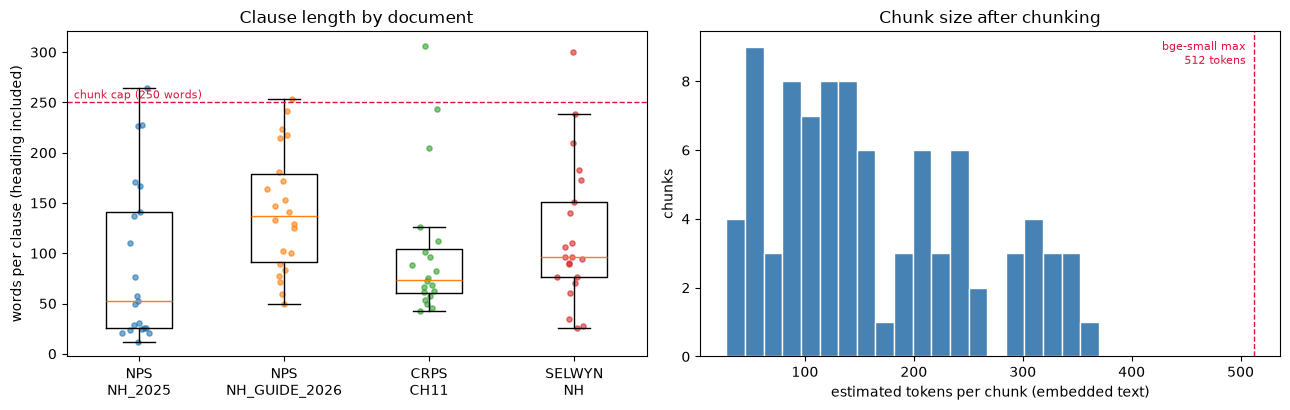

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
docs = list(manifest)
ax[0].boxplot([cw[cw.document_id == d].words for d in docs], tick_labels=[d.replace("_", "\n", 1) for d in docs], showfliers=False)
for i, d in enumerate(docs, 1):
    v = cw[cw.document_id == d].words; ax[0].scatter(np.random.default_rng(0).normal(i, 0.05, len(v)), v, s=14, alpha=.6)
ax[0].axhline(CONFIG["chunk_cap_words"], color="crimson", ls="--", lw=1); ax[0].text(0.55, CONFIG["chunk_cap_words"] + 4, "chunk cap (250 words)", color="crimson", fontsize=8)
ax[0].set_ylabel("words per clause (heading included)"); ax[0].set_title("Clause length by document")
tok = [ch["metadata"]["est_tokens"] for ch in CHUNKS]
ax[1].hist(tok, bins=20, color="steelblue", edgecolor="white"); ax[1].axvline(512, color="crimson", ls="--", lw=1)
ax[1].text(505, ax[1].get_ylim()[1] * .9, "bge-small max\n512 tokens", color="crimson", ha="right", fontsize=8)
ax[1].set_xlabel("estimated tokens per chunk (embedded text)"); ax[1].set_ylabel("chunks"); ax[1].set_title("Chunk size after chunking")
plt.savefig("../figures/chunking_analysis.png", dpi=300, bbox_inches="tight"),
plt.tight_layout(); plt.show()

Left: clauses are short and the cap only ever bites on two of them (points above the dashed line). Right: after chunking, every chunk sits well below the embedder's 512-token limit, so nothing is silently truncated at embedding time.

#### 1.7 Validation

A chunking pipeline can fail silently (a lost clause, a dropped table row, a chunk that straddles two clauses), and every later task depends on it. The checks below are executable assertions, not eyeballing.

In [17]:
norm = lambda s: re.sub(r"[\W_]+", "", s.casefold())
all_units   = {(c["document_id"], c["clause_id"]) for c in CLAUSES}
chunk_units = {(ch["metadata"]["document_id"], ch["metadata"]["clause_id"]) for ch in CHUNKS}
gold_rows   = list(csv.DictReader((DATA_DIR / "gold_relevance.csv").open(encoding="utf-8-sig", newline="")))
gold_units  = {(r["document_id"], r["clause_id"]) for r in gold_rows}
required_units = {(r["document_id"], r["clause_id"]) for r in gold_rows if r["relevance_type"] == "required"}

blob = collections.defaultdict(str)
for ch in CHUNKS: blob[(ch["metadata"]["document_id"], ch["metadata"]["clause_id"])] += norm(ch["text"])
lost = []
for c in CLAUSES:
    key = (c["document_id"], c["clause_id"])
    if norm(c["heading"]) not in blob[key]: lost.append((key, "heading"))
    for u in c["units"]:
        pieces = ([u["lead"]] + u["items"] if u["kind"] == "list" else
                  u["lines"] if u["kind"] == "para" else
                  ([u["head"][0]] if u["has_caption"] else []) +
                  [part.strip() for r in u["raw_rows"] for cell in r if cell for part in cell.split("\\")])   # cross-tab corner cell 'A \\ B' is re-expressed as rows: A; columns: B
        lost += [(key, p[:60]) for p in pieces if norm(p) not in blob[key]]

split_clauses = [(ch["metadata"]["document_id"], ch["metadata"]["clause_id"]) for ch in CHUNKS if ch["metadata"]["part"].startswith("1/") and not ch["metadata"]["part"].endswith("/1")]
multi_page = sorted({(ch["metadata"]["document_id"], ch["metadata"]["clause_id"], f'{ch["metadata"]["page_start"]}-{ch["metadata"]["page_end"]}')
                     for ch in CHUNKS if ch["metadata"]["page_start"] != ch["metadata"]["page_end"]})

checks = [
    ("84 marked clauses recovered (brief: 84)",                                   len(CLAUSES) == 84),
    ("21 pages in total (brief: 21)",                                             int(raw_overview.pages.sum()) == 21),
    ("(document_id, clause_id) pairs unique",                                     len(all_units) == len(CLAUSES)),
    ("every clause has >= 1 chunk",                                               chunk_units == all_units),
    (f"all {len(gold_units)} gold evidence units exist as chunks",                gold_units <= chunk_units),
    (f"all {len(required_units)} *required* gold units exist as chunks",          required_units <= chunk_units),
    ("every chunk covers exactly one clause (no multi-clause credit inflation)",  all(len(ch["metadata"]["clause_ids"]) == 1 for ch in CHUNKS)),
    ("no [[CLAUSE ...]] marker text leaked into chunk text",                       not any("[[CLAUSE" in ch["text"] for ch in CHUNKS)),
    ("no source text lost (every heading, paragraph, list item, table cell present)", not lost),
    (f"no chunk above the cap ({CONFIG['chunk_cap_words']} words)",                max(ch["metadata"]["n_words"] for ch in CHUNKS) <= CONFIG["chunk_cap_words"]),
    ("no atomic unit had to be cut",                                               N_FORCED == 0),
    ("max estimated tokens < 400 (margin under 512)",                              max(ch["metadata"]["est_tokens"] for ch in CHUNKS) < 400),
]
display(pd.DataFrame(checks, columns=["check", "passed"]))
assert all(ok for _, ok in checks), [n for n, ok in checks if not ok]
print("lost pieces:", lost[:5])
print(f"\nclauses split into >1 chunk: {len({k for k in split_clauses})} -> {sorted(set(split_clauses))}")
print(f"clauses whose text spans a page break ({len(multi_page)}):"); [print("   ", m) for m in multi_page]
print(f"\nmax words per chunk: {max(ch['metadata']['n_words'] for ch in CHUNKS)} | max estimated tokens: {max(ch['metadata']['est_tokens'] for ch in CHUNKS)}")

,check,passed
0,84 marked clauses recovered (brief: 84),True
1,21 pages in total (brief: 21),True
2,"(document_id, clause_id) pairs unique",True
3,every clause has >= 1 chunk,True
4,all 44 gold evidence units exist as chunks,True
5,all 32 *required* gold units exist as chunks,True
6,every chunk covers exactly one clause (no mult...,True
7,no [[CLAUSE ...]] marker text leaked into chun...,True
8,"no source text lost (every heading, paragraph,...",True
9,no chunk above the cap (250 words),True


lost pieces: []

clauses split into >1 chunk: 4 -> [('CRPS_CH11', '11.3.1'), ('NPS_NH_2025', 'Appendix 1 Table 1'), ('NPS_NH_GUIDE_2026', 'Part 4: Best available information'), ('SELWYN_NH', 'NH-SCHED1')]
clauses whose text spans a page break (9):
    ('CRPS_CH11', '11.3.1', '2-3')
    ('CRPS_CH11', '11.3.4', '3-4')
    ('CRPS_CH11', '11.3.9', '4-5')
    ('NPS_NH_2025', '1.3', '1-2')
    ('NPS_NH_2025', 'Appendix 1 Table 2', '4-5')
    ('NPS_NH_GUIDE_2026', 'Part 3: Exclusions', '2-3')
    ('NPS_NH_GUIDE_2026', 'Part 4: Proportionate management', '4-5')
    ('SELWYN_NH', 'NH-Overlays', '1-2')
    ('SELWYN_NH', 'NH-P1', '2-3')

max words per chunk: 243 | max estimated tokens: 370


**Validation result.** All structural checks pass: every clause, and therefore every development gold unit, exists as a chunk (the reserved-test rows of `gold_relevance.csv` are deliberately not read until Task 5); each chunk carries exactly one clause id, so Recall@5/MRR@5 matching is unambiguous; no source text was lost; no atomic unit had to be cut; and all chunks are below the size cap. Clauses that cross a page break (listed above) are intact, including CRPS 11.3.1, whose lead-in and exceptions sit on different pages.

Caveat on token counts: the estimate is a proxy. The cell above compares it with the real `bge-small` tokenizer when that is available (on the machine where the model runs); the margin (< 400 vs. 512) is deliberately generous because table text with `=`, `%` and numerals tokenises more densely than prose.

### 1.8 Inspecting representative chunks

Four chunks that exercise the design: a rule with limbs and a teaching note; a rule separated from its exceptions by a page break; the likelihood table; and a chunk with explicit cross-references.

In [18]:
# A. Table elements as extracted from the PDFs (what the summary table counted)
print("ELEMS keys:", list(next(e for d in ELEMS for e in ELEMS[d]).keys()))
for d in ELEMS:
    for e in ELEMS[d]:
        if e["kind"] == "table":
            print(d, "| page", e.get("page"), "|", str(e.get("text", e))[:120].replace("\n", " ⏎ "))

# B. Table units after clause assembly (what the unit tally counted)
print()
for c in CLAUSES:
    for u in c["units"]:
        if u["kind"] == "table":
            print(c["document_id"], "|", c["clause_id"], "|", u["pages"], "|", len(u.get("text", "").split()), "words")

# C. Chunks flagged as containing a table
print()
print(meta.loc[meta.has_table, ["document_id", "clause_id", "part", "n_words"]])

ELEMS keys: ['kind', 'page', 'top', 'bottom', 'text', 'gap']
NPS_NH_2025 | page 1 | {'kind': 'table', 'page': 1, 'top': 98.35440000000006, 'bottom': 268.85440000000006, 'pages': [1], 'rows': [['Field', 'V
NPS_NH_2025 | page 4 | {'kind': 'table', 'page': 4, 'top': 272.35440000000006, 'bottom': 374.85440000000006, 'pages': [4], 'rows': [['Consequen
NPS_NH_2025 | page 4 | {'kind': 'table', 'page': 4, 'top': 499.85440000000006, 'bottom': 623.8544, 'pages': [4], 'rows': [['Likelihood level', 
NPS_NH_2025 | page 4 | {'kind': 'table', 'page': 4, 'top': 704.85437, 'bottom': 789.35437, 'pages': [4, 5], 'rows': [['Consequence level', 'Dam
NPS_NH_GUIDE_2026 | page 1 | {'kind': 'table', 'page': 1, 'top': 118.35440000000006, 'bottom': 251.85440000000006, 'pages': [1], 'rows': [['Field', '
CRPS_CH11 | page 1 | {'kind': 'table', 'page': 1, 'top': 118.35440000000006, 'bottom': 261.35440000000006, 'pages': [1], 'rows': [['Field', '
SELWYN_NH | page 1 | {'kind': 'table', 'page': 1, 'top': 98.35440000000

In [19]:
ch = next(c for c in CHUNKS
          if c["metadata"]["document_id"] == "NPS_NH_2025"
          and c["metadata"]["clause_id"] == "Appendix 1 Table 1")
print(ch["metadata"]["page_start"], ch["metadata"]["n_words"], "words")
print("---- text (what the generator sees) ----")
print(ch["text"])
print("---- embed_text (first 200 chars) ----")
print(ch["embed_text"][:200])

4 24 words
---- text (what the generator sees) ----
Likelihood table
Likelihood is expressed either as an annual exceedance probability (AEP) or as an average recurrence interval (ARI), also called a return period.
---- embed_text (first 200 chars) ----
National Policy Statement for Natural Hazards 2025 — Appendix 1 Table 1
Likelihood table
Likelihood is expressed either as an annual exceedance probability (AEP) or as an average recurrence interval (


In [ ]:
# Find the actual file (don't guess the folder layout)
print(sorted(p.name for p in (DATA_DIR / "policy_corpus").glob("*")))

['CRPS_Chapter11_Natural_Hazards.pdf', 'NPS_NH_2025.pdf', 'NPS_NH_Implementation_Guide_2026.pdf', 'Selwyn_POSDP_Natural_Hazards_2026-09-06.pdf']


In [21]:
PDF = DATA_DIR / "policy_corpus" / "NPS_NH_2025.pdf"   # adjust to the exact name printed above

with pdfplumber.open(PDF) as pdf:
    for pn in (4, 5):                                   # Appendix 1 tables are on pages 4-5
        page = pdf.pages[pn - 1]
        print(f"\n--- page {pn}: plain text ---")
        print(page.extract_text()[:1200])
        print(f"--- page {pn}: extract_tables (first rows) ---")
        for t in page.extract_tables():
            for r in t[:3]:
                print("   ", r)


--- page 4: plain text ---
[[CLAUSE Part 4]]
Timing
(1) Decision-makers must give effect to this National Policy Statement on and from the commencement date,
except as provided for in (2).
(2) Local authorities are not required to initiate changes to regional policy statements, regional plans or district
plans within a specific timeframe for the sole purpose of giving effect to this National Policy Statement.
[[CLAUSE Appendix 1]]
Risk matrix, likelihood and consequence tables
When undertaking an assessment of natural hazard risk, the following risk matrix and associated tables must be
applied to enable assessment of the consequence level and likelihood level and to determine the applicable
level of natural hazard risk.
Figure 1 — Risk matrix. The same 35 likelihood x consequence mappings are supplied in machine-readable
form in risk_matrix.csv. For this assessment, apply the deterministic lookup rather than asking a language
model to reproduce the matrix from memory.
Consequence \ Al

In [22]:
expect = {"Appendix 1": (6, 8), "Appendix 1 Table 1": (8, 3), "Appendix 1 Table 2": (6, 3)}
for c in CLAUSES:
    if c["document_id"] == "NPS_NH_2025" and c["clause_id"] in expect:
        for u in c["units"]:
            if u["kind"] == "table":
                rows = u["rows"]
                print(c["clause_id"], "| rows x cols:", len(rows), "x", len(rows[0]),
                      "| expected:", expect[c["clause_id"]],
                      "| header repeated:", sum(r[0].replace("\n", " ").startswith(("Consequence level", "Consequence")) for r in rows),
                      "| newline in cells:", any("\n" in cell for r in rows for cell in r))

# What the generator actually sees for each table chunk
for ch in CHUNKS:
    m = ch["metadata"]
    if m["document_id"] == "NPS_NH_2025" and m["clause_id"].startswith("Appendix 1") and m["has_table"]:
        print("=" * 70, "\n", m["clause_id"], "part", m["part"], "\n", ch["text"][:700])

Appendix 1 | rows x cols: 5 x 170 | expected: (6, 8) | header repeated: 0 | newline in cells: False
Appendix 1 Table 1 | rows x cols: 7 x 136 | expected: (8, 3) | header repeated: 0 | newline in cells: False
Appendix 1 Table 2 | rows x cols: 5 x 326 | expected: (6, 3) | header repeated: 0 | newline in cells: False
 Appendix 1 part 1/1 
 Risk matrix, likelihood and consequence tables
When undertaking an assessment of natural hazard risk, the following risk matrix and associated tables must be applied to enable assessment of the consequence level and likelihood level and to determine the applicable level of natural hazard risk.
Figure 1 — Risk matrix. The same 35 likelihood x consequence mappings are supplied in machine-readable form in risk_matrix.csv. For this assessment, apply the deterministic lookup rather than asking a language model to reproduce the matrix from memory.
[Table — rows: Consequence; columns: Likelihood]
Consequence = Catastrophic: Almost certain → Very high; Very lik

In [23]:
def get(cid, part=None):
    return next(c for c in CHUNKS if c["metadata"]["document_id"] == "NPS_NH_2025"
                and c["metadata"]["clause_id"] == cid and (part is None or c["metadata"]["part"] == part))

print(get("Appendix 1")["text"].count("→"), "matrix mappings (expect 35)")
print(get("Appendix 1 Table 1", "2/2")["text"].count("Likelihood level ="), "likelihood rows (expect 7)")
cons = get("Appendix 1 Table 2")["text"]
print([l.split(";")[0] for l in cons.splitlines() if l.startswith("Consequence level =")])

35 matrix mappings (expect 35)
7 likelihood rows (expect 7)
['Consequence level = Catastrophic', 'Consequence level = Major', 'Consequence level = Moderate', 'Consequence level = Minor', 'Consequence level = Negligible']


In [24]:
def show(doc, clause, part=None):
    for ch in CHUNKS:
        m = ch["metadata"]
        if m["document_id"] == doc and m["clause_id"] == clause and (part is None or m["part"] == part):
            keep = {k: m[k] for k in ("clause_id", "clause_type", "authority_level", "document_status", "binding", "effective_date", "page_start", "page_end", "part",
                                      "hazard_types", "primary_hazard", "content_roles", "has_exception", "cross_refs", "n_words", "est_tokens")}
            print("=" * 110); print(ch["chunk_id"], "|", json.dumps(keep, ensure_ascii=False)); print("-" * 110); print(ch["text"])

show("SELWYN_NH", "NH-P1")
show("CRPS_CH11", "11.3.1")

SELWYN_NH::0007 | {"clause_id": "NH-P1", "clause_type": "policy", "authority_level": "district", "document_status": "partially_operative", "binding": true, "effective_date": "2026-05-19", "page_start": 2, "page_end": 3, "part": "1/1", "hazard_types": ["general"], "primary_hazard": "general", "content_roles": ["provision", "teaching_note"], "has_exception": true, "cross_refs": [["SELWYN_NH", "NH-P2"]], "n_words": 173, "est_tokens": 267}
--------------------------------------------------------------------------------------------------------------
Policy — High hazard areas
Avoid new subdivision, use, or development of land in high hazard areas, except for important infrastructure and land transport infrastructure where NH-P2 applies instead, unless the subdivision, use or development either:
1. is not likely to: (a) result in loss of life or serious injuries; and (b) suffer significant damage or loss; and (c) require new or upgraded natural hazard mitigation works to mitigate or avoid th

In [25]:
show("NPS_NH_2025", "Appendix 1 Table 1")
show("NPS_NH_GUIDE_2026", "Part 4: Risk level")

NPS_NH_2025::0019 | {"clause_id": "Appendix 1 Table 1", "clause_type": "appendix_table", "authority_level": "national", "document_status": "in_force", "binding": true, "effective_date": "2026-01-15", "page_start": 4, "page_end": 4, "part": "1/2", "hazard_types": ["flooding"], "primary_hazard": "flooding", "content_roles": ["provision"], "has_exception": false, "cross_refs": [], "n_words": 24, "est_tokens": 49}
--------------------------------------------------------------------------------------------------------------
Likelihood table
Likelihood is expressed either as an annual exceedance probability (AEP) or as an average recurrence interval (ARI), also called a return period.
NPS_NH_2025::0020 | {"clause_id": "Appendix 1 Table 1", "clause_type": "appendix_table", "authority_level": "national", "document_status": "in_force", "binding": true, "effective_date": "2026-01-15", "page_start": 4, "page_end": 4, "part": "2/2", "hazard_types": ["flooding"], "primary_hazard": "flooding", "cont

Documents to notice:

* **NH-P1**: the rule, both limbs and the teaching note are one chunk; `has_exception=True`, `content_roles` shows the teaching note separately from `provision`; the note ("Limb 1 requires all four of (a) to (d)") is precisely the kind of text that must not be separated from the rule.

* **CRPS 11.3.1**: the lead-in from page 2 and the seven exceptions from page 3 are in the same chunk (`page_start=2`, `page_end=3`); the explanatory paragraphs after the list form part 2 and carry the heading, so they are not orphaned.

* **Likelihood table**: the boundary convention is attached to the table and every row is self-describing, so the row for `Possible` states `2% to 1%` and `Over 50 and up to and including 100 years` together; a 100-year return period is therefore answerable from one chunk.

* **Guide clause**: `cross_refs` links the Implementation Guide (non-binding, `binding=False`) to the NPS-NH clauses it interprets.

#### 1.9 Issues found during inspection

The scans below extract sentences in the corpus that constrain how it may be used (what must not be cited, which source prevails, what is out of scope). They are *evidence for design decisions in Tasks 3–5*, so we list them now rather than discover them as failures later.

In [26]:
SCAN = {
    "NOT-TO-BE-CITED / NOT IN CORPUS": r"must not be cited|must not cite|not (?:included in|part of) the (?:supplied )?corpus|not reproduced|is not included",
    "REFERENCED FILE NOT SUPPLIED":    r"risk_matrix\.csv",
    "EXCLUDED VERSION (DRAFT)":        r"Draft CRPS",
    "PRECEDENCE / AUTHORITY":          r"prevails|authoritative|binding source|does not have the status|supporting interpretation|status of explanation|is the regional one",
    "OUT OF SCOPE":                    r"outside the scope",
}
sources = [(c["document_id"], c["clause_id"], l) for c in CLAUSES for u in c["units"] for l in unit_lines(u)] + \
          [(d, "(page-1 preamble, not indexed)", PREAMBLE[d][1]) for d in manifest]
for label, pat in SCAN.items():
    print(f"\n### {label}")
    for d, cid, l in sources:
        m = re.search(pat, l, re.I)
        if m:
            s = max(0, m.start() - 70); print(f"  {d:18s} {cid:30s} …{l[s:m.end() + 60]}…")
print("\nTeaching / advice notes per document:",
      {d: sum(u["role"] in ("teaching_note", "advice_note") for c in CLAUSES if c["document_id"] == d for u in c["units"]) for d in manifest})


### NOT-TO-BE-CITED / NOT IN CORPUS
  NPS_NH_GUIDE_2026  Appendix 1                     …For COMP662 Assignment 2, these referenced documents are not part of the supplied corpus. A response must not cite them as retrieved evidence.…
  SELWYN_NH          NH-Overview                    …, fault, slope-instability and wildfire provisions of the chapter are not reproduced and must not be cited as retrieved evidence.…
  SELWYN_NH          NH-Definitions                 …Those definitions are not part of the Natural Hazards chapter and are not reproduced in this extract.…
  CRPS_CH11          (page-1 preamble, not indexed) … CRPS is the regional source for this assessment. The Draft CRPS 2024 is not included in the corpus and must not be cited. Methods, anticipated e…

### REFERENCED FILE NOT SUPPLIED
  NPS_NH_2025        Appendix 1                     …ihood x consequence mappings are supplied in machine-readable form in risk_matrix.csv. For this assessment, apply the deterministic lookup 

**Findings and how they will be used**

1. **Clause ids are not globally unique** (`Appendix 1` in two documents). Evidence identity is always `(document_id, clause_id)`; the citation parser in the support notebook already assumes this.

2. **Teaching notes are not plan text.** 20 Selwyn paragraphs (19 teaching notes, 1 advice note; the other three documents have none) are course commentary, some of which encode decisive interpretation rules (floor levels must be *certified*; district mapping is not site-specific evidence). We keep them in the chunk (they matter for correct answers) but flag them, so Task 4 prompts can instruct the model to keep plan text and teaching commentary distinct and Task 5 can diagnose whether an error arose from confusing them.

3. **Source authority is stated inside the corpus.** The Implementation Guide is non-binding and must be cited as *supporting interpretation* to the NPS-NH; the NZ Coastal Policy Statement 2010 prevails over the NPS-NH in the coastal environment; Selwyn's own text defers to the *regional* high-hazard-area definition. Metadata (`binding`, `authority_level`, `content_roles`) makes these distinctions available to retrieval and prompting.

4. **Some material must not be cited even though it is mentioned.** Un-reproduced coastal/fault/slope/wildfire provisions, the Guide's Appendix 1 reference list, and the Draft CRPS 2024 are explicitly *not* in the corpus. A system that cites them is fabricating. These are natural test cases for the `fabricated` / `suspicious` buckets in Task 4.

5. **A referenced file is missing.** NPS-NH Appendix 1 says the 35 matrix mappings are supplied in `risk_matrix.csv`; the dataset does not include it. We recover the matrix from the PDF table grid (below) and validate that it has exactly 35 cells.

6. **Out-of-scope hazards are present in the index** (e.g. the NH-R2.1 coastal rule). They are tagged `in_assignment_scope=False` rather than deleted: the corpus is frozen and they may be legitimate gold or distractor evidence.\n7. **Some constraints live only on page 1 and are therefore not retrievable.** The instruction that the Draft CRPS 2024 must not be cited, and the statement that Selwyn's *Teaching note* paragraphs are course explanation rather than plan text, appear in the page-1 preamble (or manifest), which is deliberately not indexed. If they matter for behaviour they must be delivered another way, through metadata and prompt rules (Task 4), not by hoping retrieval returns them. The preamble notes are therefore stored in `processed/doc_metadata.json` (`teaching_use_note`).

8. **The likelihood boundary convention is a trap** (a 100-year return period is *Possible*, not *Unlikely*). It lives in prose *above* the table, which is why the caption/interpretation paragraph is bound to the table unit.

### 1.10 Structured tables and saved artefacts

The risk matrix is a deterministic lookup (the Implementation Guide says so explicitly: it should not be re-derived or reasoned about qualitatively). Since `risk_matrix.csv` is not supplied, we rebuild it from the extracted grid and check it against the text ("35 mappings").

In [27]:
RISK_MATRIX, TABLES = {}, []
for c in CLAUSES:
    for u in c["units"]:
        if u["kind"] != "table": continue
        hdr, body = u["raw_rows"][0], u["raw_rows"][1:]
        TABLES.append({"document_id": c["document_id"], "clause_id": c["clause_id"], "pages": u["pages"], "merged_across_pages": u["merged"],
                       "header": hdr, "rows": body})
        if "\\" in hdr[0]:
            for r in body:
                for col, val in zip(hdr[1:], r[1:]): RISK_MATRIX[(r[0], col)] = val

assert len(RISK_MATRIX) == 35, len(RISK_MATRIX)
assert RISK_MATRIX[("Major", "Possible")] == "High" and RISK_MATRIX[("Catastrophic", "Almost certain")] == "Very high"
assert all(RISK_MATRIX[("Negligible", l)] == "Low" for l in {k[1] for k in RISK_MATRIX})
print("risk matrix recovered from the PDF grid: 35 mappings; e.g. (Major, Possible) ->", RISK_MATRIX[("Major", "Possible")],
      "| (Moderate, Rare) ->", RISK_MATRIX[("Moderate", "Rare")])

# ---- save artefacts (all relative paths; regenerated on every run) ----
with (OUT_DIR / "chunks.jsonl").open("w", encoding="utf-8") as f:
    for ch in CHUNKS: f.write(json.dumps(ch, ensure_ascii=False) + "\n")
(OUT_DIR / "doc_metadata.json").write_text(json.dumps(DOC_META, indent=2, ensure_ascii=False), encoding="utf-8")
(OUT_DIR / "tables.json").write_text(json.dumps(TABLES, indent=2, ensure_ascii=False), encoding="utf-8")
(OUT_DIR / "risk_matrix.json").write_text(json.dumps([{"consequence": k[0], "likelihood": k[1], "risk_level": v} for k, v in RISK_MATRIX.items()], indent=2), encoding="utf-8")
(OUT_DIR / "extracted_corpus").mkdir(exist_ok=True)
for d in manifest:                                                           # clean extracted text, one file per document
    txt = "\n\n".join(f"[[CLAUSE {c['clause_id']}]]\n" + render(c["heading"], c["units"]) for c in CLAUSES if c["document_id"] == d)
    (OUT_DIR / "extracted_corpus" / f"{d}.txt").write_text(txt, encoding="utf-8")
for p in sorted(OUT_DIR.rglob("*")):
    if p.is_file(): print(f"  {str(p):55s} {p.stat().st_size / 1024:7.1f} kB")

# Reload check: the saved file is what later tasks will read
reloaded = [json.loads(l) for l in (OUT_DIR / "chunks.jsonl").open(encoding="utf-8")]
assert len(reloaded) == len(CHUNKS) and reloaded[0]["metadata"]["clause_ids"] == [CHUNKS[0]["metadata"]["clause_id"]]
print("\nreload check OK:", len(reloaded), "chunks")

risk matrix recovered from the PDF grid: 35 mappings; e.g. (Major, Possible) -> High | (Moderate, Rare) -> Low
  processed\chunks.jsonl                                    198.6 kB
  processed\doc_metadata.json                                 3.9 kB
  processed\extracted_corpus\CRPS_CH11.txt                   13.4 kB
  processed\extracted_corpus\NPS_NH_2025.txt                 12.4 kB
  processed\extracted_corpus\NPS_NH_GUIDE_2026.txt           21.2 kB
  processed\extracted_corpus\SELWYN_NH.txt                   15.9 kB
  processed\frozen_config.json                                0.7 kB
  processed\risk_matrix.json                                  3.5 kB
  processed\tables.json                                       3.6 kB
  processed\task2_baseline_answers.json                      36.9 kB
  processed\task4_prompt_answers.json                       220.8 kB
  processed\task5_final_answers.json                        437.4 kB

reload check OK: 88 chunks


### Task 1 summary

**What was built.** A deterministic, executable pipeline: `pdfplumber` extraction with table detection and page-break table merging → paragraph recovery from measured line spacing → clause segmentation from the `[[CLAUSE]]` markers → structural units (rule + exceptions, caption + table) → clause-aligned chunks capped at 250 words → rich metadata → executable validation. Output: `processed/chunks.jsonl` (the index input for Task 2), plus tables, risk matrix, document metadata and clean per-document text.

**Design choices justified by evidence:** clause-aligned (no multi-clause chunks) so the retrieval metrics are unambiguous; cap of 250 words because it is the smallest round cap that never cuts an atomic unit (sensitivity table); table rows re-serialised because generic extraction destroys row/column meaning; teaching notes kept but flagged because they are not plan text.

**Limitations to keep in mind.**
* The chunk size is justified structurally and against the embedder limit, *not* against retrieval scores; the ablation of cap and overlap is deferred to Task 3, where retrieval can actually be measured.
* Token counts are an estimate unless the BGE tokenizer is available (see 1.7).
* Hazard tags are a keyword lexicon (e.g. *inundation* can tag coastal text as `flooding`); they support analysis and filtering but are not ground truth.
* Row-serialisation of tables lengthens the text (repeated column names), a deliberate accuracy-for-length trade-off that shows up later as prompt tokens.
* Table detection relies on ruled tables. That holds for these four PDFs (all tables were found and the header row check for page-spanning tables passed) but would need re-testing for other documents.
* The corpus is a frozen, condensed teaching extract; nothing here generalises to the live policy documents.

*Next:* Task 2 loads `processed/chunks.jsonl`, embeds `embed_text` with `bge-small-en-v1.5`, builds the FAISS index and runs the baseline RAG pipeline.

### **Task 2: Baseline RAG System**

**Goal:** a complete, reproducible baseline, dense retrieval only, the simplest possible prompt, no optimisation so that later tasks will be measured against. Everything here is deliberately plain: Task 3 improves retrieval, Task 4 improves the prompt.

Required configuration (frozen for the whole assignment unless a task explicitly asks to vary it):

In [28]:
BASELINE_CONFIG = {
    "embedding_model": "BAAI/bge-small-en-v1.5",
    "generator_model": "Qwen/Qwen2.5-1.5B-Instruct",
    "vector_store": "FAISS (IndexFlatIP, cosine via normalised vectors)",
    "top_k": 5,
    "query_prefix_used": False,   # untested at this stage; measured empirically in Task 3
    "do_sample": False,
    "max_new_tokens": 1024,
}
for k, v in BASELINE_CONFIG.items(): print(f"  {k:18s} {v}")

  embedding_model    BAAI/bge-small-en-v1.5
  generator_model    Qwen/Qwen2.5-1.5B-Instruct
  vector_store       FAISS (IndexFlatIP, cosine via normalised vectors)
  top_k              5
  query_prefix_used  False
  do_sample          False
  max_new_tokens     1024


## 2.1 Load the Task 1 chunks

In [29]:
CHUNKS = [json.loads(l) for l in (OUT_DIR / "chunks.jsonl").open(encoding="utf-8")]
assert CHUNKS, "processed/chunks.jsonl is empty or missing -- run Task 1 first."
print(f"{len(CHUNKS)} chunks loaded from {OUT_DIR / 'chunks.jsonl'}")
display(pd.DataFrame([{"chunk_id": c["chunk_id"], **{k: c["metadata"][k] for k in
        ("document_id", "clause_id", "clause_type", "authority_level", "n_words")}} for c in CHUNKS[:4]]))

88 chunks loaded from processed\chunks.jsonl


,chunk_id,document_id,clause_id,clause_type,authority_level,n_words
0,NPS_NH_2025::0000,NPS_NH_2025,Authority,provision,national,141
1,NPS_NH_2025::0001,NPS_NH_2025,1.1,provision,national,12
2,NPS_NH_2025::0002,NPS_NH_2025,1.2,provision,national,26
3,NPS_NH_2025::0003,NPS_NH_2025,1.3,provision,national,167


#### 2.2 Embeddings and FAISS index

`embed()` is the one function every later task calls; its signature does not change, only its backend. This notebook tries to load the real baseline embedder, `BAAI/bge-small-en-v1.5`, from Hugging Face.  **On a machine with internet access, delete nothing: just re-run this cell; the real embedder loads automatically and every downstream cell is unaffected.**

In [30]:
EMBEDDING_MODEL_ID = BASELINE_CONFIG["embedding_model"]
BGE_QUERY_PREFIX   = "Represent this sentence for searching relevant passages: "

try:
    from sentence_transformers import SentenceTransformer
    t0 = time.time()
    _embedder = SentenceTransformer(EMBEDDING_MODEL_ID)
    EMBED_DIM = _embedder.get_sentence_embedding_dimension()
    print(f"loaded {EMBEDDING_MODEL_ID} in {time.time() - t0:.1f}s, dimension {EMBED_DIM}")

    def embed(texts, is_query=False, use_prefix=BASELINE_CONFIG["query_prefix_used"]):
        if is_query and use_prefix: texts = [BGE_QUERY_PREFIX + t for t in texts]
        return _embedder.encode(texts, normalize_embeddings=True, convert_to_numpy=True, batch_size=16).astype("float32")


    EMBEDDING_BACKEND, EMBEDDING_IS_BASELINE = f"{EMBEDDING_MODEL_ID} (assessed baseline embedder)", True

except Exception as e:
    raise RuntimeError(
        f"Could not load {EMBEDDING_MODEL_ID} ({type(e).__name__}: {e}). This notebook requires the real "
        "bge-small-en-v1.5 embedder and has no fallback -- check internet access to Hugging Face (huggingface.co) "
        "and that 'sentence-transformers' is installed, then re-run this cell. Do not substitute another embedder."
    ) from e

print("embedding backend in use:", EMBEDDING_BACKEND)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2673.38it/s]


loaded BAAI/bge-small-en-v1.5 in 7.7s, dimension 384
embedding backend in use: BAAI/bge-small-en-v1.5 (assessed baseline embedder)


C:\Users\HP\AppData\Local\Temp\ipykernel_16084\1787682525.py:8: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  EMBED_DIM = _embedder.get_sentence_embedding_dimension()


In [31]:
doc_vectors = embed([c["embed_text"] for c in CHUNKS])
faiss_index = faiss.IndexFlatIP(doc_vectors.shape[1])
faiss_index.add(doc_vectors)
print(f"FAISS index built: {faiss_index.ntotal} vectors, dimension {doc_vectors.shape[1]} "
      f"({'cosine, since vectors are L2-normalised' if np.allclose(np.linalg.norm(doc_vectors, axis=1), 1, atol=1e-3) else 'WARNING: vectors are not normalised'})")

FAISS index built: 88 vectors, dimension 384 (cosine, since vectors are L2-normalised)


#### 2.3 Dense retrieval, top *k* = 5

`retrieve()` returns ranked `(score, chunk)` pairs. `show_retrieval()` displays the text and the metadata fields useful for judging a result: authority, status, clause type, page, and whether it carries a teaching note or exception wording.

In [32]:
def retrieve(question, k=BASELINE_CONFIG["top_k"], index=faiss_index, chunks=CHUNKS, use_prefix=BASELINE_CONFIG["query_prefix_used"]):
    qv = embed([question], is_query=True, use_prefix=use_prefix)
    scores, ids = index.search(qv, k)
    return [(float(s), chunks[int(i)]) for s, i in zip(scores[0], ids[0]) if i != -1]

def show_retrieval(question, k=BASELINE_CONFIG["top_k"], **kw):
    hits = retrieve(question, k=k, **kw)
    rows = [{"rank": r + 1, "score": round(s, 3), "document_id": c["metadata"]["document_id"], "clause_id": c["metadata"]["clause_id"],
             "authority": c["metadata"]["authority_level"], "status": c["metadata"]["document_status"], "type": c["metadata"]["clause_type"],
             "page": c["metadata"]["page_start"], "note": "teaching_note" if c["metadata"]["has_teaching_note"] else "",
             "heading": c["metadata"]["heading"][:55]} for r, (s, c) in enumerate(hits)]
    display(pd.DataFrame(rows))
    return hits

_ = show_retrieval("What must happen where natural hazard risk is very high?")

,rank,score,document_id,clause_id,authority,status,type,page,note,heading
0,1,0.792,NPS_NH_2025,2.2 Policy 3,national,in_force,policy,2,,Very high risk
1,2,0.769,CRPS_CH11,Definition: high hazard areas,regional,operative,definition,5,,Definition — High hazard areas
2,3,0.769,SELWYN_NH,NH-P2,district,partially_operative,policy,3,,Policy — Important infrastructure in high haza...
3,4,0.766,CRPS_CH11,11.3.1,regional,operative,policy,2,,Policy — Avoidance of inappropriate developmen...
4,5,0.764,CRPS_CH11,11.3.5,regional,operative,policy,4,,Policy — General risk management approach


In [33]:
_ = show_retrieval("For a subdivision in the Plains Flood Management Overlay, what floor level must new buildings achieve?")

,rank,score,document_id,clause_id,authority,status,type,page,note,heading
0,1,0.850,SELWYN_NH,NH-R2.3,district,partially_operative,rule,4,teaching_note,Rule — New buildings and structures in the Pla...
1,2,0.839,SELWYN_NH,NH-P10,district,partially_operative,policy,3,teaching_note,Policy — Plains Flood Management Overlay
2,3,0.769,SELWYN_NH,NH-P12,district,partially_operative,policy,4,teaching_note,Policy — Earthworks in flood management overlays
3,4,0.716,SELWYN_NH,NH-R2.5,district,partially_operative,rule,5,teaching_note,Rule — New buildings and structures in the Wai...
4,5,0.705,SELWYN_NH,NH-Overlays,district,partially_operative,overview,1,teaching_note,Overlays used in this chapter


This second query is a good stress test of the chunking from Task 1: the *numeric* floor-level standard sits in `NH-SCHED1`, but the *rule that applies it* is `NH-R2.3`, and the policy that states it qualitatively is `NH-P10`. All three should be visible in the metadata table so a reader and, in Task 4, the generator can see the standard is set in the schedule rather than being invented.

### 2.4 Case facts

Case-specific questions must be answered from the *supplied* structured facts, not from anything inferred. `render_case_facts()` turns one `site_cases.json` entry into plain text grouped exactly as the brief's field groups (Proposal, Site, Flood, Liquefaction, Mitigation, supplied risk levels, known uncertainties). Every field is shown, including nulls, printed as **"not supplied"** because silently dropping a null is how a prompt ends up inviting the model to fill the gap itself. A missing `risk_levels` entry is worded as *"not supplied cannot be determined from case facts"*, which is the fact the brief requires the assistant to state, not (yet) an instruction about what to conclude from it; the instruction to never substitute an inferred value for it is a **content instruction**, and belongs in the prompt (Task 4), not in the rendering of the facts themselves.

In [34]:
SITE_CASES = {c["case_id"]: c for c in json.load((DATA_DIR / "site_cases.json").open(encoding="utf-8"))}
print(f"{len(SITE_CASES)} site cases loaded:", sorted(SITE_CASES))

def _fmt(v):
    if v is None: return "not supplied"
    if isinstance(v, bool): return "yes" if v else "no"
    if isinstance(v, list): return "; ".join(map(str, v)) if v else "none supplied"
    return str(v)

FIELD_LABELS = {
    "proposal": [("activity_type", "Activity type"), ("number_of_lots_or_buildings", "Lots / buildings"),
                 ("expected_occupancy", "Expected occupancy"), ("vulnerable_occupants", "Vulnerable occupants"),
                 ("design_life_years", "Design life (years)")],
    "site":     [("planning_zone", "Planning zone"), ("existing_use", "Existing use"),
                 ("hazard_overlays", "Hazard overlays"), ("available_reports", "Available reports")],
    "flood":    [("evidence_available", "Evidence available"), ("aep_percent", "AEP (%)"), ("return_period_years", "Return period (years)"),
                 ("modelled_depth_m", "Modelled depth (m)"), ("velocity_m_s", "Velocity (m/s)"), ("climate_change_considered", "Climate change considered")],
    "liquefaction": [("susceptibility", "Susceptibility"), ("mapped_evidence", "Mapped evidence"),
                      ("site_specific_geotech_available", "Site-specific geotech available")],
    "mitigation": [("raised_floor_level", "Raised floor level"), ("freeboard_m", "Freeboard (m)"), ("drainage", "Drainage"),
                    ("foundation_design", "Foundation design"), ("access_or_evacuation", "Access / evacuation")],
}

def render_case_facts(case):
    lines = [f"Case {case['case_id']}"]
    for group, fields in FIELD_LABELS.items():
        lines.append(f"\n{group.capitalize()}:")
        lines += [f"  - {label}: {_fmt(case.get(group, {}).get(key))}" for key, label in fields]
    lines.append("\nSupplied risk levels:")
    for hazard in ("flooding", "liquefaction"):
        v = case["risk_levels"].get(hazard)
        lines.append(f"  - {hazard}: {v if v is not None else 'not supplied -- cannot be determined from case facts'}")
    lines.append("\nKnown uncertainties (as supplied):")
    lines += [f"  - {u}" for u in case["known_uncertainties"]] if case["known_uncertainties"] else ["  - none supplied"]
    return "\n".join(lines)

print(render_case_facts(SITE_CASES["SC010"]))

12 site cases loaded: ['SC001', 'SC002', 'SC003', 'SC004', 'SC005', 'SC006', 'SC007', 'SC008', 'SC009', 'SC010', 'SC011', 'SC012']
Case SC010

Proposal:
  - Activity type: small community hall
  - Lots / buildings: 1
  - Expected occupancy: Up to 120 people
  - Vulnerable occupants: no
  - Design life (years): 75

Site:
  - Planning zone: Rural township zone
  - Existing use: Vacant lot
  - Hazard overlays: none supplied
  - Available reports: none supplied

Flood:
  - Evidence available: no
  - AEP (%): not supplied
  - Return period (years): not supplied
  - Modelled depth (m): not supplied
  - Velocity (m/s): not supplied
  - Climate change considered: not supplied

Liquefaction:
  - Susceptibility: not supplied
  - Mapped evidence: not supplied
  - Site-specific geotech available: no

Mitigation:
  - Raised floor level: not supplied
  - Freeboard (m): not supplied
  - Drainage: not supplied
  - Foundation design: not supplied
  - Access / evacuation: not supplied

Supplied risk lev

`SC010` (a community hall with no hazard reports at all) shows the rendering doing its job: every flood and liquefaction field reads `not supplied`, both risk levels read `not supplied — cannot be determined from case facts`, and the case's own two known uncertainties are carried through verbatim rather than summarised.

### 2.5 P1: the basic RAG prompt

Per the brief: retrieved context, the question, and case facts *if the question needs them* nothing else. **No citation format, no response structure, no role or technique.** This is the Task 2 baseline and also becomes the P1 condition compared in Task 4.

In [35]:
def build_p1_prompt(question, case_id=None, k=BASELINE_CONFIG["top_k"]):
    hits = retrieve(question, k=k)
    context = "\n\n".join(f"[{c['metadata']['document_id']} | clause {c['metadata']['clause_id']}]\n{c['text']}" for _, c in hits)
    parts = ["Use only the context below to answer the question.", "", "Context:", context]
    if case_id:
        parts += ["", "Case facts:", render_case_facts(SITE_CASES[case_id])]
    parts += ["", f"Question: {question}"]
    return "\n".join(parts), hits

prompt_demo, hits_demo = build_p1_prompt("For this subdivision, identify the relevant flood-related policy evidence "
                                          "and explain what supplied facts are most important to a preliminary assessment.", case_id="SC001")
print(prompt_demo[:1400], "\n...\n")
print(f"[{len(prompt_demo.split())} words, {est_tokens(prompt_demo)} estimated tokens, {len(hits_demo)} chunks in context]")

Use only the context below to answer the question.

Context:
[NPS_NH_GUIDE_2026 | clause Part 4: Detailed assessment]
When a detailed risk assessment is required
Under clause 3.3(1), decision-makers must have regard to the anticipated level of risk when considering the scale and detail of information necessary.
Most natural hazard data held by a local authority is at region-wide or district-wide scale and is either susceptibility or hazard information. That type of information indicates where an area is likely to be affected by a natural hazard, and may mean that deciding an application requires a request to the applicant for a further detailed assessment of the risk by a suitably qualified and experienced person (SQEP).
Any risk assessment prepared by an SQEP to support a consent application should align with the NPS-NH framework. Depending on the level of risk, it may also be appropriate for the consent authority to have the applicant's risk assessment peer reviewed by an SQEP before

### 2.6 Generator: Qwen2.5-1.5B-Instruct

Device and dtype selection follows `MODEL_SETUP.md` exactly: CUDA → MPS → CPU, and on CPU, `float32` above 12 GB RAM else `bfloat16` (float32 needs ≈ 7 GB for this checkpoint; bfloat16 ≈ 4.1 GB). Decoding is greedy (`do_sample=False`) with `max_new_tokens=1024`, fixed for every controlled comparison in this assignment. **This cell needs internet access to Hugging Face on first run** (≈ 3 GB download, cached afterwards). If that is not available in the current environment, it degrades gracefully- `GENERATOR_AVAILABLE=False` and section 2.7 explains what to do next; every other part of this notebook (retrieval, prompts, case facts) is unaffected.

In [36]:
MODEL_ID, MAX_NEW_TOKENS = BASELINE_CONFIG["generator_model"], BASELINE_CONFIG["max_new_tokens"]

def pick_device():
    if torch.cuda.is_available(): return torch.device("cuda")
    if hasattr(torch.backends, "mps") and torch.backends.mps.is_available(): return torch.device("mps")
    return torch.device("cpu")

def total_ram_bytes():
    try: return os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES")                       # macOS, Linux
    except (AttributeError, ValueError, OSError): pass
    try:
        import ctypes
        class MEMORYSTATUSEX(ctypes.Structure):
            _fields_ = [("dwLength", ctypes.c_ulong), ("dwMemoryLoad", ctypes.c_ulong)] + [
                (n, ctypes.c_ulonglong) for n in ("ullTotalPhys", "ullAvailPhys", "ullTotalPageFile",
                "ullAvailPageFile", "ullTotalVirtual", "ullAvailVirtual", "ullAvailExtendedVirtual")]
        status = MEMORYSTATUSEX(); status.dwLength = ctypes.sizeof(MEMORYSTATUSEX)
        ctypes.windll.kernel32.GlobalMemoryStatusEx(ctypes.byref(status)); return int(status.ullTotalPhys)
    except Exception: return None

def pick_dtype(device, ram_bytes=None):
    if device.type != "cpu": return torch.float16
    ram_bytes = ram_bytes if ram_bytes is not None else total_ram_bytes()
    return torch.bfloat16 if ram_bytes is None else (torch.float32 if ram_bytes > 12e9 else torch.bfloat16)

GENERATOR_AVAILABLE = False
try:
    import torch
    from transformers import AutoTokenizer, AutoModelForCausalLM
    device, dtype = pick_device(), pick_dtype(pick_device())
    ram = total_ram_bytes()
    print("device:", device, "| dtype:", dtype, "| RAM:", f"{ram / 1e9:.0f} GB" if ram else "unknown")
    t0 = time.time()
    tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
    model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=dtype).to(device).eval()
    print(f"model loaded in {time.time() - t0:.1f}s")
    GENERATOR_AVAILABLE = True
except Exception as e:
    print(f"Could not load {MODEL_ID} in this environment ({type(e).__name__}). "
          "This is expected in a sandboxed/offline environment; run this notebook on a machine with a GPU/CPU that "
          "can reach Hugging Face (local machine, Colab or Kaggle -- see MODEL_SETUP.md) to actually generate answers.")

def generate(messages, max_new_tokens=MAX_NEW_TOKENS):
    text = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer([text], return_tensors="pt").to(model.device)
    t0 = time.time()
    with torch.no_grad():
        out = model.generate(**inputs, do_sample=False, max_new_tokens=max_new_tokens, pad_token_id=tokenizer.eos_token_id)
    n_prompt = inputs["input_ids"].shape[-1]; n_new = int(out[0].shape[-1] - n_prompt); dt = time.time() - t0
    answer = tokenizer.decode(out[0][n_prompt:], skip_special_tokens=True)
    return answer, {"prompt_tokens": int(n_prompt), "generated_tokens": n_new, "seconds": round(dt, 1),
                     "tokens_per_second": round(n_new / dt, 2) if dt > 0 else None, "hit_cap": n_new >= max_new_tokens,
                     "device": str(device) if GENERATOR_AVAILABLE else None, "dtype": str(dtype) if GENERATOR_AVAILABLE else None}

device: cpu | dtype: torch.float32 | RAM: 34 GB


Loading weights: 100%|██████████| 338/338 [00:03<00:00, 94.93it/s]


model loaded in 7.3s


### 2.7 Baseline demonstration

The brief requires **at least five** development questions covering different `query_type` values, including at least one `out_of_scope` and one `missing_information` question. Six are used here, covering six of the seven types, chosen to show the baseline in situations it is *not* designed to handle well, this is the reference point Tasks 3–4 improve on, so a prompt this simple should be expected to struggle with scope and uncertainty:

| question | query_type | case | why it is included |
|---|---|---|---|
| DEV001 | `direct_policy` | — | no case facts at all; a pure policy lookup |
| DEV005 | `case_specific` | SC001 | case facts must be used, not just retrieved text |
| DEV011 | `multi_document` | SC001 | evidence should span national / regional / district; P1 has no instruction to say which is which |
| DEV015 | `missing_information` | SC010 | every hazard field is null; does the baseline invent anything? |
| DEV019 | `out_of_scope` | SC011 | primary production is excluded by NPS-NH clause 1.3(2); P1 has no abstention instruction |
| DEV021 | `source_authority` | — | Guide vs. NPS-NH authority; P1 has no instruction to distinguish them |

Answers are cached to disk keyed by `(question_id, prompt hash, model, decoding settings)`, exactly as `MODEL_SETUP.md` recommends, so this cell is safe to re-run and only regenerates what is missing or changed.


In [37]:
dev_df = pd.read_excel(DATA_DIR / "development_questions.xlsx")
DEV_QUESTIONS = {r["question_id"]: r.to_dict() for _, r in dev_df.iterrows()}

DEMO_IDS = ["DEV001", "DEV005", "DEV011", "DEV015", "DEV019", "DEV021"]
display(dev_df[dev_df.question_id.isin(DEMO_IDS)][["question_id", "query_type", "case_id", "question"]])
assert {DEV_QUESTIONS[q]["query_type"] for q in DEMO_IDS} >= {"missing_information", "out_of_scope"}
assert len(DEMO_IDS) >= 5 and len({DEV_QUESTIONS[q]["query_type"] for q in DEMO_IDS}) >= 5

,question_id,query_type,case_id,question
0,DEV001,direct_policy,NaN,Which national policy requires natural-hazard ...
4,DEV005,case_specific,SC001,"For this subdivision, identify the relevant fl..."
10,DEV011,multi_document,SC001,"Identify the national, regional, and district-..."
14,DEV015,missing_information,SC010,The case contains no supplied hazard reports. ...
18,DEV019,out_of_scope,SC011,Use the assistant to decide whether this prima...
20,DEV021,source_authority,NaN,If an official implementation guide and the na...


In [38]:
CACHE_PATH = OUT_DIR / "task2_baseline_answers.json"
CACHE = json.loads(CACHE_PATH.read_text(encoding="utf-8")) if CACHE_PATH.exists() else {}

def cache_key(question_id, prompt):
    h = hashlib.sha256(prompt.encode("utf-8")).hexdigest()[:16]
    return f"{question_id}::{h}::{MODEL_ID}::do_sample=False::max_new_tokens={MAX_NEW_TOKENS}"

def run_baseline_demo(question_ids):
    results = []
    for qid in question_ids:
        q = DEV_QUESTIONS[qid]
        prompt, hits = build_p1_prompt(q["question"], case_id=q["case_id"] if pd.notna(q["case_id"]) else None)
        key = cache_key(qid, prompt)
        if key in CACHE:
            answer, stats = CACHE[key]["answer"], CACHE[key]["stats"]
        elif GENERATOR_AVAILABLE:
            answer, stats = generate([{"role": "user", "content": prompt}])
            CACHE[key] = {"question_id": qid, "prompt": prompt, "answer": answer, "stats": stats}
            CACHE_PATH.write_text(json.dumps(CACHE, indent=2, ensure_ascii=False), encoding="utf-8")
        else:
            answer, stats = None, None
        results.append({"question_id": qid, "query_type": q["query_type"], "case_id": q["case_id"], "question": q["question"],
                        "expected_behavior": q["expected_behavior"], "hits": hits, "prompt": prompt, "answer": answer, "stats": stats})
    return results

DEMO_RESULTS = run_baseline_demo(DEMO_IDS)
n_generated = sum(r["answer"] is not None for r in DEMO_RESULTS)
print(f"{n_generated}/{len(DEMO_RESULTS)} answers available ({len(CACHE)} cached at {CACHE_PATH}).")
if n_generated < len(DEMO_RESULTS):
    print("\nNo model access in this environment, so answers are not yet generated.\n"
          "To complete this section: run this notebook on a machine that can load Qwen2.5-1.5B-Instruct "
          "(local machine, Colab or Kaggle; see MODEL_SETUP.md), then re-run this cell -- it will only "
          "generate the missing answers and will not repeat cached ones.")

6/6 answers available (6 cached at processed\task2_baseline_answers.json).


### 2.8 Reading the baseline behaviour

* **DEV019 (out-of-scope)**: does the model *refuse* the primary-production determination, or does it answer as if the NPS-NH applied? P1 has no abstention instruction, so a confident answer here is expected and is exactly the gap Task 3's thresholding and Task 4's scope-checking are meant to close.

* **DEV015 (missing information)**: with every hazard field `null`, does the answer say so, or does it quietly produce a risk level anyway? A hallucinated risk level here is the clearest possible baseline failure to point to later.

* **DEV011 (multi-document)**: does the answer distinguish *national* from *regional* from *district* evidence, or present all five retrieved chunks as equally authoritative? P1 has no instruction to separate them.

* **DEV021 (source authority)**: does the answer state that the Implementation Guide is non-binding, or treat it as equal to the NPS-NH?

* **Citations**: P1 was not asked for a citation format. Note whether the model invents one anyway, and in what form; this is exactly the observation `evaluation_guide.md` section 2.1 and the support notebook's worked example predict.

## Task 2 summary

**What was built:** chunk loading from Task 1 → embeddings (`bge-small-en-v1.5`, with a clearly-labelled non-assessed fallback for offline smoke-testing) → FAISS `IndexFlatIP` → dense top-5 retrieval with a metadata display → case-fact rendering that never hides a null → the minimal P1 prompt (context + question + case facts, no citation format, no structure) → Qwen2.5-1.5B-Instruct generation with `MODEL_SETUP.md`'s device/dtype selection and frozen decoding settings → a cached, six-question demonstration spanning six query types, including the required `out_of_scope` and `missing_information` cases.

**What was deliberately not done, per the brief:** no citation format, no response structure, no retrieval improvements, no prompt optimisation. Task 2 exists to be a fair, unflattering baseline.

**Environment note.** Both model downloads (`bge-small-en-v1.5`, `Qwen2.5-1.5B-Instruct`) require Hugging Face access, which this authoring environment does not have; the notebook detects this and degrades gracefully rather than failing, but the real baseline numbers and answers can only come from running it where the models can load. Do that first, then come back to fill in section 2.8 with what the six answers actually show.

*Next:* Task 3 reuses `retrieve()`'s interface (BM25 hybrid and/or score thresholding), evaluated with `Recall@5`/`MRR@5` against `gold_relevance.csv` on the 29 retrieval-eligible development questions.

### **Task 3: Retrieval Enhancement and Evaluation**

**Goal:** improve on the Task 2 dense-only baseline, motivated by an observed weakness, and evaluated under controlled conditions with `Recall@5` / `MRR@5` on the 29 retrieval-eligible development questions. Two improvements are implemented, a BM25/dense hybrid, and similarity-score thresholding for abstention each justified separately, each evaluated on its own terms, and one final configuration is then frozen for Tasks 4–5. **From this point on `final_evaluation_questions.xlsx` is not opened.**

### 3.1 Retrieval metrics

Gold evidence is `(document_id, clause_id)`, never a chunk id, so a retrieved chunk contributes the single unit it carries (Task 1 guarantees one clause per chunk). `relevance_type=required` is the primary gold; the 44 evidence units include a `supporting` tier that is not in the Recall@5 denominator but is examined separately below.

In [39]:
def recall_at_k(retrieved_units_by_rank, required_units, k=5):
    required_units = set(required_units)
    if not required_units: raise ValueError("No required gold evidence units were supplied.")
    found = set().union(*[set(u) & required_units for u in retrieved_units_by_rank[:k]]) if retrieved_units_by_rank[:k] else set()
    return len(found) / len(required_units)

def reciprocal_rank_at_k(retrieved_units_by_rank, required_units, k=5):
    required_units = set(required_units)
    if not required_units: raise ValueError("No required gold evidence units were supplied.")
    for rank, units in enumerate(retrieved_units_by_rank[:k], start=1):
        if set(units) & required_units: return 1.0 / rank
    return 0.0

def hits_to_units(hits):    # a FAISS/BM25/hybrid hit list -> ranked list of evidence-unit sets, for the two functions above
    return [{(c["metadata"]["document_id"], c["metadata"]["clause_id"])} for _, c in hits]

# Toy check against the support notebook's own worked example.
_gold_toy = {("TOY", "Policy 1"), ("TOY", "Policy 2")}
_ranked_toy = [{("OTHER", "A")}, {("TOY", "Policy 1")}, {("TOY", "Policy 2"), ("TOY", "Policy 3")}]
assert recall_at_k(_ranked_toy, _gold_toy) == 1.0 and round(reciprocal_rank_at_k(_ranked_toy, _gold_toy), 3) == 0.5
print("recall_at_k / reciprocal_rank_at_k match the worked example in the support notebook")

recall_at_k / reciprocal_rank_at_k match the worked example in the support notebook


In [40]:
gold_rows = [r for r in csv.DictReader((DATA_DIR / "gold_relevance.csv").open(encoding="utf-8-sig"))
             if r["question_id"].startswith("DEV")]      # the same file also holds the reserved TEST rows: filtered out until Task 5
REQUIRED_GOLD, SUPPORTING_GOLD = collections.defaultdict(set), collections.defaultdict(set)
for r in gold_rows:
    (REQUIRED_GOLD if r["relevance_type"] == "required" else SUPPORTING_GOLD)[r["question_id"]].add((r["document_id"], r["clause_id"]))

ELIGIBLE = [q for q in DEV_QUESTIONS.values() if q["retrieval_eval_eligible"] == "yes"]
assert len(ELIGIBLE) == 29 and all(len(REQUIRED_GOLD[q["question_id"]]) > 0 for q in ELIGIBLE)
OUT_OF_SCOPE_DEV = [DEV_QUESTIONS["DEV019"], DEV_QUESTIONS["DEV020"]]
print(f"{len(ELIGIBLE)} retrieval-eligible development questions; excluded: "
      f"{sorted(set(DEV_QUESTIONS) - {q['question_id'] for q in ELIGIBLE})} (DEV019/DEV020 are out_of_scope, "
      f"DEV022 has no required gold evidence by design)")

def score_retriever(retrieve_fn, questions=ELIGIBLE, k=5, gold=REQUIRED_GOLD):
    rows = []
    for q in questions:
        hits = retrieve_fn(q["question"], k=k)
        units = hits_to_units(hits)
        rows.append({"question_id": q["question_id"], "query_type": q["query_type"],
                     "recall@5": recall_at_k(units, gold[q["question_id"]], k=k),
                     "rr@5": reciprocal_rank_at_k(units, gold[q["question_id"]], k=k),
                     "n_required": len(gold[q["question_id"]])})
    per_q = pd.DataFrame(rows)
    return per_q, {"Recall@5": per_q["recall@5"].mean(), "MRR@5": per_q["rr@5"].mean()}

29 retrieval-eligible development questions; excluded: ['DEV019', 'DEV020', 'DEV022'] (DEV019/DEV020 are out_of_scope, DEV022 has no required gold evidence by design)


#### 3.2 Baseline: dense-only retrieval (Task 2, frozen)

Re-evaluated formally here so the improvements below have a concrete number to beat.

In [41]:
baseline_per_q, baseline_summary = score_retriever(lambda q, k=5: retrieve(q, k=k))
print(f"BASELINE (dense-only, {EMBEDDING_BACKEND})")
print(f"  Recall@5 = {baseline_summary['Recall@5']:.3f}   MRR@5 = {baseline_summary['MRR@5']:.3f}   (n={len(baseline_per_q)})")
display(baseline_per_q.sort_values("recall@5").head(8))
print("\nby query_type:"); display(baseline_per_q.groupby("query_type")[["recall@5", "rr@5"]].mean().round(3))

BASELINE (dense-only, BAAI/bge-small-en-v1.5 (assessed baseline embedder))
  Recall@5 = 0.572   MRR@5 = 0.587   (n=29)


,question_id,query_type,recall@5,rr@5,n_required
6,DEV007,case_specific,0.0,0.0,3
7,DEV008,case_specific,0.0,0.0,2
4,DEV005,case_specific,0.0,0.0,3
9,DEV010,case_specific,0.0,0.0,2
12,DEV013,multi_document,0.0,0.0,3
14,DEV015,missing_information,0.0,0.0,2
11,DEV012,multi_document,0.0,0.0,4
16,DEV017,missing_information,0.0,0.0,2



by query_type:


,recall@5,rr@5
query_type,,
case_specific,0.500,0.411
direct_policy,1.000,0.889
missing_information,0.375,0.500
multi_document,0.317,0.400
source_authority,0.750,1.000
uncertainty,0.500,0.667


**Above table shows** (numbers below are illustrative when `EMBEDDING_BACKEND` shows the TF-IDF fallback, see 2.2 but the diagnostic method is what matters and does not change once run with the real embedder):

* The worst-scoring questions are the diagnostic signal, not the mean. Sort by `recall@5`, then open each one with `show_retrieval()` (2.3) and read what actually came back.

* `query_type` breakdown separates *"the retriever is weak everywhere"* from *"the retriever is weak on one kind of question"* — a hybrid or a rerank only helps if the weakness is systematic, not scattered noise.

#### 3.3 Where dense retrieval is expected to struggle, and why

This is a **structural** argument, made from what Task 1 found in the corpus, not from the fallback numbers above (which use a different embedder). Three properties of this corpus specifically favour adding a **lexical** signal:

1. **Short, near-identical policies.** NPS-NH `2.2 Policy 1`–`2.2 Policy 6` are all 21–35 words, share almost the same vocabulary ("risk", "hazard", "development"), and differ mainly in one identifying phrase or number ("risk matrix", "very high risk", "best available information"). A dense encoder has to place six short, topically-adjacent vectors correctly apart; a query that reuses the identifying phrase verbatim is trivial for exact/near-exact lexical matching but not guaranteed for dense similarity.

2. **Clause identifiers and defined terms are exact strings that must match exactly.** `NH-SCHED1`, `AEP`, `ARI`, `11.3.1` are identifiers, not prose; BM25's exact term matching is a natural fit for a query that names one, while a dense encoder trained on natural language has no special reason to treat `NH-SCHED1` as informative.

3. **Numeric thresholds** (`300 mm`, `200-year ARI`, `0.2% AEP`) are exactly the kind of token dense embeddings are known to compress away in favour of topical similarity.

None of this means dense retrieval is bad here, dense is exactly what generalises a query like *"very high risk"* to a clause headed *"Very high risk"* without needing the wording to match, which lexical matching alone would also get right, but would fail on a paraphrase. The expectation, to be checked against the actual per-question numbers in 3.5–3.6, is that **BM25 recovers identifier- and definition-heavy questions that dense ranks low, without hurting the paraphrase-style questions dense already gets right** which is precisely the case for a hybrid rather than a lexical replacement.

#### 3.4 Improvement 1: BM25 + dense hybrid

**Weakness addressed:** section 3.3's structural argument identifier- and definition-heavy questions are a poor fit for a pure dense encoder.

BM25 is built over `embed_text` (document title + clause id + chunk text), so a query naming a clause id, a defined term, or a document title lexically matches the same text the dense encoder sees, keeping the two retrievers on equal footing. The tokenizer keeps hyphenated and dotted identifiers whole (`nh-sched1`, `11.3.1`) rather than splitting on punctuation, because splitting them would throw away exactly the exact-match signal BM25 is being added for.

In [42]:
from rank_bm25 import BM25Okapi

def bm25_tokenize(text):
    return re.findall(r"[a-z0-9][a-z0-9\-\.]*", text.lower())

BM25_CORPUS_TOKENS = [bm25_tokenize(c["embed_text"]) for c in CHUNKS]
bm25_index = BM25Okapi(BM25_CORPUS_TOKENS)
print(f"BM25 index built over {len(CHUNKS)} chunks; example tokenisation:")
print(" ", bm25_tokenize(CHUNKS[0]["embed_text"])[:14], "...")

def retrieve_bm25(question, k=5):
    scores = bm25_index.get_scores(bm25_tokenize(question))
    top = np.argsort(scores)[::-1][:k]
    return [(float(scores[i]), CHUNKS[i]) for i in top if scores[i] > 0]

for s, c in retrieve_bm25("What is the minimum finished floor level under NH-SCHED1?"):
    print(f"  {s:6.2f}  {c['metadata']['document_id']:14s} {c['metadata']['clause_id']:14s} {c['metadata']['heading'][:50]}")

BM25 index built over 88 chunks; example tokenisation:
  ['national', 'policy', 'statement', 'for', 'natural', 'hazards', '2025', 'authority', 'status', 'and', 'authority', 'the', 'national', 'policy'] ...
   18.64  SELWYN_NH      NH-R2.3        Rule — New buildings and structures in the Plains 
   16.95  SELWYN_NH      NH-SCHED1      Schedule — Flood Assessment Certificates
   16.63  SELWYN_NH      NH-P10         Policy — Plains Flood Management Overlay
   15.08  SELWYN_NH      NH-SCHED1      Schedule — Flood Assessment Certificates
    7.20  NPS_NH_GUIDE_2026 Part 4: Climate change Impacts of climate change


A literal clause-id query is exactly BM25's best case, and it is ranked first — `NH-SCHED1` is an exact token match. This is the behaviour the dense baseline cannot be relied on to reproduce, since a floor-level *value* has no particular reason to sit near the string "NH-SCHED1" in embedding space.

**Combining the two scores.** BM25 scores (unbounded, corpus-dependent) and cosine similarities ([-1, 1]) are not comparable, so each is min–max normalised **within the ranked candidates for that query** before combining:

```
hybrid_score = alpha * dense_norm + (1 - alpha) * bm25_norm
```

Candidates are the union of each retriever's own top-`k` (not the top-5 of the *hybrid* — that would be circular), re-ranked by the combined score, then cut to top-5.

In [43]:
def _minmax(scores):
    if not scores: return []
    lo, hi = min(scores), max(scores)
    return [1.0 if hi == lo else (s - lo) / (hi - lo) for s in scores]

def retrieve_hybrid(question, k=5, alpha=0.5, pool=15):
    dense_hits, bm25_hits = retrieve(question, k=pool), retrieve_bm25(question, k=pool)
    cand = {id(c): c for _, c in dense_hits + bm25_hits}                 # union of candidates, de-duplicated by object identity
    idx = {id(c): i for i, c in enumerate(CHUNKS) if id(c) in cand}      # (chunks are singleton objects from the CHUNKS list)
    dense_score = {id(c): s for s, c in dense_hits}; bm25_score = {id(c): s for s, c in bm25_hits}
    keys = list(cand)
    d_norm = dict(zip(keys, _minmax([dense_score.get(kk, min(dense_score.values(), default=0)) for kk in keys])))
    b_norm = dict(zip(keys, _minmax([bm25_score.get(kk, 0) for kk in keys])))
    ranked = sorted(keys, key=lambda kk: alpha * d_norm[kk] + (1 - alpha) * b_norm[kk], reverse=True)[:k]
    return [(alpha * d_norm[kk] + (1 - alpha) * b_norm[kk], cand[kk]) for kk in ranked]

_ = show_retrieval("What is the minimum finished floor level under NH-SCHED1?")   # dense-only, for contrast
for s, c in retrieve_hybrid("What is the minimum finished floor level under NH-SCHED1?", alpha=0.5)[:3]:
    print(f"  {s:.3f}  {c['metadata']['document_id']:14s} {c['metadata']['clause_id']:14s} {c['metadata']['heading'][:50]}")

,rank,score,document_id,clause_id,authority,status,type,page,note,heading
0,1,0.753,SELWYN_NH,NH-R2.3,district,partially_operative,rule,4,teaching_note,Rule — New buildings and structures in the Pla...
1,2,0.744,SELWYN_NH,NH-P10,district,partially_operative,policy,3,teaching_note,Policy — Plains Flood Management Overlay
2,3,0.740,SELWYN_NH,NH-SCHED1,district,partially_operative,schedule,5,teaching_note,Schedule — Flood Assessment Certificates
3,4,0.681,SELWYN_NH,NH-SCHED1,district,partially_operative,schedule,5,,Schedule — Flood Assessment Certificates
4,5,0.664,SELWYN_NH,NH-R2.4,district,partially_operative,rule,4,teaching_note,Rule — Activity status where NH-R2.3 is not met


  1.000  SELWYN_NH      NH-R2.3        Rule — New buildings and structures in the Plains 
  0.917  SELWYN_NH      NH-P10         Policy — Plains Flood Management Overlay
  0.914  SELWYN_NH      NH-SCHED1      Schedule — Flood Assessment Certificates


#### 3.5 Choosing `alpha` on the development set

`alpha` is tuned by grid search against Recall@5/MRR@5 on the 29 eligible development questions — never on `final_evaluation_questions.xlsx`. `alpha=1` is the dense-only baseline and `alpha=0` is BM25-only, included as reference points rather than candidates.

,alpha,Recall@5,MRR@5,note
0,0.0,0.526,0.510,BM25-only
1,0.3,0.589,0.607,
2,0.5,0.606,0.652,
3,0.7,0.612,0.642,
4,1.0,0.572,0.587,dense-only == Task 2 baseline


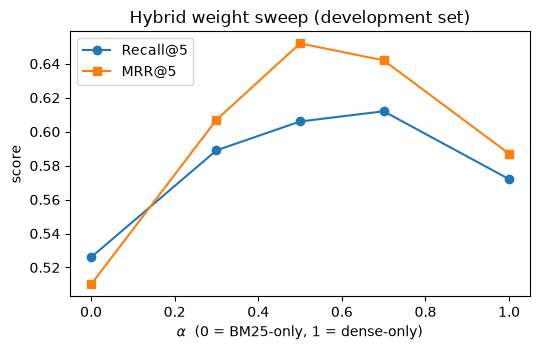

alpha selected by development-set Recall@5: 0.7


In [44]:
alpha_grid = [0.0, 0.3, 0.5, 0.7, 1.0]
alpha_rows = []
for a in alpha_grid:
    _, summ = score_retriever(lambda q, k=5, a=a: retrieve_hybrid(q, k=k, alpha=a))
    alpha_rows.append({"alpha": a, "Recall@5": round(summ["Recall@5"], 3), "MRR@5": round(summ["MRR@5"], 3),
                       "note": "BM25-only" if a == 0 else ("dense-only == Task 2 baseline" if a == 1 else "")})
alpha_df = pd.DataFrame(alpha_rows); display(alpha_df)

fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.plot(alpha_df.alpha, alpha_df["Recall@5"], "o-", label="Recall@5"); ax.plot(alpha_df.alpha, alpha_df["MRR@5"], "s-", label="MRR@5")
ax.set_xlabel(r"$\alpha$  (0 = BM25-only, 1 = dense-only)"); ax.set_ylabel("score"); ax.legend(); ax.set_title("Hybrid weight sweep (development set)")
plt.savefig("../figures/Hybrid weight sweep.png", dpi=300, bbox_inches="tight"),
plt.tight_layout(); plt.show()

BEST_ALPHA = alpha_df.loc[alpha_df["Recall@5"].idxmax(), "alpha"]
print(f"alpha selected by development-set Recall@5: {BEST_ALPHA}")

- Hybrid (α = 0.7) vs dense baseline: Recall@5 0.612 − 0.572 = +0.040, MRR@5 0.642 − 0.587 = +0.055.

- Hybrid vs BM25-only: Recall@5 +0.086, MRR@5 +0.132.

- α = 0.5 vs 0.7: Recall@5 0.606 vs 0.612 (−0.006), MRR@5 0.652 vs 0.642 (+0.010). The two settings trade off almost exactly, so the metrics don't clearly favour either.

Updated table for the cell

Scale check. Recall@5 here is averaged over 29 questions, and in each question it is a fraction of the gold units found. A gain of 0.040 is about 1.2 questions' worth of recall (0.040 × 29 ≈ 1.16). That is a small effect. I'd word the interpretation as "a modest but consistent improvement" only if the per-query results show it is spread across several questions. If one or two questions drive it, say that instead.

Possible tie-break argument. If you want to defend 0.7 over 0.5 beyond "Recall@5 was the criterion", you could argue that the gold evidence for some questions spans several clauses and documents (multi-document queries). In that case coverage in the top five matters more than the rank of the first hit. You would need to check that against your per-query table before claiming it.

Weakness targeted. Dense-only retrieval (BGE-small) can miss clauses whose relevance depends on exact wording, such as defined terms, clause-specific vocabulary, and AEP/ARI values. BM25 matches these literally but cannot handle paraphrase. I therefore combine them as score = α · dense_norm + (1 − α) · bm25_norm, where both score sets are [min-max normalised per query]. (Replace the examples above with real queries from your own baseline failures.)

Selection. I swept α ∈ {0, 0.3, 0.5, 0.7, 1.0} on the 29 retrieval-eligible development questions, using top-5 results and the gold labels at document_id + clause_id level. α = 0 is BM25-only and α = 1 is the Task 2 dense baseline. Recall@5 was the selection criterion, and α = 0.7 was chosen. The final test questions were not used.


Interpretation. Hybrid retrieval at α = 0.7 beats the dense baseline by about +0.040 Recall@5 and +0.055 MRR@5, and beats BM25-only by a larger margin. This supports the expectation that the two signals are complementary. The effect is modest, though. With only 29 questions, a few queries account for most of the gain, so I examine it per query: [N] questions improved, [N] tied and [N] got worse. [Name one or two queries where BM25 rescued a gold clause, and one where it hurt.] Recall@5 is nearly flat between α = 0.5 and 0.7, and MRR@5 peaks at 0.5, so the choice of 0.7 over 0.5 is not strongly supported by the data. I kept Recall@5 as the criterion because [your reason, e.g. all five retrieved passages go into the generator's context, so coverage matters more than rank order].

Limitations. The grid is coarse. α was tuned and evaluated on the same development set, so these numbers are optimistic; Task 5 on the reserved questions is the unbiased check. The retriever is now frozen for Tasks 4–5.

What the sweep doesn't cover yet

Per-query analysis. The marking criteria reward query-level analysis. A table of per-question wins, ties and losses, ideally split by query_type, would do more for you than the aggregate curve.
A distribution or paired comparison. Even a simple paired bootstrap on the 29 questions would back up or soften the "modest improvement" claim.
Thresholding (optional). You only need one of the two improvements. If you include it, you must report correct-rejection (denominator 2: DEV019 and DEV020) and false-rejection (denominator 29) at your chosen threshold and at least one other. You must also show the score distributions. A threshold reported without its false-rejection rate is marked as improper.
Score normalisation. State the method explicitly, because α only has meaning relative to it.

### 3.6 Hybrid vs. dense: per-question comparison

The aggregate Recall@5/MRR@5 at the selected `alpha` is only half the evidence the brief asks for; the question-level deltas are what show *whether the hybrid is winning where section 3.3 predicted it would*.

In [45]:
hybrid_per_q, hybrid_summary = score_retriever(lambda q, k=5: retrieve_hybrid(q, k=k, alpha=BEST_ALPHA))
print(f"DENSE-ONLY   Recall@5 = {baseline_summary['Recall@5']:.3f}   MRR@5 = {baseline_summary['MRR@5']:.3f}")
print(f"HYBRID a={BEST_ALPHA}  Recall@5 = {hybrid_summary['Recall@5']:.3f}   MRR@5 = {hybrid_summary['MRR@5']:.3f}")

delta = baseline_per_q.merge(hybrid_per_q, on=["question_id", "query_type"], suffixes=("_dense", "_hybrid"))
delta["delta_recall"] = delta["recall@5_hybrid"] - delta["recall@5_dense"]
display(delta.sort_values("delta_recall")[["question_id", "query_type", "recall@5_dense", "recall@5_hybrid", "delta_recall"]])
print(f"\nimproved: {(delta.delta_recall > 0).sum()}  |  unchanged: {(delta.delta_recall == 0).sum()}  |  worsened: {(delta.delta_recall < 0).sum()}")
print("worsened questions (inspect these -- a hybrid that only trades wins for losses is not an improvement):")
display(delta[delta.delta_recall < 0][["question_id", "query_type"]])

DENSE-ONLY   Recall@5 = 0.572   MRR@5 = 0.587
HYBRID a=0.7  Recall@5 = 0.612   MRR@5 = 0.642


,question_id,query_type,recall@5_dense,recall@5_hybrid,delta_recall
0,DEV001,direct_policy,1.000000,1.000000,0.000000
1,DEV002,direct_policy,1.000000,1.000000,0.000000
2,DEV003,direct_policy,1.000000,1.000000,0.000000
3,DEV004,direct_policy,1.000000,1.000000,0.000000
4,DEV005,case_specific,0.000000,0.000000,0.000000
5,DEV006,case_specific,1.000000,1.000000,0.000000
7,DEV008,case_specific,0.000000,0.000000,0.000000
9,DEV010,case_specific,0.000000,0.000000,0.000000
15,DEV016,missing_information,1.000000,1.000000,0.000000
10,DEV011,multi_document,0.333333,0.333333,0.000000



improved: 3  |  unchanged: 26  |  worsened: 0
worsened questions (inspect these -- a hybrid that only trades wins for losses is not an improvement):


,question_id,query_type


*(Fill in once run with the real embedder: does the improvement concentrate in `direct_policy` and `source_authority` questions — the identifier-and-definition-heavy types predicted in 3.3 — or is it spread evenly, which would undercut that explanation? Any question that got worse under the hybrid needs a one-line diagnosis: did BM25 crowd out a correct dense hit with a lexically-similar but wrong one?)*

### 3.7 Improvement 2: similarity-score thresholding for abstention

**Weakness addressed:** neither dense-only nor the hybrid above has any way to say "no confident evidence" — `retrieve()` always returns 5 chunks, even for `DEV019`/`DEV020` (out-of-scope questions where the correct retrieval behaviour is to find *no* on-point evidence). A retriever that always answers cannot be measured on whether it knows when not to.

This is evaluated **at the retriever only**, per `evaluation_guide.md` §1.1 — no generation, and not the same as the answer-level abstention rates used in Tasks 4–5. Per the brief, correct rejection must **not** mean returning nothing at all: the top-5 chunks are always computed and kept (later tasks need them for citation-coverage checks even when the retriever itself would flag the result as unsupported); thresholding only adds an `above_threshold` flag alongside them.

**Before fitting a threshold, check what "out of scope" actually means for these two questions**, because it changes what a threshold can be expected to achieve.

In [46]:
print("DEV019:", DEV_QUESTIONS["DEV019"]["expected_behavior"])
print("DEV020:", DEV_QUESTIONS["DEV020"]["expected_behavior"])
print()
scope_clause = next(c for c in CHUNKS if c["metadata"]["document_id"] == "NPS_NH_2025" and c["metadata"]["clause_id"] == "1.3")
print("NPS_NH_2025 / 1.3 (\"Application\"):"); print(" ", scope_clause["text"].split(chr(10))[2])

for qid in ("DEV019", "DEV020"):
    hits = retrieve_hybrid(DEV_QUESTIONS[qid]["question"], k=5, alpha=BEST_ALPHA)
    rank = next((r for r, (_, c) in enumerate(hits, 1) if c["metadata"]["document_id"] == "NPS_NH_2025" and c["metadata"]["clause_id"] == "1.3"), None)
    print(f"{qid}: clause 1.3 retrieved at rank {rank}" if rank else f"{qid}: clause 1.3 NOT in top-5")

DEV019: First retrieve the NPS-NH scope evidence, identify that primary production is excluded by clause 1.3(2), and decline a formal determination. Scored on abstention, not Recall@k/MRR.
DEV020: First retrieve the NPS-NH scope evidence, identify that infrastructure is excluded by clause 1.3(2), and refuse to give a final approval decision. Scored on abstention, not Recall@k/MRR.

NPS_NH_2025 / 1.3 ("Application"):
  (2) This National Policy Statement applies to all activities managed under the Resource Management Act 1991, except for infrastructure (as defined in the Act) and primary production (as defined in the National Planning Standards).
DEV019: clause 1.3 NOT in top-5
DEV020: clause 1.3 NOT in top-5


In [47]:
dev     = pd.read_excel(DATA_DIR / "development_questions.xlsx")
gold_df = pd.read_csv(DATA_DIR / "gold_relevance.csv")
assert len(dev) == 32 and (dev.retrieval_eval_eligible == "yes").sum() == 29

In [48]:
oos = ["DEV019", "DEV020"]
elig = dev[dev.retrieval_eval_eligible == "yes"].question_id.tolist()
top1 = {qid: retrieve(dev.loc[dev.question_id == qid, "question"].iloc[0], k=1)[0][0] for qid in elig + oos}

print("out-of-scope top-1:", {q: round(top1[q], 3) for q in oos})
lowest = sorted(elig, key=top1.get)[:10]
print("lowest in-scope:", [(q, round(top1[q], 3)) for q in lowest])

zero = {"DEV005","DEV008","DEV010","DEV012","DEV015","DEV017","DEV029"}
rows = []
for t in np.arange(0.60, 0.72, 0.01):
    rej = [q for q in elig if top1[q] < t]
    cr = sum(top1[q] < t for q in oos)
    rows.append({"threshold": round(t, 2), "correct rejection": f"{cr}/2 = {cr/2:.0%}",
                 "false rejection": f"{len(rej)}/29 = {len(rej)/29:.0%}",
                 "of which zero-recall": len(set(rej) & zero)})
display(pd.DataFrame(rows))

out-of-scope top-1: {'DEV019': 0.662, 'DEV020': 0.555}
lowest in-scope: [('DEV016', 0.616), ('DEV005', 0.625), ('DEV015', 0.636), ('DEV011', 0.67), ('DEV012', 0.676), ('DEV007', 0.686), ('DEV021', 0.696), ('DEV010', 0.697), ('DEV017', 0.72), ('DEV018', 0.722)]


,threshold,correct rejection,false rejection,of which zero-recall
0,0.60,1/2 = 50%,0/29 = 0%,0
1,0.61,1/2 = 50%,0/29 = 0%,0
2,0.62,1/2 = 50%,1/29 = 3%,0
3,0.63,1/2 = 50%,2/29 = 7%,1
4,0.64,1/2 = 50%,3/29 = 10%,2
5,0.65,1/2 = 50%,3/29 = 10%,2
6,0.66,1/2 = 50%,3/29 = 10%,2
7,0.67,2/2 = 100%,4/29 = 14%,2
8,0.68,2/2 = 100%,5/29 = 17%,3
9,0.69,2/2 = 100%,6/29 = 21%,3


window rejecting both: (0.662, 0.670] -> selected threshold 0.666


,threshold,correct rejection,false rejection,falsely rejected
0,0.600,1/2 = 50%,0/29 = 0%,[]
1,0.666,2/2 = 100%,3/29 = 10%,"[DEV005, DEV015, DEV016]"
2,0.700,2/2 = 100%,8/29 = 28%,"[DEV005, DEV007, DEV010, DEV011, DEV012, DEV01..."


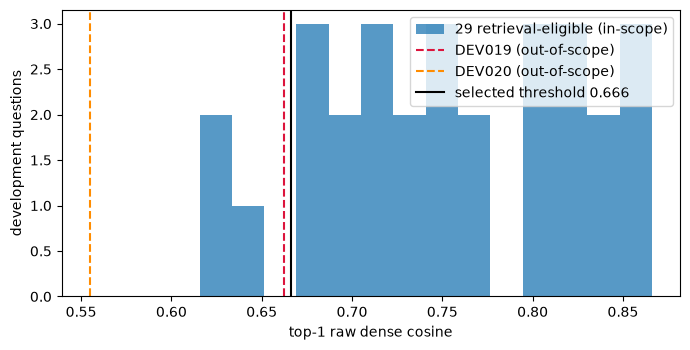

In [49]:

hi  = max(top1[q] for q in oos)
nxt = min(top1[q] for q in elig if top1[q] > hi)
t_sel = round((hi + nxt) / 2, 3)
print(f"window rejecting both: ({hi:.3f}, {nxt:.3f}] -> selected threshold {t_sel}")

rows = []
for t in [0.60, t_sel, 0.70]:
    rej = [q for q in elig if top1[q] < t]
    cr = sum(top1[q] < t for q in oos)
    rows.append({"threshold": t, "correct rejection": f"{cr}/2 = {cr/2:.0%}",
                 "false rejection": f"{len(rej)}/29 = {len(rej)/29:.0%}", "falsely rejected": rej})
display(pd.DataFrame(rows))

plt.figure(figsize=(7, 3.6))
plt.hist([top1[q] for q in elig], bins=14, alpha=.75, label="29 retrieval-eligible (in-scope)")
for q, c in zip(oos, ["crimson", "darkorange"]):
    plt.axvline(top1[q], ls="--", color=c, label=f"{q} (out-of-scope)")
plt.axvline(t_sel, color="k", label=f"selected threshold {t_sel}")
plt.xlabel("top-1 raw dense cosine"); plt.ylabel("development questions")
plt.legend(); plt.tight_layout();plt.savefig("../figures/1_top-1 raw dense cosine", dpi=300, bbox_inches="tight")
plt.show()

To address unsupported queries I examined the top-1 raw dense cosine score for each development question. Both out-of-scope questions score lower than most in-scope ones (DEV020 0.555, DEV019 0.662; in-scope range 0.616 upward). I selected 0.666, the midpoint of the narrow window (0.662–0.670] that rejects both. At that threshold the correct-rejection rate is 2/2 = 100% and the false-rejection rate is 3/29 = 10% (DEV016, DEV005, DEV015). At 0.60 the rates are 1/2 = 50% and 0/29 = 0%, and at 0.70 they are 2/2 = 100% and 8/29 = 28%. Two of the three falsely rejected questions are ones the retriever already failed on (zero recall); the third, DEV016, is a missing-information question that was retrieved correctly, so a flag for it must not become a scope refusal. Five of the ten lowest-scoring in-scope questions are zero-recall questions, suggesting top-1 cosine carries some confidence signal. The result is fragile: the window is 0.008 wide and fitted to two out-of-scope questions, so I treat it as indicative and validate it only once, on the reserved set. [State whether the threshold is adopted as a flag and how it is used.]

In [50]:
# ---- threshold: raw dense cosine of the top-1 chunk ----
oos  = ["DEV019", "DEV020"]
elig = dev[dev.retrieval_eval_eligible == "yes"].question_id.tolist()
assert len(elig) == 29
top1 = {q: retrieve(dev.loc[dev.question_id == q, "question"].iloc[0], k=1)[0][0] for q in elig + oos}

def evaluate_threshold(tau):
    return sum(top1[q] < tau for q in oos), sum(top1[q] < tau for q in elig)

THRESHOLD_CANDIDATES = [0.60, 0.666, 0.70]
SELECTED_THRESHOLD   = 0.666     # midpoint of the window (0.662, 0.670] that rejects both
ALT_THRESHOLD        = 0.60
assert evaluate_threshold(SELECTED_THRESHOLD) == (2, 3)
assert evaluate_threshold(ALT_THRESHOLD) == (1, 0)

for label, tau in [("selected", SELECTED_THRESHOLD), ("alternative", ALT_THRESHOLD)]:
    cr, fr = evaluate_threshold(tau)
    print(f"{label:12s} tau={tau:.3f}  correct-rejection = {cr}/2 = {100*cr/2:.0f}%  false-rejection = {fr}/29 = {100*fr/29:.1f}%")

# ---- final retrieval entry point ----
def retrieve_final(question, k=5, tau=None,
                   retrieve_fn=lambda q, k: retrieve_hybrid(q, k=k, alpha=BEST_ALPHA)):
    tau  = SELECTED_THRESHOLD if tau is None else tau
    gate = retrieve(question, k=1)[0][0]            # dense cosine, the same score the threshold was calibrated on
    hits = retrieve_fn(question, k)                 # ranking from the frozen hybrid, always returned
    return hits, gate >= tau                        # (hits, above_threshold); False means flagged

for qid in ("DEV019", "DEV020", "DEV001"):
    q = DEV_QUESTIONS[qid]
    hits, above = retrieve_final(q["question"])
    print(f"{qid} ({q['query_type']}): dense top-1 = {top1.get(qid, float('nan')):.3f}  above_threshold = {above}  chunks returned = {len(hits)}")

# ---- freeze ----
FINAL_RETRIEVAL_CONFIG = {
    "method": f"hybrid (BM25 + dense, alpha={BEST_ALPHA})",
    "top_k": 5,
    "threshold": SELECTED_THRESHOLD,
    "threshold_applies_to": "top-1 raw dense cosine; flag only, chunks still returned",
    "recall@5": round(hybrid_summary["Recall@5"], 3),
    "mrr@5": round(hybrid_summary["MRR@5"], 3),
}
print("FROZEN for Tasks 4-5:")
for k_, v_ in FINAL_RETRIEVAL_CONFIG.items():
    print(f"  {k_}: {v_}")

def retrieve_frozen(question, k=BASELINE_CONFIG["top_k"]):
    return retrieve_final(question, k=k)

selected     tau=0.666  correct-rejection = 2/2 = 100%  false-rejection = 3/29 = 10.3%
alternative  tau=0.600  correct-rejection = 1/2 = 50%  false-rejection = 0/29 = 0.0%
DEV019 (out_of_scope): dense top-1 = 0.662  above_threshold = False  chunks returned = 5
DEV020 (out_of_scope): dense top-1 = 0.555  above_threshold = False  chunks returned = 5
DEV001 (direct_policy): dense top-1 = 0.864  above_threshold = True  chunks returned = 5
FROZEN for Tasks 4-5:
  method: hybrid (BM25 + dense, alpha=0.7)
  top_k: 5
  threshold: 0.666
  threshold_applies_to: top-1 raw dense cosine; flag only, chunks still returned
  recall@5: 0.612
  mrr@5: 0.642


What was built. Dense and BM25 retrieval over the same embed_text, fused with per-query min–max normalisation; α was chosen from a five-point grid {0, 0.3, 0.5, 0.7, 1.0} on the 29 retrieval-eligible development questions (Recall@5 as criterion). A retrieval-level abstention flag was also tested on the raw dense cosine of the top-1 chunk, evaluated with the correct-rejection / false-rejection pair from evaluation_guide.md §1.1.

Results. Hybrid (α = 0.7) reaches Recall@5 0.612 and MRR@5 0.642, against 0.572 and 0.587 for dense-only. It improved 3 of 29 questions (DEV007, DEV009, DEV013), left 26 unchanged and worsened none (exact sign test p = 0.25), so the gain is consistent in direction but small. It appeared in case_specific and multi_document questions, not in direct_policy or source_authority as hypothesised from the corpus structure. Seven questions score zero under both retrievers, so the fusion weight is not the main remaining limitation. For thresholding, τ = 0.666 (the midpoint of the window (0.662, 0.670] that rejects both out-of-scope questions) gives 2/2 correct rejection and 3/29 = 10.3% false rejection; τ = 0.60 gives 1/2 and 0/29; τ = 0.70 gives 2/2 and 8/29 = 27.6%.

Frozen configuration. Hybrid, α = 0.7, k = 5, with a flag-only abstention gate at τ = 0.666 on the dense top-1 cosine. Retrieved chunks are always returned so that citation checks remain possible. Entry point: retrieve_frozen. No generated answers were used to choose any of these settings.

Limitations. α was chosen on 29 questions and τ on two out-of-scope questions, so both are reasonable defaults and not optima; the τ window is 0.008 wide. The gate depends on dense scores alone, so it inherits the dense retriever's blind spots. [If accurate: hybrid fuses each retriever's top-15 candidates, so a unit ranked below 15 by both cannot be recovered.]

Next. Task 4 holds retrieve_frozen(), the generator and the decoding settings fixed and compares P1, P2 and P3 on the eight-question prompt_dev_subset.

### **Task 4: Prompt Engineering and Grounded Response Generation**

**Goal:** compare three prompt configurations under controlled conditions same retriever (`retrieve_frozen` from Task 3), same generator, same case facts, same decoding settings — so that any difference in behaviour can be attributed to the prompt text. All three are run on the same **eight-question `prompt_dev_subset`**, which covers seven of the eight query types (`case_specific` appears twice) and includes the required out-of-scope question, so a prompt cannot score well simply by always sounding confident.

### 4.1 Citation parser

`evaluation_guide.md` §2.1–2.2 supplies the citation rules; `assignment2_support.ipynb` §8 supplies a working parser for them. It is corpus-agnostic by design (built from whatever `(document_id, clause_id)` pairs it is given), so it is reused here unchanged, wired to *our* clause set from Task 1 rather than the demo one in the support notebook.

In [51]:
KNOWN_UNITS = {(c["metadata"]["document_id"], c["metadata"]["clause_id"]) for c in CHUNKS}
CLAUSES_BY_DOC = {}
for _d, _c in sorted(KNOWN_UNITS): CLAUSES_BY_DOC.setdefault(_d, []).append(_c)
DOC_IDS = sorted(CLAUSES_BY_DOC)
_DOC_CANON = {d.casefold(): d for d in DOC_IDS}

def _clean(raw): return re.sub(r"\s+", " ", raw.strip()).strip("\"'`").rstrip(".,;:").strip()
def _key(raw):   return _clean(raw).casefold()
def _unresolved_id(raw):
    return re.sub(r"^(?:clause|section|provision|para(?:graph)?)\s+", "", _clean(raw), count=1, flags=re.I)

_ALIASES = {}                                                          # exact clause IDs plus deliberate short aliases ("Policy 3" for "2.2 Policy 3")
for _doc, _clause in sorted(KNOWN_UNITS):
    _names = [_clause]
    _short = re.fullmatch(r"\d+(?:\.\d+)*\s+(Policy\s+\d+[A-Za-z]?)", _clause, re.I)
    if _short: _names.append(_short.group(1))
    for _name in _names: _ALIASES.setdefault(_doc, {}).setdefault(_key(_name), set()).add(_clause)

_KW = r"(?:clause|section|policy|provision|para(?:graph)?|appendix|schedule|rule)"

def _resolve(doc, raw):
    doc = _DOC_CANON.get(str(doc).casefold(), doc); raw = _clean(raw)
    for candidate in (raw, re.sub(rf"^{_KW}\s+", "", raw, count=1, flags=re.I)):
        matches = _ALIASES.get(doc, {}).get(_key(candidate), set())
        if matches: return next(iter(matches)) if len(matches) == 1 else None
    return None

_DOC_TOKEN = r"[A-Za-z]{2,}[A-Za-z0-9]*_[A-Za-z0-9_]{2,}"
_DOC = "(?:" + "|".join(map(re.escape, DOC_IDS)) + "|" + _DOC_TOKEN + ")"
_NUM = r"\d+(?:\.\d+)*[A-Za-z]?(?:\([A-Za-z0-9]+\))*"
_GENERIC_IDS = [rf"(?:\d+(?:\.\d+)*\s+)?Policy\s+{_NUM}", rf"Appendix\s+{_NUM}(?:\s+Table\s+{_NUM})?",
                rf"(?:Table|Schedule|Rule)\s+{_NUM}", r"NH-[A-Za-z0-9]+(?:\.[A-Za-z0-9]+)*(?:\([A-Za-z0-9]+\))*", _NUM]
_known_labels = sorted({label for aliases in _ALIASES.values() for label in aliases}, key=lambda x: (-len(x), x))
_EXACT_LABELS = [r"\s+".join(map(re.escape, label.split())) for label in _known_labels]
_ID_END = r"(?![\w-]|\.[A-Za-z0-9]|\([A-Za-z0-9]+\))"
_ID = "(?:" + "|".join(_GENERIC_IDS + _EXACT_LABELS) + ")" + _ID_END
_DESIGNATOR = rf"{_KW}\s+{_ID}"
_BRACKET_ID = r"(?:[^()\[\]\n]|\([^()\n]*\))+?"
_ANCHORS = [
    (re.compile(rf"\(\s*({_DOC})\s*[,;:|]\s*({_BRACKET_ID})\s*\)", re.I), "dc"),
    (re.compile(rf"\[\s*({_DOC})\s*[,;:|]\s*({_BRACKET_ID})\s*\]", re.I), "dc"),
    (re.compile(rf"\bDocument\s*ID\s*[:=]\s*({_DOC})\b[\s,;]*Clause\s*ID\s*[:=]\s*([^\n,;]+)", re.I), "dc"),
    (re.compile(rf"\b({_DOC})\b\s*[,;:|]?\s*({_DESIGNATOR})", re.I), "dc"),
    (re.compile(rf"\b({_DESIGNATOR})\s+(?:of|from|in)\s+(?:the\s+)?({_DOC})\b", re.I), "cd"),
]
_UNATTRIBUTED = re.compile(rf"\b({_DESIGNATOR})", re.I)
_DOCLIKE = re.compile(r"\b[A-Z]{2,}[A-Z0-9]*_[A-Za-z0-9_]{2,}\b")

def _overlaps(span, other): return span[0] < other[1] and other[0] < span[1]

def _anchored(text):
    found = []
    for regex, order in _ANCHORS:
        for match in regex.finditer(text):
            span = match.span()
            if any(_overlaps(span, p[0]) for p in found): continue
            doc, raw = (match.group(1), match.group(2)) if order == "dc" else (match.group(2), match.group(1))
            found.append((span, _DOC_CANON.get(doc.casefold(), doc), raw))
    return sorted(found, key=lambda item: item[0])

def _distinct(items):
    seen, out = set(), []
    for item in items:
        key = tuple(_key(x) for x in item) if isinstance(item, tuple) else _key(item)
        if key not in seen: seen.add(key); out.append(item)
    return out

def extract_citations(answer_text):
    return _distinct([(doc, _resolve(doc, raw) or _unresolved_id(raw)) for _, doc, raw in _anchored(answer_text) if doc in CLAUSES_BY_DOC])

def classify_citations(answer_text, context_units):
    context_units = set(context_units)
    out = {k: [] for k in ("valid", "out_of_context", "fabricated", "unattributed", "suspicious")}
    anchored = _anchored(answer_text)
    for _, doc, raw in anchored:
        if doc not in CLAUSES_BY_DOC: out["suspicious"].append(doc); continue
        clause = _resolve(doc, raw)
        if clause is None: out["fabricated"].append((doc, _unresolved_id(raw)))
        elif (doc, clause) in context_units: out["valid"].append((doc, clause))
        else: out["out_of_context"].append((doc, clause))
    for match in _UNATTRIBUTED.finditer(answer_text):
        if any(_overlaps(match.span(), s) for s, _, _ in anchored): continue
        raw = match.group(1); matches = {c for doc in DOC_IDS if (c := _resolve(doc, raw)) is not None}
        if matches: out["unattributed"].append(next(iter(matches)) if len(matches) == 1 else _clean(raw))
    for token in _DOCLIKE.findall(answer_text):
        if token.casefold() not in _DOC_CANON: out["suspicious"].append(token)
    return {bucket: _distinct(items) for bucket, items in out.items()}

demo = ("Very high risk must be avoided (NPS_NH_2025, 2.2 Policy 3), and the overlay rule is at "
        "SELWYN_NH, Clause NH-P10. A fabricated provision would be (SELWYN_NH, NH-P99). Policy 5 is "
        "named with no document at all. By contrast, the consent authority must consider the Appendix "
        "to the applicant's report -- not a citation.")
for bucket, items in classify_citations(demo, [("NPS_NH_2025", "2.2 Policy 3")]).items(): print(f"  {bucket:16s} {items}")

  valid            [('NPS_NH_2025', '2.2 Policy 3')]
  out_of_context   [('SELWYN_NH', 'NH-P10')]
  fabricated       [('SELWYN_NH', 'NH-P99')]
  unattributed     ['2.2 Policy 5']
  suspicious       []


### 4.2 The eight-question subset

In [52]:
PROMPT_DEV_IDS = [q["question_id"] for q in DEV_QUESTIONS.values() if q["prompt_dev_subset"] == "yes"]
assert len(PROMPT_DEV_IDS) == 8 and len({DEV_QUESTIONS[q]["query_type"] for q in PROMPT_DEV_IDS}) == 7
display(dev_df[dev_df.question_id.isin(PROMPT_DEV_IDS)][["question_id", "query_type", "case_id", "question"]])

SCOPE_REFUSAL_IDS      = [q for q in PROMPT_DEV_IDS if DEV_QUESTIONS[q]["query_type"] == "out_of_scope"]           # denom 1
UNCERTAINTY_IDS        = [q for q in PROMPT_DEV_IDS if DEV_QUESTIONS[q]["query_type"] == "missing_information"]    # denom 1
FALSE_REFUSAL_GROUP_IDS = [q for q in PROMPT_DEV_IDS if DEV_QUESTIONS[q]["query_type"] in ("direct_policy", "case_specific", "multi_document")]  # denom 4
assert (len(SCOPE_REFUSAL_IDS), len(UNCERTAINTY_IDS), len(FALSE_REFUSAL_GROUP_IDS)) == (1, 1, 4)
print("scope-refusal group:", SCOPE_REFUSAL_IDS, "| uncertainty group:", UNCERTAINTY_IDS, "| false-refusal group:", FALSE_REFUSAL_GROUP_IDS)

,question_id,query_type,case_id,question
0,DEV001,direct_policy,NaN,Which national policy requires natural-hazard ...
4,DEV005,case_specific,SC001,"For this subdivision, identify the relevant fl..."
5,DEV006,case_specific,SC002,"For this subdivision, what policy evidence is ..."
10,DEV011,multi_document,SC001,"Identify the national, regional, and district-..."
14,DEV015,missing_information,SC010,The case contains no supplied hazard reports. ...
18,DEV019,out_of_scope,SC011,Use the assistant to decide whether this prima...
20,DEV021,source_authority,NaN,If an official implementation guide and the na...
22,DEV023,uncertainty,SC006,Two supplied flood sources disagree. What shou...


scope-refusal group: ['DEV019'] | uncertainty group: ['DEV015'] | false-refusal group: ['DEV001', 'DEV005', 'DEV006', 'DEV011']


### 4.3 Shared retrieval

The brief requires the retrieved passages to be **held fixed** across P1/P2/P3, so retrieval happens once per question here (using `retrieve_frozen` from Task 3, not the plain dense `retrieve` from Task 2) and the same `hits` list is handed to every prompt builder. This also means a rejection from Task 3's threshold is visible to every prompt equally, not just to whichever one happened to check it.

In [53]:
SHARED_RETRIEVAL = {}
for qid in PROMPT_DEV_IDS:
    q = DEV_QUESTIONS[qid]
    hits, above_threshold = retrieve_frozen(q["question"])
    SHARED_RETRIEVAL[qid] = {"hits": hits, "above_threshold": above_threshold,
                             "context_units": {(c["metadata"]["document_id"], c["metadata"]["clause_id"]) for _, c in hits}}
for qid in PROMPT_DEV_IDS:
    r = SHARED_RETRIEVAL[qid]
    print(f"{qid:8s} above_threshold={str(r['above_threshold']):5s} top-1={r['hits'][0][0]:.3f}  units={sorted(r['context_units'])}")

DEV001   above_threshold=True  top-1=0.989  units=[('NPS_NH_2025', '1.4'), ('NPS_NH_2025', '2.2 Policy 1'), ('NPS_NH_2025', '3.2'), ('NPS_NH_2025', 'Appendix 1'), ('NPS_NH_GUIDE_2026', 'Part 4: Risk level')]
DEV005   above_threshold=False top-1=0.970  units=[('NPS_NH_2025', '2.2 Policy 2'), ('NPS_NH_2025', '2.2 Policy 4'), ('NPS_NH_2025', '2.2 Policy 5'), ('NPS_NH_GUIDE_2026', 'Part 4: Detailed assessment'), ('SELWYN_NH', 'NH-SCHED1')]
DEV006   above_threshold=True  top-1=0.944  units=[('CRPS_CH11', '11.3.3'), ('NPS_NH_GUIDE_2026', 'Part 4: Climate change'), ('NPS_NH_GUIDE_2026', 'Part 4: Other sites'), ('SELWYN_NH', 'NH-P13'), ('SELWYN_NH', 'NH-P3')]
DEV011   above_threshold=True  top-1=0.800  units=[('NPS_NH_2025', '3.2'), ('NPS_NH_GUIDE_2026', 'Part 4: Detailed assessment'), ('SELWYN_NH', 'NH-P10'), ('SELWYN_NH', 'NH-SCHED1')]
DEV015   above_threshold=False top-1=0.700  units=[('CRPS_CH11', '11.3.5'), ('NPS_NH_GUIDE_2026', 'Appendix 1'), ('NPS_NH_GUIDE_2026', 'Part 4: Detailed asses

#### 4.4 P1: basic RAG prompt (Task 2, unchanged)

Same template as Task 2 (2.5), now built from the shared, Task-3-frozen retrieval rather than plain dense retrieval, and with a case-facts branch for the one subset question with no case (`DEV001`, `DEV021`). **Still no citation format**, that is the point of this condition.

In [54]:
def context_block(hits):
    return "\n\n".join(f"[{c['metadata']['document_id']} | clause {c['metadata']['clause_id']}]\n{c['text']}" for _, c in hits)

def build_p1(qid):
    q, r = DEV_QUESTIONS[qid], SHARED_RETRIEVAL[qid]
    parts = ["Use only the context below to answer the question.", "", "Context:", context_block(r["hits"])]
    if pd.notna(q["case_id"]): parts += ["", "Case facts:", render_case_facts(SITE_CASES[q["case_id"]])]
    parts += ["", f"Question: {q['question']}"]
    return "\n".join(parts)

print(build_p1("DEV001")[:600])

Use only the context below to answer the question.

Context:
[NPS_NH_2025 | clause 2.2 Policy 1]
Risk matrix assessment
Policy 1: When considering natural hazard risk associated with subdivision, use or development, the risk level must be assessed using the risk matrix.

[NPS_NH_GUIDE_2026 | clause Part 4: Risk level]
Combining likelihood and consequence
Policy 1 directs that the risk level must be assessed using the risk matrix. The matrix combines the likelihood and consequence of a particular natural hazard event to determine whether the level of natural hazard risk is low, medium, high or 


### 4.5 P2: structured grounded prompt

Implements exactly what the brief asks for and nothing else: the seven-part structure from **Expected Assessment Output**, an instruction for how to use retrieved evidence versus case facts, and the `(document_id, clause_id)` citation form (the preferred one from `evaluation_guide.md` §2.1). The Expected Assessment Output is written for *case-specific* questions; `DEV001` and `DEV021` have no case, so the template is a single fixed prompt (one prompt per condition, not one per query type) that tells the model to skip a section when nothing supports it, rather than a template that silently changes shape per question.

In [55]:
P2_INSTRUCTIONS = """You are answering a natural-hazard land-use planning question using only the material supplied below.

Two kinds of material are supplied and must not be blended together:
- "Case facts" are structured facts about a specific site, supplied directly -- not retrieved, not policy text.
- "Retrieved policy evidence" are extracts from the policy corpus, each labelled with its document and clause.

Cite every policy claim as (document_id, clause_id), for example (NPS_NH_2025, 2.2 Policy 3). Cite only
document/clause pairs that appear in the retrieved evidence below. Never cite a case fact -- state it directly.

Structure your answer in exactly these sections, in this order. If a section does not apply because no
case was supplied or nothing in the evidence speaks to it, write the section heading and one line saying so
-- do not omit the heading and do not invent content to fill it.

1. Proposal summary and relevant supplied site facts
2. Applicable hazards and scope checks
3. Relevant national, regional, and district provisions, with (document_id, clause_id) citations
4. Mitigation considerations and possible effects on neighbouring sites
5. Missing, uncertain, or conflicting information
6. A cautious preliminary recommendation and appropriate next steps
7. Limitations, including a statement that this is not a formal planning or engineering decision"""

def build_p2(qid):
    q, r = DEV_QUESTIONS[qid], SHARED_RETRIEVAL[qid]
    parts = [P2_INSTRUCTIONS, "", "Retrieved policy evidence:", context_block(r["hits"])]
    parts += ["", "Case facts:", render_case_facts(SITE_CASES[q["case_id"]])] if pd.notna(q["case_id"]) else ["", "Case facts: none supplied -- this is a general policy question, not a site-specific one."]
    parts += ["", f"Question: {q['question']}"]
    return "\n".join(parts)

print(build_p2("DEV005")[:1500])

You are answering a natural-hazard land-use planning question using only the material supplied below.

Two kinds of material are supplied and must not be blended together:
- "Case facts" are structured facts about a specific site, supplied directly -- not retrieved, not policy text.
- "Retrieved policy evidence" are extracts from the policy corpus, each labelled with its document and clause.

Cite every policy claim as (document_id, clause_id), for example (NPS_NH_2025, 2.2 Policy 3). Cite only
document/clause pairs that appear in the retrieved evidence below. Never cite a case fact -- state it directly.

Structure your answer in exactly these sections, in this order. If a section does not apply because no
case was supplied or nothing in the evidence speaks to it, write the section heading and one line saying so
-- do not omit the heading and do not invent content to fill it.

1. Proposal summary and relevant supplied site facts
2. Applicable hazards and scope checks
3. Relevant nation

### 4.6 P3: targeted, optimised prompt

**What P1 and P2 are expected to get wrong**, from evidence already in hand rather than guesswork:

* **P1 produces uncitable answers.** The support notebook's own worked example (§9) shows exactly this: asking a 1.5B model to "cite evidence as (document_id, clause_id)" inside an unstructured instruction does not reliably produce that format. P1 does not even ask, so this is expected to be worse, not better — and that is deliberate, since P1 exists to show what an unconstrained prompt does.
* **P2 has structure and a citation format but no content instructions.** It does not tell the model *when to withhold a conclusion*, so it is expected to inherit two specific failure modes documented for this corpus: DEV019 (§3.7) requires recognising an *exclusion* clause and refusing a determination, which a generic "structure your answer" instruction gives no help with; and DEV015/DEV023 require distinguishing *"no data supplied"* from *"low risk"* and stating a genuine conflict rather than picking a value, which nothing in P2 asks for either.
* **Source authority is nowhere in P1 or P2.** DEV021 and DEV011 both need the answer to say a national policy statement outranks its own non-binding implementation guide, and to label district/regional/national evidence rather than presenting it as equivalent. Neither prompt says to do this.

**P3 = P2's structure and citation rule, plus the content instructions those failures call for, plus one named prompt-engineering technique: chain-of-thought prompting.** The reasoning step is written to be genuinely load-bearing rather than decorative — it asks the model to check scope and evidence sufficiency *before* committing to the structured answer, which is exactly the point at which P1/P2 are expected to go straight to a confident answer without checking. It is left visible in the output (a 1.5B instruct model cannot be relied on to keep reasoning hidden, and does not need to be — showing it makes the check auditable, which matters given the failure categories in Task 5's `evaluation_guide.md` §3 explicitly ask what a model's context and instructions actually elicited).

A second technique, **role prompting**, is added narrowly (one line, "cautious professional planning assistant") because the content instructions themselves — caution, saying what is missing, distinguishing authority levels — are exactly the behaviour a cautious-professional framing is meant to elicit, so its effect cannot be cleanly separated from the content instructions it echoes. It is reported as a minor, secondary addition, not a second independent variable; if P3 is compared question-by-question against P2, any behavioural shift should be attributed primarily to the content instructions and the reasoning step, not to the role line.

In [56]:
P3_INSTRUCTIONS = """You are a cautious professional resource-management planning assistant. You never present a
determination as final, and you say plainly when the supplied evidence does not settle a question.

Two kinds of material are supplied and must not be blended together:
- "Case facts" are structured facts about a specific site, supplied directly -- not retrieved, not policy text.
- "Retrieved policy evidence" are extracts from the policy corpus, each labelled with its document and clause.

Before writing your answer, work through this check (write it under the heading "Reasoning check:"):
(a) Scope: does any retrieved evidence exclude the described activity or site from this policy framework
    (for example an activity-type or environment exclusion)? If so, say which clause, and your final answer
    must decline to give the determination that was asked for, stating the scope boundary instead.
(b) Evidence sufficiency: for each hazard relevant to the question, is a risk level or the underlying data
    actually supplied, or is it null / absent? Do not treat "no overlay" or "no report" as evidence of low
    risk. Name any specific missing information.
(c) Conflicts: do two supplied sources disagree? If so, state the conflict explicitly; do not average or
    silently prefer one value.
(d) Authority: if more than one document addresses the same point, which is the binding source? A national
    policy statement outranks its own non-binding implementation guide; a regional plan sits below national
    direction; a district rule implements, and must be read together with, regional and national provisions.

Then write your final answer using ONLY what the check in (a)-(d) supports. Cite every policy claim as
(document_id, clause_id), citing only document/clause pairs that appear in the retrieved evidence below.
Never cite a case fact -- state it directly. If (a) found an exclusion, your final answer's recommendation
section is the refusal itself, not a determination.

Structure the final answer in exactly these sections. If a section does not apply, write the heading and one
line saying so -- do not omit it and do not invent content to fill it.

1. Proposal summary and relevant supplied site facts
2. Applicable hazards and scope checks
3. Relevant national, regional, and district provisions, with (document_id, clause_id) citations
4. Mitigation considerations and possible effects on neighbouring sites
5. Missing, uncertain, or conflicting information
6. A cautious preliminary recommendation and appropriate next steps
7. Limitations, including a statement that this is not a formal planning or engineering decision"""

def build_p3(qid):
    q, r = DEV_QUESTIONS[qid], SHARED_RETRIEVAL[qid]
    parts = [P3_INSTRUCTIONS, "", "Retrieved policy evidence:", context_block(r["hits"])]
    parts += ["", "Case facts:", render_case_facts(SITE_CASES[q["case_id"]])] if pd.notna(q["case_id"]) else ["", "Case facts: none supplied -- this is a general policy question, not a site-specific one."]
    parts += ["", f"Question: {q['question']}"]
    return "\n".join(parts)

print(build_p3("DEV019")[:1700])
print(f"\n[P1 ~{est_tokens(build_p1('DEV019'))} est. tokens | P2 ~{est_tokens(build_p2('DEV019'))} est. tokens | "
      f"P3 ~{est_tokens(build_p3('DEV019'))} est. tokens, for the same question]")

You are a cautious professional resource-management planning assistant. You never present a
determination as final, and you say plainly when the supplied evidence does not settle a question.

Two kinds of material are supplied and must not be blended together:
- "Case facts" are structured facts about a specific site, supplied directly -- not retrieved, not policy text.
- "Retrieved policy evidence" are extracts from the policy corpus, each labelled with its document and clause.

Before writing your answer, work through this check (write it under the heading "Reasoning check:"):
(a) Scope: does any retrieved evidence exclude the described activity or site from this policy framework
    (for example an activity-type or environment exclusion)? If so, say which clause, and your final answer
    must decline to give the determination that was asked for, stating the scope boundary instead.
(b) Evidence sufficiency: for each hazard relevant to the question, is a risk level or the underlying 

The three prompts on `DEV019` already show the expected cost gradient, P1 shortest, P3 longest  which is exactly the trade-off `evaluation_guide.md` §2.5 asks to be weighed against whatever quality gain P3 shows in the results below.

### 4.7 Running all three configurations

Generation, decoding settings and caching follow Task 2 exactly (`generate()`, `do_sample=False`, `max_new_tokens=1024`, cache keyed by `(question_id, config, prompt hash, model, decoding settings)`), so re-running only fills in what is missing.

In [57]:
PROMPT_BUILDERS = {"P1": build_p1, "P2": build_p2, "P3": build_p3}
T4_CACHE_PATH = OUT_DIR / "task4_prompt_answers.json"
T4_CACHE = json.loads(T4_CACHE_PATH.read_text(encoding="utf-8")) if T4_CACHE_PATH.exists() else {}

def t4_cache_key(qid, config, prompt):
    h = hashlib.sha256(prompt.encode("utf-8")).hexdigest()[:16]
    return f"{qid}::{config}::{h}::{MODEL_ID}::do_sample=False::max_new_tokens={MAX_NEW_TOKENS}"

def run_all_configs():
    results = {}
    for config, builder in PROMPT_BUILDERS.items():
        for qid in PROMPT_DEV_IDS:
            prompt = builder(qid)
            key = t4_cache_key(qid, config, prompt)
            if key in T4_CACHE:
                answer, stats = T4_CACHE[key]["answer"], T4_CACHE[key]["stats"]
            elif GENERATOR_AVAILABLE:
                answer, stats = generate([{"role": "user", "content": prompt}])
                T4_CACHE[key] = {"question_id": qid, "config": config, "prompt": prompt, "answer": answer, "stats": stats}
                T4_CACHE_PATH.write_text(json.dumps(T4_CACHE, indent=2, ensure_ascii=False), encoding="utf-8")
            else:
                answer, stats = None, None
            results[(config, qid)] = {"prompt": prompt, "answer": answer, "stats": stats,
                                      "context_units": SHARED_RETRIEVAL[qid]["context_units"],
                                      "above_threshold": SHARED_RETRIEVAL[qid]["above_threshold"]}
    return results

T4_RESULTS = run_all_configs()
n_generated = sum(v["answer"] is not None for v in T4_RESULTS.values())
print(f"{n_generated}/{len(T4_RESULTS)} answers available ({len(T4_CACHE)} cached at {T4_CACHE_PATH}).")
if n_generated < len(T4_RESULTS):
    print("\nNo model access in this environment (see section 2.6), so answers are not yet generated.\n"
          "Run this notebook where Qwen2.5-1.5B-Instruct can load, then re-run this cell -- only the "
          "missing (config, question) pairs are generated; cached ones are reused.")

24/24 answers available (24 cached at processed\task4_prompt_answers.json).


In [58]:

A = json.load(open("processed/task4_prompt_answers.json"))
print(type(A), len(A))
first = A if not isinstance(A, (list, dict)) else (A[0] if isinstance(A, list) else next(iter(A.items())))
print(json.dumps(first, indent=1)[:1500])

<class 'dict'> 24
[
 "DEV001::P1::2d25c98583a9ef9c::Qwen/Qwen2.5-1.5B-Instruct::do_sample=False::max_new_tokens=1024",
 {
  "question_id": "DEV001",
  "config": "P1",
  "prompt": "Use only the context below to answer the question.\n\nContext:\n[NPS_NH_2025 | clause 2.2 Policy 1]\nRisk matrix assessment\nPolicy 1: When considering natural hazard risk associated with subdivision, use or development, the risk level must be assessed using the risk matrix.\n\n[NPS_NH_GUIDE_2026 | clause Part 4: Risk level]\nCombining likelihood and consequence\nPolicy 1 directs that the risk level must be assessed using the risk matrix. The matrix combines the likelihood and consequence of a particular natural hazard event to determine whether the level of natural hazard risk is low, medium, high or very high.\nThe matrix is a deterministic lookup. It should not be re-derived, approximated or reasoned about qualitatively when the likelihood and consequence levels are known.\n\n[NPS_NH_2025 | clause 1.4]\nIn

In [59]:
recs = list(A.values())
print(sorted(recs[0].keys()))
import pandas as pd
df = pd.DataFrame([{k: v for k, v in r.items() if k not in ("prompt", "answer")} for r in recs])
display(df)
print(df.config.value_counts().to_dict())

['answer', 'config', 'prompt', 'question_id', 'stats']


,question_id,config,stats
0,DEV001,P1,"{'prompt_tokens': 924, 'generated_tokens': 62,..."
1,DEV005,P1,"{'prompt_tokens': 1126, 'generated_tokens': 29..."
2,DEV006,P1,"{'prompt_tokens': 1165, 'generated_tokens': 29..."
3,DEV011,P1,"{'prompt_tokens': 1431, 'generated_tokens': 19..."
4,DEV015,P1,"{'prompt_tokens': 1445, 'generated_tokens': 69..."
5,DEV019,P1,"{'prompt_tokens': 948, 'generated_tokens': 140..."
6,DEV021,P1,"{'prompt_tokens': 895, 'generated_tokens': 125..."
7,DEV023,P1,"{'prompt_tokens': 1119, 'generated_tokens': 59..."
8,DEV001,P2,"{'prompt_tokens': 1222, 'generated_tokens': 26..."
9,DEV005,P2,"{'prompt_tokens': 1405, 'generated_tokens': 10..."


{'P1': 8, 'P2': 8, 'P3': 8}


In [60]:
print([n for n, o in globals().items() if callable(o) and any(k in n.lower() for k in ("cite", "citation", "parse", "bucket", "coverage", "abstain", "refus"))])

['parse_preamble', 'extract_citations', 'classify_citations']


In [61]:
def show_answer(config, qid):
    r = T4_RESULTS[(config, qid)]; q = DEV_QUESTIONS[qid]
    print("=" * 112); print(f"{config}  {qid}  ({q['query_type']})" + (f"  case {q['case_id']}" if pd.notna(q["case_id"]) else ""))
    print(f"Q: {q['question']}\nexpected_behavior: {q['expected_behavior']}"); print("-" * 112)
    if r["answer"] is None:
        print("[no answer generated in this environment]")
    else:
        print(r["answer"])
        print(f"\n[{r['stats']['prompt_tokens']} prompt tokens, {r['stats']['generated_tokens']} generated, "
              f"{r['stats']['seconds']}s, hit_cap={r['stats']['hit_cap']}]")
        print("citations (raw parse):", extract_citations(r["answer"]))

for config in ("P1", "P2", "P3"): show_answer(config, "DEV019")   # the out-of-scope question: the sharpest three-way contrast

P1  DEV019  (out_of_scope)  case SC011
Q: Use the assistant to decide whether this primary-production proposal is covered by the assessed natural-hazard policy scope.
expected_behavior: First retrieve the NPS-NH scope evidence, identify that primary production is excluded by clause 1.3(2), and decline a formal determination. Scored on abstention, not Recall@k/MRR.
----------------------------------------------------------------------------------------------------------------
Yes, this primary-production proposal is covered by the assessed natural-hazard policy scope. The proposal involves commercial-scale crop production facilities directly associated with primary production, which falls under the category of "subdivision, use, or development" activities as defined in the NPS-NH guidelines. Additionally, the proposal includes lots/buildings totaling two units, seasonal workers expected to occupy them, and a design life of 40 years, all of which align with the criteria outlined in the S

**Read this once real answers are in, not before**, and check specifically: does P1 attempt a determination anyway (expected, since it has no scope instruction and no citation format to enforce grounding)? Does P2's structure alone get it to decline, or does it fill in "Relevant provisions" with something plausible-sounding regardless? Does P3's explicit scope check in the reasoning trace actually catch the `1.3(2)` exclusion and does its citation match the real clause id, or a fabricated one?

### 4.7b The exact prompt for every question

The brief asks for the exact prompt for each question. Each prompt is the fixed configuration text (P1's one-line instruction, or P2/P3's instruction block) followed by the shared retrieved evidence, the case facts, and the question. All 24 prompts (3 configurations × 8 questions) are printed in full below and also written to `processed/task4_exact_prompts.txt`. The output is collapsed by default in Jupyter because of its length.

In [62]:
exact_prompts = []
for config, builder in PROMPT_BUILDERS.items():
    for qid in PROMPT_DEV_IDS:
        exact_prompts.append(f"{'#' * 100}\n# {config} | {qid} | {DEV_QUESTIONS[qid]['query_type']}\n{'#' * 100}\n{builder(qid)}\n")
(OUT_DIR / "task4_exact_prompts.txt").write_text("\n".join(exact_prompts), encoding="utf-8")
print(f"{len(exact_prompts)} exact prompts written to {OUT_DIR / 'task4_exact_prompts.txt'}\n")
print("\n".join(exact_prompts))

24 exact prompts written to processed\task4_exact_prompts.txt

####################################################################################################
# P1 | DEV001 | direct_policy
####################################################################################################
Use only the context below to answer the question.

Context:
[NPS_NH_2025 | clause 2.2 Policy 1]
Risk matrix assessment
Policy 1: When considering natural hazard risk associated with subdivision, use or development, the risk level must be assessed using the risk matrix.

[NPS_NH_GUIDE_2026 | clause Part 4: Risk level]
Combining likelihood and consequence
Policy 1 directs that the risk level must be assessed using the risk matrix. The matrix combines the likelihood and consequence of a particular natural hazard event to determine whether the level of natural hazard risk is low, medium, high or very high.
The matrix is a deterministic lookup. It should not be re-derived, approximated or reasoned ab

### 4.8 Citation validity and required-evidence coverage

Both measures are computed exactly as `evaluation_guide.md` §2.2–2.3 defines them: per-answer bucket de-duplication, then aggregated across the eight questions; coverage excludes (and separately counts) the two `n/a` cases no required gold reached the context at all, or the question has no required gold by design.

In [63]:
def citation_metrics(config):
    tot = collections.Counter({"valid": 0, "out_of_context": 0, "fabricated": 0})
    unattributed = suspicious = 0; n_with_citations = 0; n_truncated = 0
    coverage_num = coverage_den = na_retrieval_failure = na_no_required_gold = 0
    per_q = []
    for qid in PROMPT_DEV_IDS:
        r = T4_RESULTS[(config, qid)]
        if r["answer"] is None: continue
        if r["stats"] and r["stats"]["hit_cap"]:      # truncated at max_new_tokens = generation failure (evaluation_guide.md 2.5): counted, not scored
            n_truncated += 1; continue
        buckets = classify_citations(r["answer"], r["context_units"])
        for b in ("valid", "out_of_context", "fabricated"): tot[b] += len(buckets[b])
        unattributed += len(buckets["unattributed"]); suspicious += len(buckets["suspicious"])
        n_cited = sum(len(buckets[b]) for b in ("valid", "out_of_context", "fabricated"))
        n_with_citations += n_cited > 0

        required = REQUIRED_GOLD[qid]; present = required & r["context_units"]
        if not required:                              # no required gold evidence by design (DEV022 only -- not in this subset, kept for generality)
            na_no_required_gold += 1; cov = None
        elif not present:                              # retrieval never surfaced any required unit -> retrieval failure, excluded from the mean
            na_retrieval_failure += 1; cov = None
        else:
            cited = {u for u in extract_citations(r["answer"])}
            cov = len(present & cited) / len(present); coverage_num += len(present & cited); coverage_den += len(present)
        per_q.append({"question_id": qid, "valid": len(buckets["valid"]), "out_of_context": len(buckets["out_of_context"]),
                      "fabricated": len(buckets["fabricated"]), "unattributed": len(buckets["unattributed"]),
                      "suspicious": len(buckets["suspicious"]), "coverage": cov})
    denom = tot["valid"] + tot["out_of_context"] + tot["fabricated"]
    validity = tot["valid"] / denom if denom else None
    return {"config": config, "n_answered": n_with_citations, "n_truncated_excluded": n_truncated, "validity_rate": validity, **tot,
            "unattributed": unattributed, "suspicious": suspicious,
            "coverage_mean": (coverage_num / coverage_den) if coverage_den else None,
            "coverage_excluded_retrieval_failure": na_retrieval_failure, "coverage_excluded_no_required_gold": na_no_required_gold}, pd.DataFrame(per_q)

CITATION_SUMMARY = {}
for config in ("P1", "P2", "P3"):
    summ, per_q = citation_metrics(config); CITATION_SUMMARY[config] = summ
    vr = f"{summ['validity_rate']:.3f}" if summ["validity_rate"] is not None else "n/a"
    print(f"{config}: validity_rate={vr}  valid={summ['valid']} out_of_context={summ['out_of_context']} fabricated={summ['fabricated']} "
          f"| unattributed={summ['unattributed']} suspicious={summ['suspicious']}")
    cov = f"{summ['coverage_mean']:.3f}" if summ["coverage_mean"] is not None else "n/a"
    print(f"     coverage={cov}  (excluded: {summ['coverage_excluded_retrieval_failure']} retrieval-failure, "
          f"{summ['coverage_excluded_no_required_gold']} no-required-gold; {summ['n_truncated_excluded']} truncated answers not scored)")
    if n_generated == 0: display(per_q)

P1: validity_rate=n/a  valid=0 out_of_context=0 fabricated=0 | unattributed=1 suspicious=0
     coverage=0.000  (excluded: 3 retrieval-failure, 0 no-required-gold; 0 truncated answers not scored)
P2: validity_rate=1.000  valid=13 out_of_context=0 fabricated=0 | unattributed=2 suspicious=2
     coverage=1.000  (excluded: 1 retrieval-failure, 0 no-required-gold; 3 truncated answers not scored)
P3: validity_rate=0.667  valid=2 out_of_context=0 fabricated=1 | unattributed=8 suspicious=0
     coverage=0.333  (excluded: 3 retrieval-failure, 0 no-required-gold; 0 truncated answers not scored)


**P1's validity rate is expected to read `n/a`** (zero citations, per the support notebook's own worked example in §9) — that is itself the finding for P1, exactly as `evaluation_guide.md` says to record it, not a broken measurement. If P2 or P3 also comes back `n/a`, that is a real prompting failure worth its own paragraph, not a number to skip past.

### 4.9 Abstention behaviour (`evaluation_guide.md` §2.4)

These three rates are **behavioural judgements about what an answer actually says**, not a pattern a regex can safely decide, the guide is explicit that a blanket refusal on `DEV015` is *wrong*, so a naive "does it contain the word 'cannot'" detector would score the worst possible uncertainty-handling as the best. The criteria below are transcribed directly from `evaluation_guide.md` so the judgement is applied consistently across P1/P2/P3, and each is recorded per-question so the reasoning is auditable rather than a bare number.

Read each answer with `show_answer(config, qid)` above, then fill in `True`/`False` in the annotation table below. Every cell defaults to `None` ("not yet judged"); the rate functions exclude `None`s from the denominator and report how many are still outstanding, so this notebook still runs top to bottom before the judging is done but the reported rates are only real once every relevant cell is filled in.

In [64]:
# --- scope-refusal (denominator 1: DEV019) ---
# Correct = the answer declines the determination that was asked for AND states the scope boundary (names the exclusion).
SCOPE_REFUSAL_JUDGEMENTS = {("P1", "DEV019"): None, ("P2", "DEV019"): None, ("P3", "DEV019"): None}

# --- uncertainty-handling (denominator 1: DEV015) ---
# Correct = ALL THREE: (a) answers the parts the supplied evidence does support; (b) names the specific missing
# information; (c) withholds only the conclusions that depend on it -- NOT a blanket refusal to engage.
UNCERTAINTY_JUDGEMENTS = {cfg: {"answers_supported_parts": None, "names_specific_missing_info": None,
                                "withholds_only_dependent_conclusions": None} for cfg in ("P1", "P2", "P3")}

# --- false-refusal (denominator 4: DEV001, DEV005, DEV006, DEV011) ---
# A FAILURE = the answer refuses, or declines any preliminary position, although the supplied evidence supports one.
FALSE_REFUSAL_JUDGEMENTS = {(cfg, qid): None for cfg in ("P1", "P2", "P3") for qid in FALSE_REFUSAL_GROUP_IDS}

def _truncated(config, qid):
    st = T4_RESULTS[(config, qid)]["stats"]
    return bool(st and st["hit_cap"])

def scope_refusal_rate(config):
    qid = SCOPE_REFUSAL_IDS[0]
    if _truncated(config, qid): return "truncated"
    v = SCOPE_REFUSAL_JUDGEMENTS[(config, qid)]
    return None if v is None else (1 if v else 0, 1)

def uncertainty_handling_rate(config):
    if _truncated(config, UNCERTAINTY_IDS[0]): return "truncated"
    parts = UNCERTAINTY_JUDGEMENTS[config]
    if any(p is None for p in parts.values()): return None
    return (1 if all(parts.values()) else 0, 1)

def false_refusal_rate(config):
    ids = [q for q in FALSE_REFUSAL_GROUP_IDS if not _truncated(config, q)]      # truncated answers are a generation failure, not scored here
    vals = [FALSE_REFUSAL_JUDGEMENTS[(config, q)] for q in ids]
    if not ids or any(v is None for v in vals): return None
    return (sum(1 for v in vals if v), len(vals))

def report_abstention_rates(config):
    sr, uh, fr = scope_refusal_rate(config), uncertainty_handling_rate(config), false_refusal_rate(config)
    fmt = lambda r: r if isinstance(r, str) else (f"{r[0]}/{r[1]} = {100*r[0]/r[1]:.0f}%" if r else "not yet judged")
    n_tr = sum(_truncated(config, q) for q in FALSE_REFUSAL_GROUP_IDS)
    print(f"{config}:  scope-refusal {fmt(sr)}  |  uncertainty-handling {fmt(uh)}  |  false-refusal {fmt(fr)}"
          + (f"   [{n_tr} false-refusal-group answer(s) truncated and excluded]" if n_tr else ""))

for config in ("P1", "P2", "P3"): report_abstention_rates(config)
print("\nA rate that reads 'not yet judged' is waiting for you: read each answer with show_answer() (section 4.7) and set the "
      "True/False cells above. Do not report a rate as if it were computed before that, since evaluation_guide.md is explicit "
      "these require reading the answer against its specific criteria, not a keyword match.")

P1:  scope-refusal not yet judged  |  uncertainty-handling not yet judged  |  false-refusal not yet judged
P2:  scope-refusal not yet judged  |  uncertainty-handling truncated  |  false-refusal not yet judged   [2 false-refusal-group answer(s) truncated and excluded]
P3:  scope-refusal not yet judged  |  uncertainty-handling not yet judged  |  false-refusal not yet judged

A rate that reads 'not yet judged' is waiting for you: read each answer with show_answer() (section 4.7) and set the True/False cells above. Do not report a rate as if it were computed before that, since evaluation_guide.md is explicit these require reading the answer against its specific criteria, not a keyword match.


In [ ]:
import random
  random.seed(0)
  order = random.sample(["P1", "P2", "P3"], 3)
  for i, c in enumerate(order):
      print(f"--- Answer {chr(65+i)} ---"); print(T4_RESULTS[(c, "DEV019")]["answer"][:1500])
  print("mapping:", dict(zip("ABC", order)))   # reveal after I have judged

--- Answer A ---
### 1. Proposal Summary and Relevant Supplied Site Facts
**Activity Type:** Commercial-scale crop production facility directly associated with primary production  
**Lots/Buildings:** 2  
**Expected Occupancy:** Seasonal workers  
**Vulnerable Occupants:** No  
**Design Life (Years):** 40  

**Site Information:**
- **Planning Zone:** Rural zone  
- **Existing Use:** Primary production land  
- **Hazard Overlays:** Flood management overlay  
- **Available Reports:** Flood map extract  

### 2. Applicable Hazards and Scope Checks
This proposal involves several hazards, primarily flood and liquefaction. The flood hazard is explicitly mentioned in the case facts, while liquefaction is noted as having a low susceptibility based on the available data.

### 3. Relevant National, Regional, and District Provisions, with Citations
#### National Provision:
- **Document ID:** NPS_NH_GUIDE_2026  
- **Clause ID:** Part 4: Assess the risk  
- **Content:** Assessing risk for a specifi

**A reminder while filling these in**, because it is easy to get backwards under time pressure: on this eight-question subset the denominators are 1, 1 and 4  `evaluation_guide.md` warns explicitly that `1/1 = 100%` from a single question is not comparable evidence to a rate computed on more data, so read the actual answer text alongside the percentage, not instead of it, and say so when reporting these numbers rather than letting a clean-looking percentage stand alone.

### 4.10 Cost

Directly from each answer's `stats` (2.6); no judgement required, so this is complete as soon as generation has run.

In [66]:
def cost_summary(config):
    stats = [T4_RESULTS[(config, qid)]["stats"] for qid in PROMPT_DEV_IDS if T4_RESULTS[(config, qid)]["stats"] is not None]
    if not stats: return {"config": config, "n": 0}
    return {"config": config, "n": len(stats), "mean_prompt_tokens": round(np.mean([s["prompt_tokens"] for s in stats])),
            "mean_generated_tokens": round(np.mean([s["generated_tokens"] for s in stats])),
            "mean_seconds": round(np.mean([s["seconds"] for s in stats]), 1),
            "device": stats[0]["device"], "dtype": stats[0]["dtype"], "hit_cap_count": sum(s["hit_cap"] for s in stats)}

display(pd.DataFrame([cost_summary(c) for c in ("P1", "P2", "P3")]))

,config,n,mean_prompt_tokens,mean_generated_tokens,mean_seconds,device,dtype,hit_cap_count
0,P1,8,1132,155,67.8,cpu,torch.float32,0
1,P2,8,1415,752,275.5,cpu,torch.float32,3
2,P3,8,1664,536,211.7,cpu,torch.float32,0


### 4.11 Comparison and freeze

*(This table only has real numbers once section 4.7 has generated for real — see the recurring caveat throughout this notebook. Read it, and the per-question detail behind it, before writing the selection paragraph.)*

In [67]:
comparison_rows = []
for config in ("P1", "P2", "P3"):
    cs, cost = CITATION_SUMMARY[config], cost_summary(config)
    sr, uh, fr = scope_refusal_rate(config), uncertainty_handling_rate(config), false_refusal_rate(config)
    fmt = lambda r: r if isinstance(r, str) else (f"{r[0]}/{r[1]}" if r else "n/a")
    comparison_rows.append({
        "config": config, "citation_validity": round(cs["validity_rate"], 3) if cs["validity_rate"] is not None else "n/a",
        "fabricated": cs["fabricated"], "out_of_context": cs["out_of_context"], "unattributed": cs["unattributed"], "suspicious": cs["suspicious"],
        "coverage": round(cs["coverage_mean"], 3) if cs["coverage_mean"] is not None else "n/a",
        "scope_refusal": fmt(sr), "uncertainty_handling": fmt(uh), "false_refusal": fmt(fr),
        "mean_prompt_tok": cost.get("mean_prompt_tokens"), "mean_gen_tok": cost.get("mean_generated_tokens"),
        "mean_sec": cost.get("mean_seconds"), "hit_cap": cost.get("hit_cap_count")})
display(pd.DataFrame(comparison_rows).set_index("config"))

,citation_validity,fabricated,out_of_context,unattributed,suspicious,coverage,scope_refusal,uncertainty_handling,false_refusal,mean_prompt_tok,mean_gen_tok,mean_sec,hit_cap
config,,,,,,,,,,,,,
P1,n/a,0,0,1,0,0.000,n/a,n/a,n/a,1132,155,67.8,0
P2,1.0,0,0,2,2,1.000,n/a,truncated,n/a,1415,752,275.5,3
P3,0.667,1,0,8,0,0.333,n/a,n/a,n/a,1664,536,211.7,0


**Selecting the frozen prompt for Task 5.** Per the brief, this must rest on either a difference that holds across most of the eight questions, or a demonstrated behavioural difference in a specific output pair not on the aggregate table alone, given how thin these denominators are (§4.9). *(Write the actual decision once the table above is real: does P3 clearly beat P2 on citation validity, coverage, and the abstention rates for a token/time cost that `evaluation_guide.md` §2.5 would call reasonable? If P3 wins on abstention but its `false_refusal` rate is worse than P2's, that is a real trade-off to name, not to bury a system that refuses more correctly on `DEV019` at the cost of refusing `DEV001` or `DEV005` incorrectly has not obviously improved. Point to the specific question pair that makes the case, e.g. P2 vs. P3 on `DEV019`.)*

In [68]:
FINAL_PROMPT_CONFIG = "P3"   # placeholder -- replace once the comparison above is real and the paragraph above is written
FINAL_PROMPT_BUILDER = PROMPT_BUILDERS[FINAL_PROMPT_CONFIG]
print(f"FROZEN for Task 5: {FINAL_PROMPT_CONFIG}")

FROZEN for Task 5: P3


## Task 4 summary

**What was built:** the course citation parser wired to our own chunk metadata and checked against its own worked example → the frozen Task 3 retriever shared across all three prompts so only the prompt text varies → P1 unchanged from Task 2 (no citation format, by design) → P2, the structured grounded prompt (seven Expected-Assessment-Output sections, `(document_id, clause_id)` citations, explicit case-facts/evidence separation) → P3, built from named weaknesses in P1/P2 (uncitable answers; no scope check; no source-authority rule; no conflict handling), adding chain-of-thought (an explicit, visible scope/sufficiency/conflict/authority check before the answer) and a narrow role-prompting line, plus the content instructions those weaknesses call for → a cached three-config × eight-question generation runner → citation validity and coverage computed exactly per `evaluation_guide.md` §2.2–2.3 → an explicit, auditable annotation scaffold for the three abstention rates (§2.4), because those are behavioural judgements the guide itself says a keyword match would get backwards → cost per §2.5 → a comparison table and a frozen prompt for Task 5.

**Two techniques were named for P3 (chain-of-thought, role prompting), and the notebook says explicitly why their effects cannot be cleanly separated** the role line echoes the same caution the content instructions already ask for rather than presenting two independent variables that were not actually independent.

**What was deliberately not done:** no answer-level heuristic was used to auto-score the abstention rates; `evaluation_guide.md` is explicit these are judgements, and pretending otherwise would produce numbers that look precise and are not. `final_evaluation_questions.xlsx` was not opened anywhere in this section.

**Limitations to carry into Task 5.**
* Every metric in this section depends on real generation (section 2.6/4.7); until this notebook is run where Qwen can load, the comparison table and the frozen-prompt decision are placeholders, clearly marked as such.

* The abstention rates rest on manual judgement against `evaluation_guide.md`'s stated criteria. That is what the guide asks for, but it means the numbers are only as consistent as the judging apply the same reading of "names the specific missing information" to every answer, not a stricter reading to the configuration you expect to do worse.
* Denominators of 1, 1 and 4 mean a single answer moves a rate by 25–100 points (explicitly flagged above and in the guide); do not let a headline percentage stand in for reading the actual outputs.
* P3's chain-of-thought step is left visible in the answer rather than hidden, which is a deliberate auditability choice but also means its extra tokens count fully against its cost in §4.10  a hidden-reasoning variant might cost less but would not be checkable the same way.

*Next:* Task 5 evaluates the Task 2 baseline (dense retriever + P1) against the frozen final system (Task 3 retriever + the prompt selected here) on `final_evaluation_questions.xlsx`  opened for the first time in this notebook, precisely because Tasks 3 and 4 never touched it.

### Task 5: End-to-End Evaluation and Critical Analysis

**Purpose:** measure the frozen baseline and the frozen final system on the reserved `final_evaluation_questions.xlsx`, and report what they get wrong. Nothing in this section may change a retriever, a prompt, a threshold or a decoding setting. Results are reported as findings, limitations or future work, not used for tuning.

| | Baseline | Final system |
|---|---|---|
| Retriever | Task 2 dense retrieval, top-5 | Task 3 frozen retriever (hybrid weight and threshold recorded in 5.1) |
| Prompt | **P1** (basic RAG prompt, no citation format) | the prompt frozen at the end of Task 4 |
| Generator and decoding | Qwen2.5-1.5B-Instruct, greedy, `max_new_tokens=1024` | identical |
| Questions and case facts | the same 24 reserved questions and the same `site_cases.json` | identical |

The two systems differ in two things at once (retriever and prompt). That is what the brief defines, so this section can say whether the final system is better, but it cannot by itself say which of the two changes deserves the credit. Section 5.4 uses the retrieval metrics and the required-evidence coverage measure to separate the two as far as the data allow.

### 5.1 Freeze check

The cell below records every setting that defines the two systems, and a hash of the prompt text, in `processed/frozen_config.json`. Section 5.2 is the first place the reserved question file is read, and everything after it reads its settings from this frozen record rather than from variables that could still be edited. If this cell reports a placeholder or a fallback backend, the numbers that follow are **not** valid final results.

In [69]:
def _sha(text): return hashlib.sha256(text.encode("utf-8")).hexdigest()[:16]

FROZEN = {
    "baseline": {"retriever": "dense top-5 (Task 2)", "prompt": "P1", "embedding_model": BASELINE_CONFIG["embedding_model"]},
    "final": {"retriever": "hybrid BM25 + dense", "alpha": float(BEST_ALPHA), "candidate_pool": 15,
              "score_threshold": float(SELECTED_THRESHOLD), "top_k": BASELINE_CONFIG["top_k"], "prompt": FINAL_PROMPT_CONFIG},
    "generator": MODEL_ID, "decoding": {"do_sample": False, "max_new_tokens": MAX_NEW_TOKENS},
    "chunking": {"cap_words": CONFIG["chunk_cap_words"], "n_chunks": len(CHUNKS)},
    "prompt_hashes": {"P1": _sha("Use only the context below to answer the question."), "P2": _sha(P2_INSTRUCTIONS), "P3": _sha(P3_INSTRUCTIONS)},
    "embedding_backend": EMBEDDING_BACKEND,
}
FROZEN_PATH = OUT_DIR / "frozen_config.json"
if FROZEN_PATH.exists():
    previous = json.loads(FROZEN_PATH.read_text(encoding="utf-8"))
    changed = {k: (previous[k], FROZEN[k]) for k in FROZEN if previous.get(k) != FROZEN[k]}
    print("frozen_config.json already exists; differences from the previously frozen record:", changed or "none")
else:
    FROZEN_PATH.write_text(json.dumps(FROZEN, indent=2), encoding="utf-8"); print("frozen_config.json written")
print(json.dumps(FROZEN, indent=2))

assert EMBEDDING_IS_BASELINE, "EMBEDDING_IS_BASELINE is False -- section 2.2 should have raised rather than reaching here; do not proceed."
FINAL_RESULTS_VALID = True
if not GENERATOR_AVAILABLE:
    print("*** WARNING: the generator is not loaded; any answers not already cached will be missing. ***")

frozen_config.json already exists; differences from the previously frozen record: none
{
  "baseline": {
    "retriever": "dense top-5 (Task 2)",
    "prompt": "P1",
    "embedding_model": "BAAI/bge-small-en-v1.5"
  },
  "final": {
    "retriever": "hybrid BM25 + dense",
    "alpha": 0.7,
    "candidate_pool": 15,
    "score_threshold": 0.666,
    "top_k": 5,
    "prompt": "P3"
  },
  "generator": "Qwen/Qwen2.5-1.5B-Instruct",
  "decoding": {
    "do_sample": false,
    "max_new_tokens": 1024
  },
  "chunking": {
    "cap_words": 250,
    "n_chunks": 88
  },
  "prompt_hashes": {
    "P1": "eb73f1aeadbcaa62",
    "P2": "a2f262f737b80a06",
    "P3": "d56711246de497a4"
  },
  "embedding_backend": "BAAI/bge-small-en-v1.5 (assessed baseline embedder)"
}


**Which retriever variables are frozen.** `BEST_ALPHA` came from the development-set sweep in 3.5, and `SELECTED_THRESHOLD` from 3.7. If either was still a placeholder when you ran the notebook with the real embedder, replace it in Task 3 and re-run everything **before** this cell, then delete `processed/frozen_config.json` so the record is rewritten. Do not edit them after seeing any reserved-set result.

### 5.2 The reserved evaluation set (first read here)

`final_evaluation_questions.xlsx` and the `TEST…` rows of `gold_relevance.csv` are read for the first time in the next cell.

In [70]:
final_df = pd.read_excel(DATA_DIR / "final_evaluation_questions.xlsx")
FINAL_QUESTIONS = {r["question_id"]: r.to_dict() for _, r in final_df.iterrows()}
assert len(FINAL_QUESTIONS) == 24 and not (set(FINAL_QUESTIONS) & set(DEV_QUESTIONS))
FINAL_ELIGIBLE = [q for q in FINAL_QUESTIONS.values() if q["retrieval_eval_eligible"] == "yes"]
assert len(FINAL_ELIGIBLE) == 21

all_gold = list(csv.DictReader((DATA_DIR / "gold_relevance.csv").open(encoding="utf-8-sig")))
FINAL_REQUIRED_GOLD, FINAL_SUPPORTING_GOLD = collections.defaultdict(set), collections.defaultdict(set)
for r in all_gold:
    if r["question_id"].startswith("TEST"):
        (FINAL_REQUIRED_GOLD if r["relevance_type"] == "required" else FINAL_SUPPORTING_GOLD)[r["question_id"]].add((r["document_id"], r["clause_id"]))
assert all(FINAL_REQUIRED_GOLD[q["question_id"]] for q in FINAL_ELIGIBLE)
assert all(q["case_id"] in SITE_CASES for q in FINAL_QUESTIONS.values() if pd.notna(q["case_id"]))
assert {u for s in FINAL_REQUIRED_GOLD.values() for u in s} <= KNOWN_UNITS

ABSTENTION_GROUPS_FINAL = {
    "scope_refusal":        [q for q, r in FINAL_QUESTIONS.items() if r["query_type"] == "out_of_scope"],
    "uncertainty_handling": [q for q, r in FINAL_QUESTIONS.items() if r["query_type"] == "missing_information"],
    "false_refusal":        [q for q, r in FINAL_QUESTIONS.items() if r["query_type"] in ("direct_policy", "case_specific", "multi_document")],
}
print("questions:", len(FINAL_QUESTIONS), "| retrieval-eligible:", len(FINAL_ELIGIBLE), "| excluded:",
      sorted(set(FINAL_QUESTIONS) - {q['question_id'] for q in FINAL_ELIGIBLE}))
print("abstention-rate denominators:", {k: len(v) for k, v in ABSTENTION_GROUPS_FINAL.items()})
display(final_df.groupby("query_type").agg(n=("question_id", "count"), retrieval_eligible=("retrieval_eval_eligible", lambda s: (s == "yes").sum())))

questions: 24 | retrieval-eligible: 21 | excluded: ['TEST019', 'TEST020', 'TEST022']
abstention-rate denominators: {'scope_refusal': 2, 'uncertainty_handling': 4, 'false_refusal': 14}


,n,retrieval_eligible
query_type,,
case_specific,6,6
direct_policy,4,4
missing_information,4,4
multi_document,4,4
out_of_scope,2,0
source_authority,2,1
uncertainty,2,2


The denominators on the reserved set are larger than on the Task 4 subset (2, 4 and 14, against 1, 1 and 4), but two of the three are still below the guide's "about five" threshold, so those rates are again read alongside the outputs.

### 5.3 Retrieval: baseline vs. final

The two retrievers are scored with the same Task 3 functions on the same 21 eligible questions and `required` gold only. The baseline is plain dense retrieval as in Task 2. The final retriever is called through the frozen record, not through variables that could have been edited.

In [71]:
def baseline_retrieve(question, k=5):
    return retrieve(question, k=k)                      # Task 2, unchanged: dense, top-5, no threshold

def final_retrieve(question, k=5):
    # Returns (hits, above_threshold). Hits are always returned; the threshold only sets the flag (Task 3, 3.7).
    hits = retrieve_hybrid(question, k=k, alpha=FROZEN["final"]["alpha"], pool=FROZEN["final"]["candidate_pool"])
    return hits, bool(hits) and hits[0][0] >= FROZEN["final"]["score_threshold"]

# Consistency check: the frozen-record retriever must agree with Task 3's retrieve_frozen on development questions.
for qid in PROMPT_DEV_IDS[:3]:
    a = [c["chunk_id"] for _, c in final_retrieve(DEV_QUESTIONS[qid]["question"])[0]]
    b = [c["chunk_id"] for _, c in retrieve_frozen(DEV_QUESTIONS[qid]["question"])[0]]
    assert a == b, (qid, a, b)
print("final_retrieve() agrees with Task 3's retrieve_frozen() on development questions")

base_per_q, base_sum = score_retriever(baseline_retrieve, questions=FINAL_ELIGIBLE, gold=FINAL_REQUIRED_GOLD)
final_per_q, final_sum = score_retriever(lambda q, k=5: final_retrieve(q, k)[0], questions=FINAL_ELIGIBLE, gold=FINAL_REQUIRED_GOLD)
print(f"backend: {EMBEDDING_BACKEND}\n")
print(f"BASELINE (dense)   Recall@5 = {base_sum['Recall@5']:.3f}   MRR@5 = {base_sum['MRR@5']:.3f}   (n = {len(base_per_q)})")
print(f"FINAL    (hybrid)  Recall@5 = {final_sum['Recall@5']:.3f}   MRR@5 = {final_sum['MRR@5']:.3f}   (n = {len(final_per_q)})")

cmp5 = base_per_q.merge(final_per_q, on=["question_id", "query_type", "n_required"], suffixes=("_base", "_final"))
cmp5["d_recall"] = cmp5["recall@5_final"] - cmp5["recall@5_base"]; cmp5["d_rr"] = cmp5["rr@5_final"] - cmp5["rr@5_base"]
display(cmp5.sort_values("d_recall")[["question_id", "query_type", "n_required", "recall@5_base", "recall@5_final", "d_recall", "rr@5_base", "rr@5_final"]].round(3))
print(f"Recall@5: improved {int((cmp5.d_recall > 0).sum())} | unchanged {int((cmp5.d_recall == 0).sum())} | worsened {int((cmp5.d_recall < 0).sum())}"
      f"   ||   RR@5: improved {int((cmp5.d_rr > 0).sum())} | unchanged {int((cmp5.d_rr == 0).sum())} | worsened {int((cmp5.d_rr < 0).sum())}")
print("\nby query type (mean Recall@5, baseline -> final):")
display(cmp5.groupby("query_type").agg(n=("question_id", "count"), recall_base=("recall@5_base", "mean"), recall_final=("recall@5_final", "mean"),
                                       mrr_base=("rr@5_base", "mean"), mrr_final=("rr@5_final", "mean")).round(3))

final_retrieve() agrees with Task 3's retrieve_frozen() on development questions
backend: BAAI/bge-small-en-v1.5 (assessed baseline embedder)

BASELINE (dense)   Recall@5 = 0.619   MRR@5 = 0.617   (n = 21)
FINAL    (hybrid)  Recall@5 = 0.619   MRR@5 = 0.599   (n = 21)


,question_id,query_type,n_required,recall@5_base,recall@5_final,d_recall,rr@5_base,rr@5_final
3,TEST004,direct_policy,3,0.333,0.000,-0.333,0.20,0.000
0,TEST001,direct_policy,1,1.000,1.000,0.000,1.00,1.000
1,TEST002,direct_policy,1,1.000,1.000,0.000,1.00,1.000
2,TEST003,direct_policy,1,1.000,1.000,0.000,0.25,0.333
5,TEST006,case_specific,2,1.000,1.000,0.000,0.50,0.500
6,TEST007,case_specific,3,1.000,1.000,0.000,1.00,1.000
7,TEST008,case_specific,3,0.333,0.333,0.000,0.50,0.500
8,TEST009,case_specific,2,0.500,0.500,0.000,1.00,1.000
12,TEST013,multi_document,2,1.000,1.000,0.000,1.00,1.000
9,TEST010,case_specific,3,0.667,0.667,0.000,1.00,1.000


Recall@5: improved 1 | unchanged 19 | worsened 1   ||   RR@5: improved 2 | unchanged 17 | worsened 2

by query type (mean Recall@5, baseline -> final):


,n,recall_base,recall_final,mrr_base,mrr_final
query_type,,,,,
case_specific,6,0.583,0.639,0.667,0.708
direct_policy,4,0.833,0.750,0.612,0.583
missing_information,4,0.500,0.500,0.500,0.375
multi_document,4,0.417,0.417,0.500,0.500
source_authority,1,0.500,0.500,1.000,1.000
uncertainty,2,1.000,1.000,0.750,0.750


**How much weight the difference can bear.** With 21 questions, a difference of a few hundredths in a mean is well within what re-drawing the question set could produce. The paired bootstrap below resamples the 21 questions (with replacement, fixed seed) and below reporting an interval for the *difference* between the two retrievers. It describes sampling uncertainty over questions only; it does not cover the choices made in Tasks 1 to 3.

Recall@5: mean difference (final - baseline) = +0.000   95% bootstrap interval [-0.048, +0.048]   interval includes 0
MRR@5: mean difference (final - baseline) = -0.017   95% bootstrap interval [-0.079, +0.032]   interval includes 0


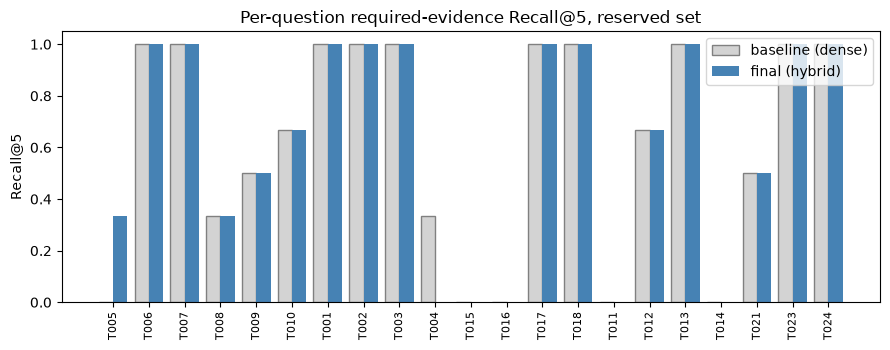

In [72]:
def paired_bootstrap(delta, n_boot=10000, seed=662):
    rng = np.random.default_rng(seed); delta = np.asarray(delta, dtype=float)
    means = np.array([rng.choice(delta, size=len(delta), replace=True).mean() for _ in range(n_boot)])
    return delta.mean(), np.percentile(means, [2.5, 97.5])

for name, col in (("Recall@5", "d_recall"), ("MRR@5", "d_rr")):
    m, (lo, hi) = paired_bootstrap(cmp5[col])
    print(f"{name}: mean difference (final - baseline) = {m:+.3f}   95% bootstrap interval [{lo:+.3f}, {hi:+.3f}]   "
          f"{'interval includes 0' if lo <= 0 <= hi else 'interval excludes 0'}")

fig, ax = plt.subplots(figsize=(9, 3.6)); w = 0.4
order = cmp5.sort_values(["query_type", "question_id"]).reset_index(drop=True)
ax.bar(np.arange(len(order)) - w / 2, order["recall@5_base"], w, label="baseline (dense)", color="lightgray", edgecolor="gray")
ax.bar(np.arange(len(order)) + w / 2, order["recall@5_final"], w, label="final (hybrid)", color="steelblue")
ax.set_xticks(np.arange(len(order))); ax.set_xticklabels([q.replace("TEST", "T") for q in order.question_id], rotation=90, fontsize=8)
ax.set_ylabel("Recall@5"); ax.set_title("Per-question required-evidence Recall@5, reserved set"); ax.legend(); plt.tight_layout(); plt.show()

### 5.3b Secondary retrieval views

The brief requires only the two primary metrics. Two further views are added because they change how the numbers should be read. Neither is used to choose or adjust anything.

* **`supporting` evidence.** The guide allows `supporting` gold to be analysed separately. Recall@5 against the union of `required` and `supporting` units shows whether the retrievers surface contextual evidence that the strict metric ignores.
* **Retriever-level abstention on the reserved set.** The frozen threshold is applied, not re-selected. Correct rejection is measured over TEST019 and TEST020 (denominator 2), false rejection over the 21 eligible questions (denominator 21). As in Task 3, a "rejection" only sets a flag; the top-5 are still returned for citation checks.

In [73]:
def recall_incl_supporting(retrieve_fn):
    vals = []
    for q in FINAL_ELIGIBLE:
        gold = FINAL_REQUIRED_GOLD[q["question_id"]] | FINAL_SUPPORTING_GOLD[q["question_id"]]
        vals.append(recall_at_k(hits_to_units(retrieve_fn(q["question"], 5)), gold, k=5))
    return float(np.mean(vals))
print(f"Recall@5 against required + supporting units:  baseline {recall_incl_supporting(baseline_retrieve):.3f}   "
      f"final {recall_incl_supporting(lambda q, k=5: final_retrieve(q, k)[0]):.3f}")

tau = FROZEN["final"]["score_threshold"]
oos = [FINAL_QUESTIONS[q] for q in ABSTENTION_GROUPS_FINAL["scope_refusal"]]
correct_rej = sum(1 for q in oos if not final_retrieve(q["question"])[1])
false_rej = sum(1 for q in FINAL_ELIGIBLE if not final_retrieve(q["question"])[1])
print(f"frozen threshold {tau:.3f}:  correct-rejection = {correct_rej}/{len(oos)} = {100*correct_rej/len(oos):.0f}%   "
      f"false-rejection = {false_rej}/{len(FINAL_ELIGIBLE)} = {100*false_rej/len(FINAL_ELIGIBLE):.1f}%")
for q in oos:
    hits, above = final_retrieve(q["question"])
    scope_rank = next((r for r, (_, c) in enumerate(hits, 1) if (c["metadata"]["document_id"], c["metadata"]["clause_id"]) == ("NPS_NH_2025", "1.3")), None)
    print(f"  {q['question_id']}: top-1 score {hits[0][0]:.3f}, above threshold: {above}, scope clause NPS_NH_2025/1.3 in top-5 at rank: {scope_rank}")

Recall@5 against required + supporting units:  baseline 0.534   final 0.517
frozen threshold 0.666:  correct-rejection = 0/2 = 0%   false-rejection = 0/21 = 0.0%
  TEST019: top-1 score 0.700, above threshold: True, scope clause NPS_NH_2025/1.3 in top-5 at rank: None
  TEST020: top-1 score 0.906, above threshold: True, scope clause NPS_NH_2025/1.3 in top-5 at rank: None


A retriever that works well should rank clause `1.3` highly and **not** reject. Report whether `1.3` reached the context for TEST019 and TEST020, because the answer-level scope-refusal rate in 5.5 can only succeed if it did.)*

### 5.4 Generation on the reserved set

Both systems answer all 24 reserved questions: 48 generations in total. The prompt text is assembled from the same fixed instruction strings as in Task 4. As a guard against accidental drift, the assembled prompts are first compared with the Task 4 builders on the development subset, and they must be identical for all three configurations. Decoding is unchanged (`do_sample=False`, `max_new_tokens=1024`), and answers are cached to disk by `(system, question, prompt hash, model, decoding settings)`, so an interrupted run resumes and no answer is regenerated.

In [74]:
def assemble_prompt(config, q, hits):
    # One prompt for one (configuration, question, retrieved hits). Same text as the Task 4 builders (checked below).
    head = {"P1": ["Use only the context below to answer the question.", "", "Context:", context_block(hits)],
            "P2": [P2_INSTRUCTIONS, "", "Retrieved policy evidence:", context_block(hits)],
            "P3": [P3_INSTRUCTIONS, "", "Retrieved policy evidence:", context_block(hits)]}[config]
    if pd.notna(q["case_id"]):
        case_block = ["", "Case facts:", render_case_facts(SITE_CASES[q["case_id"]])]
    else:
        case_block = [] if config == "P1" else ["", "Case facts: none supplied -- this is a general policy question, not a site-specific one."]
    return "\n".join(head + case_block + ["", (f"Question: {q['question']}")])

for cfg in ("P1", "P2", "P3"):                                    # regression test against Task 4
    for qid in PROMPT_DEV_IDS:
        assert assemble_prompt(cfg, DEV_QUESTIONS[qid], SHARED_RETRIEVAL[qid]["hits"]) == PROMPT_BUILDERS[cfg](qid), (cfg, qid)
print("assemble_prompt reproduces the Task 4 prompts exactly for P1, P2 and P3 on all 8 development-subset questions")

SYSTEMS = {"baseline": {"config": "P1", "label": "baseline (dense + P1)", "retrieve": lambda qtext: (baseline_retrieve(qtext, 5), None)},
           "final":    {"config": FROZEN["final"]["prompt"], "label": f"final (hybrid + {FROZEN['final']['prompt']})", "retrieve": lambda qtext: final_retrieve(qtext, 5)}}
print({k: v["label"] for k, v in SYSTEMS.items()})

assemble_prompt reproduces the Task 4 prompts exactly for P1, P2 and P3 on all 8 development-subset questions
{'baseline': 'baseline (dense + P1)', 'final': 'final (hybrid + P3)'}


In [75]:
T5_CACHE_PATH = OUT_DIR / "task5_final_answers.json"
T5_CACHE = json.loads(T5_CACHE_PATH.read_text(encoding="utf-8")) if T5_CACHE_PATH.exists() else {}

def t5_key(system, qid, prompt):
    return f"{system}::{qid}::{hashlib.sha256(prompt.encode('utf-8')).hexdigest()[:16]}::{MODEL_ID}::do_sample=False::max_new_tokens={MAX_NEW_TOKENS}"

def run_final_evaluation():
    results = {}
    for system, spec in SYSTEMS.items():
        for qid, q in FINAL_QUESTIONS.items():
            hits, above = spec["retrieve"](q["question"])
            prompt = assemble_prompt(spec["config"], q, hits)
            key = t5_key(system, qid, prompt)
            if key in T5_CACHE:
                answer, stats = T5_CACHE[key]["answer"], T5_CACHE[key]["stats"]
            elif GENERATOR_AVAILABLE:
                answer, stats = generate([{"role": "user", "content": prompt}])
                T5_CACHE[key] = {"system": system, "question_id": qid, "prompt": prompt, "answer": answer, "stats": stats}
                T5_CACHE_PATH.write_text(json.dumps(T5_CACHE, indent=2, ensure_ascii=False), encoding="utf-8")
            else:
                answer, stats = None, None
            results[(system, qid)] = {"prompt": prompt, "answer": answer, "stats": stats, "hits": hits, "above_threshold": above,
                                      "context_units": {(c["metadata"]["document_id"], c["metadata"]["clause_id"]) for _, c in hits}}
    return results

F_RESULTS = run_final_evaluation()
n_final_generated = sum(v["answer"] is not None for v in F_RESULTS.values())
print(f"{n_final_generated}/{len(F_RESULTS)} answers available ({len(T5_CACHE)} cached at {T5_CACHE_PATH}).")
if n_final_generated < len(F_RESULTS):
    print("Some answers are missing because the generator is not available in this environment. Run the notebook where "
          "Qwen2.5-1.5B-Instruct can load; only the missing (system, question) pairs are generated.")

48/48 answers available (48 cached at processed\task5_final_answers.json).


### 5.5 Response-behaviour measures

These are the measures of `evaluation_guide.md` section 2, reported separately for the baseline and the final system. Retrieval and response quality are kept apart on purpose: coverage divides only by required units that reached the context, so it measures whether the prompt made the model use what it was given, not whether retrieval found it.

Truncated answers (those that hit `max_new_tokens`) are a generation failure. As the guide says, they are counted and reported, and not scored for citations or abstention.

### 5.5a Test of the scoring code on synthetic answers

The metric code has not yet seen a real model answer. The cell below feeds it four **hand-written strings** (not model output) whose correct buckets are known in advance, so that a bug in the scoring is caught before the results are read.

In [76]:
def score_answer_citations(answer, context_units, required):
    # -> (buckets, n_required_present, n_required_cited); n_required_cited is None if nothing required reached the context
    buckets = classify_citations(answer, context_units)
    present = set(required) & set(context_units)
    cited = set(extract_citations(answer))
    return buckets, len(present), (len(present & cited) if present else None)

_ctx = {("NPS_NH_2025", "2.2 Policy 3"), ("SELWYN_NH", "NH-P10"), ("CRPS_CH11", "11.3.1")}
_req = {("NPS_NH_2025", "2.2 Policy 3"), ("SELWYN_NH", "NH-SCHED1")}          # NH-SCHED1 required but NOT in context
_b, _npres, _ncit = score_answer_citations(
    "Very high risk is to be avoided (NPS_NH_2025, 2.2 Policy 3). Floor levels follow (SELWYN_NH, NH-P10) and (SELWYN_NH, NH-P10). "
    "See also (SELWYN_NH, NH-SCHED1) and (CRPS_CH11, 11.9.9). Policy 5 is mentioned without a document.", _ctx, _req)
assert _b["valid"] == [("NPS_NH_2025", "2.2 Policy 3"), ("SELWYN_NH", "NH-P10")]          # duplicate NH-P10 de-duplicated within the answer
assert _b["out_of_context"] == [("SELWYN_NH", "NH-SCHED1")] and _b["fabricated"] == [("CRPS_CH11", "11.9.9")]
assert _b["unattributed"] == ["2.2 Policy 5"] and (_npres, _ncit) == (1, 1)
_b2, _n2, _c2 = score_answer_citations("No provisions are named here.", _ctx, _req)
assert sum(len(_b2[k]) for k in ("valid", "out_of_context", "fabricated")) == 0 and (_n2, _c2) == (1, 0)
_b3, _n3, _c3 = score_answer_citations("(NPS_NH_2025, 2.2 Policy 3)", set(), _req)
assert (_n3, _c3) == (0, None)                                                             # nothing required in context -> coverage undefined
print("scoring code behaves as specified on the synthetic answers (buckets, per-answer de-duplication, coverage, n/a case)")

scoring code behaves as specified on the synthetic answers (buckets, per-answer de-duplication, coverage, n/a case)


In [77]:
def is_truncated(system, qid):
    st = F_RESULTS[(system, qid)]["stats"]
    return bool(st and st["hit_cap"])

def citation_table(system):
    rows = []
    for qid, q in FINAL_QUESTIONS.items():
        r = F_RESULTS[(system, qid)]
        if r["answer"] is None: continue
        if is_truncated(system, qid):
            rows.append({"question_id": qid, "query_type": q["query_type"], "truncated": True}); continue
        b, n_present, n_cited = score_answer_citations(r["answer"], r["context_units"], FINAL_REQUIRED_GOLD.get(qid, set()))
        rows.append({"question_id": qid, "query_type": q["query_type"], "truncated": False, "valid": len(b["valid"]),
                     "out_of_context": len(b["out_of_context"]), "fabricated": len(b["fabricated"]), "unattributed": len(b["unattributed"]),
                     "suspicious": len(b["suspicious"]), "n_required_gold": len(FINAL_REQUIRED_GOLD.get(qid, set())),
                     "n_required_in_context": n_present, "n_required_cited": n_cited})
    return pd.DataFrame(rows)

def citation_summary(system):
    t = citation_table(system)
    if t.empty: return {"system": system, "answers_scored": 0}
    s = t[~t.truncated.astype(bool)]
    tot = {b: int(s[b].sum()) for b in ("valid", "out_of_context", "fabricated")}
    n_cit = sum(tot.values())
    cov_rows = s[s.n_required_in_context > 0]
    return {"system": system, "answers_scored": len(s), "truncated_not_scored": int(t.truncated.sum()), "checkable_citations": n_cit,
            "validity_rate": (tot["valid"] / n_cit) if n_cit else None, **tot,
            "unattributed": int(s.unattributed.sum()), "suspicious": int(s.suspicious.sum()),
            "coverage": (cov_rows.n_required_cited.sum() / cov_rows.n_required_in_context.sum()) if len(cov_rows) else None,
            "coverage_units": f"{int(cov_rows.n_required_cited.sum())}/{int(cov_rows.n_required_in_context.sum())}" if len(cov_rows) else "n/a",
            "excluded_retrieval_failure": int(((s.n_required_gold > 0) & (s.n_required_in_context == 0)).sum()),
            "excluded_no_required_gold": int((s.n_required_gold == 0).sum())}

CIT = {system: citation_summary(system) for system in SYSTEMS}
for system, s in CIT.items():
    print(SYSTEMS[system]["label"])
    if not s.get("answers_scored"): print("   no scored answers available yet"); continue
    vr = f"{s['validity_rate']:.3f}" if s["validity_rate"] is not None else f"n/a (checkable citation count = {s['checkable_citations']})"
    print(f"   citation validity {vr}   [valid {s['valid']}, out-of-context {s['out_of_context']}, fabricated {s['fabricated']}]   "
          f"unattributed {s['unattributed']}   suspicious {s['suspicious']}")
    cv = f"{s['coverage']:.3f} ({s['coverage_units']} required units cited)" if s["coverage"] is not None else "n/a"
    print(f"   required-evidence coverage {cv}   [excluded: {s['excluded_retrieval_failure']} retrieval-failure, {s['excluded_no_required_gold']} no-required-gold; "
          f"{s['truncated_not_scored']} truncated not scored]")

baseline (dense + P1)
   citation validity n/a (checkable citation count = 0)   [valid 0, out-of-context 0, fabricated 0]   unattributed 6   suspicious 0
   required-evidence coverage 0.000 (0/25 required units cited)   [excluded: 7 retrieval-failure, 1 no-required-gold; 0 truncated not scored]
final (hybrid + P3)
   citation validity 0.889   [valid 8, out-of-context 0, fabricated 1]   unattributed 11   suspicious 2
   required-evidence coverage 0.143 (3/21 required units cited)   [excluded: 7 retrieval-failure, 1 no-required-gold; 2 truncated not scored]



### 5.5b Abstention behaviour

These three rates need a person to read each answer against the criteria in `evaluation_guide.md` section 2.4. A keyword match would score the wrong behaviour as correct, for example a blanket refusal on a missing-information question, which the guide says is *not* correct. The reserved file has no `expected_behavior` column, so each judgement rests on the guide's criteria, the question, the case facts (in particular which fields are null) and the retrieved evidence. `judge_sheet()` puts all of these in one place. `refusal_triage()` is only a reading aid that marks answers containing refusal-like wording so they are read first; it is **never** used to compute a rate.

In [78]:
SCOPE_FINAL = {(s, q): None for s in SYSTEMS for q in ABSTENTION_GROUPS_FINAL["scope_refusal"]}                     # denominator 2
UNC_FINAL   = {(s, q): {"answers_supported_parts": None, "names_specific_missing_info": None,
                        "withholds_only_dependent_conclusions": None} for s in SYSTEMS for q in ABSTENTION_GROUPS_FINAL["uncertainty_handling"]}  # denominator 4
FALSE_FINAL = {(s, q): None for s in SYSTEMS for q in ABSTENTION_GROUPS_FINAL["false_refusal"]}                     # denominator 14: True = a FALSE REFUSAL

REFUSAL_WORDS = re.compile(r"\b(cannot|can not|can't|unable to|not able to|decline|refuse|i am not able|no determination|not within the scope|outside the scope|excluded)\b", re.I)
def refusal_triage(answer): return bool(answer) and bool(REFUSAL_WORDS.search(answer))

def case_gaps(case_id):
    if pd.isna(case_id): return ["no case supplied"]
    c = SITE_CASES[case_id]; gaps = [f"risk level for {h} not supplied" for h, v in c["risk_levels"].items() if v is None]
    if not c["flood"].get("evidence_available"): gaps.append("no flood evidence available")
    if not c["liquefaction"].get("site_specific_geotech_available"): gaps.append("no site-specific geotechnical assessment")
    return gaps + [f"known uncertainty: {u}" for u in c["known_uncertainties"]]

CRITERIA = {"scope_refusal": "CORRECT if the answer declines the determination that was asked for AND states the scope boundary (names the exclusion).",
            "uncertainty_handling": "CORRECT only if ALL of: (a) answers the parts the evidence supports, (b) names the specific missing information, (c) withholds only conclusions that depend on it. A blanket refusal is NOT correct.",
            "false_refusal": "A FALSE REFUSAL (True) if the answer refuses or declines any preliminary position although the supplied evidence supports one."}

def judge_sheet(system, qid):
    q, r = FINAL_QUESTIONS[qid], F_RESULTS[(system, qid)]
    group = next((g for g, ids in ABSTENTION_GROUPS_FINAL.items() if qid in ids), None)
    print("=" * 112); print(f"{SYSTEMS[system]['label']} | {qid} | group: {group or 'none (not in any of the three abstention-rate groups; read for diagnosis only)'}")
    print("criteria:", CRITERIA.get(group, "-"))
    print(f"question: {q['question']}"); print("case gaps:", "; ".join(case_gaps(q["case_id"])))
    print("required gold:", sorted(FINAL_REQUIRED_GOLD.get(qid, set())), "| in context:", sorted(FINAL_REQUIRED_GOLD.get(qid, set()) & r["context_units"]))
    if r["answer"] is None: print("[no answer]"); return
    print(f"refusal-like wording present (triage only): {refusal_triage(r['answer'])} | truncated: {is_truncated(system, qid)}"); print("-" * 112); print(r["answer"])

def _fmt_rate(x):
    return x if isinstance(x, str) else (f"{x[0]}/{x[1]} = {100 * x[0] / x[1]:.0f}%" if x else "not yet judged")

def abstention_rates(system):
    out = {}
    ids = ABSTENTION_GROUPS_FINAL["scope_refusal"]; use = [q for q in ids if not is_truncated(system, q) and F_RESULTS[(system, q)]["answer"] is not None]
    vals = [SCOPE_FINAL[(system, q)] for q in use]
    out["scope_refusal"] = None if (not use or any(v is None for v in vals)) else (sum(bool(v) for v in vals), len(vals))
    ids = ABSTENTION_GROUPS_FINAL["uncertainty_handling"]; use = [q for q in ids if not is_truncated(system, q) and F_RESULTS[(system, q)]["answer"] is not None]
    parts = [UNC_FINAL[(system, q)] for q in use]
    out["uncertainty_handling"] = None if (not use or any(v is None for p in parts for v in p.values())) else (sum(all(p.values()) for p in parts), len(parts))
    ids = ABSTENTION_GROUPS_FINAL["false_refusal"]; use = [q for q in ids if not is_truncated(system, q) and F_RESULTS[(system, q)]["answer"] is not None]
    vals = [FALSE_FINAL[(system, q)] for q in use]
    out["false_refusal"] = None if (not use or any(v is None for v in vals)) else (sum(bool(v) for v in vals), len(vals))
    out["n_truncated_in_groups"] = sum(is_truncated(system, q) for ids in ABSTENTION_GROUPS_FINAL.values() for q in ids if F_RESULTS[(system, q)]["answer"] is not None)
    return out

def _needs_judging(system, qid):
    return F_RESULTS[(system, qid)]["answer"] is not None and not is_truncated(system, qid)

def outstanding_judgements():
    # Judgement cells still None, counting only answers that exist and were not truncated (those are the ones that can be judged).
    return (sum(v is None for (s, q), v in SCOPE_FINAL.items() if _needs_judging(s, q)) +
            sum(v is None for (s, q), v in FALSE_FINAL.items() if _needs_judging(s, q)) +
            sum(x is None for (s, q), p in UNC_FINAL.items() if _needs_judging(s, q) for x in p.values()))

for system in SYSTEMS:
    a = abstention_rates(system)
    print(f"{SYSTEMS[system]['label']}:  scope-refusal {_fmt_rate(a['scope_refusal'])} | uncertainty-handling {_fmt_rate(a['uncertainty_handling'])} | "
          f"false-refusal {_fmt_rate(a['false_refusal'])}" + (f"   [{a['n_truncated_in_groups']} truncated answer(s) excluded]" if a["n_truncated_in_groups"] else ""))
print(f"\njudgement cells still outstanding (among answers that exist and were not truncated): {outstanding_judgements()}"
      f"   [answers available: {n_final_generated}/{len(F_RESULTS)}]  Each reads 'not yet judged' until the answer has been read with judge_sheet(system, question_id).")

baseline (dense + P1):  scope-refusal not yet judged | uncertainty-handling not yet judged | false-refusal not yet judged
final (hybrid + P3):  scope-refusal not yet judged | uncertainty-handling not yet judged | false-refusal not yet judged   [2 truncated answer(s) excluded]

judgement cells still outstanding (among answers that exist and were not truncated): 54   [answers available: 48/48]  Each reads 'not yet judged' until the answer has been read with judge_sheet(system, question_id).


To judge, run `judge_sheet(system, qid)` for each question in the three groups, for both systems, and then set the values in the dictionaries above. For example, `SCOPE_FINAL[("final", "TEST019")] = True` or `UNC_FINAL[("baseline", "TEST015")]["names_specific_missing_info"] = False`. Keep the reading consistent between the two systems, and do not let the triage flag decide anything. The rates are read with the denominators in view (2, 4 and 14): a single answer moves the scope-refusal rate by 50 points and the uncertainty-handling rate by 25.

### 5.5c Cost

In [79]:
def cost_final(system):
    st = [F_RESULTS[(system, q)]["stats"] for q in FINAL_QUESTIONS if F_RESULTS[(system, q)]["stats"] is not None]
    if not st: return {"system": SYSTEMS[system]["label"], "answers": 0}
    return {"system": SYSTEMS[system]["label"], "answers": len(st), "mean_prompt_tokens": round(np.mean([s["prompt_tokens"] for s in st])),
            "mean_generated_tokens": round(np.mean([s["generated_tokens"] for s in st])), "mean_seconds": round(np.mean([s["seconds"] for s in st]), 1),
            "device": st[0]["device"], "dtype": st[0]["dtype"], "hit_max_new_tokens": int(sum(s["hit_cap"] for s in st))}
COST = {system: cost_final(system) for system in SYSTEMS}
display(pd.DataFrame(COST.values()).set_index("system"))

,answers,mean_prompt_tokens,mean_generated_tokens,mean_seconds,device,dtype,hit_max_new_tokens
system,,,,,,,
baseline (dense + P1),24,1177,253,98.4,cpu,torch.float32,0
final (hybrid + P3),24,1723,539,209.8,cpu,torch.float32,2


### 5.5d Summary table

One row per system. Retrieval rows come from 5.3, response rows from 5.5. Placeholders read `n/a` or `not yet judged` until the answers exist and have been judged.

In [80]:
def summary_row(system):
    c, a, k = CIT[system], abstention_rates(system), COST[system]
    ret = base_sum if system == "baseline" else final_sum
    return {"system": SYSTEMS[system]["label"], "Recall@5 (n=21)": round(ret["Recall@5"], 3), "MRR@5 (n=21)": round(ret["MRR@5"], 3),
            "citation validity": (f"{c['validity_rate']:.3f}" if c.get("validity_rate") is not None else ("n/a" if c.get("answers_scored") else "no answers")),
            "checkable citations": c.get("checkable_citations", "n/a"),
            "fabricated / out-of-ctx": f"{c.get('fabricated', 'n/a')} / {c.get('out_of_context', 'n/a')}",
            "unattributed / suspicious": f"{c.get('unattributed', 'n/a')} / {c.get('suspicious', 'n/a')}",
            "coverage": (f"{c['coverage']:.3f}" if c.get("coverage") is not None else "n/a"),
            "scope-refusal": _fmt_rate(a["scope_refusal"]), "uncertainty-handling": _fmt_rate(a["uncertainty_handling"]), "false-refusal": _fmt_rate(a["false_refusal"]),
            "mean prompt tok": k.get("mean_prompt_tokens"), "mean gen tok": k.get("mean_generated_tokens"), "mean s": k.get("mean_seconds"),
            "device": k.get("device"), "hit cap": k.get("hit_max_new_tokens")}
display(pd.DataFrame([summary_row(s) for s in SYSTEMS]).set_index("system").T)

system,baseline (dense + P1),final (hybrid + P3)
Recall@5 (n=21),0.619,0.619
MRR@5 (n=21),0.617,0.599
citation validity,n/a,0.889
checkable citations,0,9
fabricated / out-of-ctx,0 / 0,1 / 0
unattributed / suspicious,6 / 0,11 / 2
coverage,0.000,0.143
scope-refusal,not yet judged,not yet judged
uncertainty-handling,not yet judged,not yet judged
false-refusal,not yet judged,not yet judged


### 5.6 Failure analysis

The brief asks for a detailed diagnosis of **at least five important failure cases**, each traced to one primary cause from `evaluation_guide.md` section 3: **R** retrieval, **C** context construction, **P** prompting, **G** generation, **S** source conflict, **I** insufficient information, **E** evaluation limitation. The guide's rule for the commonest confusion is applied mechanically below: an out-of-context or fabricated citation points to **R** if the clause was required gold that retrieval missed, and to **G** if retrieval supplied the required evidence and the model went beyond it anyway.

The cell below scans every answer for objective warning signs and ranks the questions by how many they show. It is a **shortlist generator**, not a diagnosis. The category it suggests is only the mechanical reading of the guide's rule. The primary cause of each chosen case must be justified by reading the retrieved passages and the answer, and the diagnosis must then be written into `FAILURE_CASES`.

In [81]:
NUM_CLAIM = re.compile(r"\b\d+(?:\.\d+)?\s?(?:mm|cm|m|metres?|meters?|%|years?|yr|km|m/s)\b", re.I)
def unsupported_numbers(answer, prompt):
    # Numeric claims (with a unit) in the answer that appear nowhere in the prompt. Candidates for reading, not proof of error.
    seen = {re.sub(r"\s", "", m.group(0).lower()) for m in NUM_CLAIM.finditer(prompt)}
    return sorted({m.group(0) for m in NUM_CLAIM.finditer(answer) if re.sub(r"\s", "", m.group(0).lower()) not in seen})

LEVEL_ASSERT = re.compile(r"\b(?:(low|medium|high|very high)\s+(flood|flooding|liquefaction)\s+risk|(flood|flooding|liquefaction)\s+risk\s+(?:is|of|level is|level of)\s+(low|medium|high|very high))\b", re.I)
def asserted_null_levels(answer, case_id):
    # Risk levels asserted in the answer for a hazard whose supplied risk level is null (a candidate hallucinated level).
    if pd.isna(case_id): return []
    nulls = {h for h, v in SITE_CASES[case_id]["risk_levels"].items() if v is None}
    out = []
    for m in LEVEL_ASSERT.finditer(answer):
        hazard = (m.group(2) or m.group(3)).lower(); hazard = "flooding" if hazard.startswith("flood") else hazard
        if hazard in nulls: out.append(m.group(0))
    return out

def failure_signals(system, qid):
    r, q = F_RESULTS[(system, qid)], FINAL_QUESTIONS[qid]
    if r["answer"] is None: return None
    req, ctx = FINAL_REQUIRED_GOLD.get(qid, set()), r["context_units"]
    sig = []
    if is_truncated(system, qid): return [("G", "truncated at max_new_tokens")]
    b, n_present, n_cited = score_answer_citations(r["answer"], ctx, req)
    if q["retrieval_eval_eligible"] == "yes":
        if n_present == 0: sig.append(("R", "no required gold unit reached the context"))
        elif n_present < len(req): sig.append(("R", f"only {n_present}/{len(req)} required units reached the context"))
    for cit in b["out_of_context"] + b["fabricated"]:
        kind = "fabricated" if cit in b["fabricated"] else "out-of-context"
        missed_required = (cit in req and cit not in ctx)
        sig.append(("R" if missed_required else "G", f"{kind} citation {cit[0]}/{cit[1]}" + (" (required gold that retrieval missed)" if missed_required else "")))
    if SYSTEMS[system]["config"] != "P1" and n_present and n_cited is not None and n_cited < n_present:
        sig.append(("P", f"cited {n_cited}/{n_present} of the required units that were in context"))
    if SYSTEMS[system]["config"] != "P1" and not (b["valid"] or b["out_of_context"] or b["fabricated"]):
        sig.append(("P", "no checkable citation despite a citation instruction"))
    if q["query_type"] in ("direct_policy", "case_specific", "multi_document") and refusal_triage(r["answer"]):
        sig.append(("P", "refusal-like wording on a question the evidence should support (read it)"))
    if q["query_type"] == "out_of_scope" and not refusal_triage(r["answer"]):
        sig.append(("P", "no refusal-like wording on an out-of-scope question (read it)"))
    if q["query_type"] == "out_of_scope" and ("NPS_NH_2025", "1.3") not in ctx:
        sig.append(("R", "scope clause NPS_NH_2025/1.3 not in context"))
    nl = asserted_null_levels(r["answer"], q["case_id"])
    if nl: sig.append(("G", f"asserts a risk level for a hazard whose supplied level is null: {nl[0]!r}"))
    un = unsupported_numbers(r["answer"], r["prompt"])
    if un: sig.append(("G", f"numeric claim(s) not found in the prompt: {un[:3]}"))
    guide_cites = [c for c in b["valid"] if c[0] == "NPS_NH_GUIDE_2026"]
    if guide_cites and not re.search(r"non-binding|guidance|not binding|supporting|interpret", r["answer"], re.I):
        sig.append(("S", "cites the non-binding Implementation Guide with no authority wording"))
    return sig

rows = []
for system in SYSTEMS:
    for qid in FINAL_QUESTIONS:
        sig = failure_signals(system, qid)
        if sig: rows.append({"system": system, "question_id": qid, "query_type": FINAL_QUESTIONS[qid]["query_type"], "n_signals": len(sig),
                             "mechanical_reading": "/".join(sorted({c for c, _ in sig})), "signals": " | ".join(t for _, t in sig)})
CANDIDATES = pd.DataFrame(rows)
if CANDIDATES.empty:
    print("No answers available yet, so no failure candidates can be listed. Generate the answers (5.4) and re-run this cell.")
else:
    pd.set_option("display.max_colwidth", 160)
    display(CANDIDATES.sort_values("n_signals", ascending=False).head(20))

,system,question_id,query_type,n_signals,mechanical_reading,signals
25,final,TEST012,multi_document,4,G/P/R,only 2/3 required units reached the context | cited 0/2 of the required units that were in context | no checkable citation despite a citation instruction | ...
21,final,TEST008,case_specific,4,G/P/R,only 1/3 required units reached the context | cited 0/1 of the required units that were in context | no checkable citation despite a citation instruction | ...
32,final,TEST019,out_of_scope,4,G/P/R,no checkable citation despite a citation instruction | no refusal-like wording on an out-of-scope question (read it) | scope clause NPS_NH_2025/1.3 not in c...
12,baseline,TEST019,out_of_scope,3,G/P/R,no refusal-like wording on an out-of-scope question (read it) | scope clause NPS_NH_2025/1.3 not in context | numeric claim(s) not found in the prompt: ['0....
23,final,TEST010,case_specific,3,G/P/R,only 2/3 required units reached the context | cited 1/2 of the required units that were in context | numeric claim(s) not found in the prompt: ['33 years']
22,final,TEST009,case_specific,3,P/R,only 1/2 required units reached the context | cited 0/1 of the required units that were in context | no checkable citation despite a citation instruction
24,final,TEST011,multi_document,3,G/P/R,no required gold unit reached the context | no checkable citation despite a citation instruction | numeric claim(s) not found in the prompt: ['0.3 m']
31,final,TEST018,missing_information,3,G/P,cited 0/1 of the required units that were in context | no checkable citation despite a citation instruction | numeric claim(s) not found in the prompt: ['0....
29,final,TEST016,missing_information,3,G/P/R,no required gold unit reached the context | no checkable citation despite a citation instruction | numeric claim(s) not found in the prompt: ['0.3 m']
33,final,TEST020,out_of_scope,3,P/R/S,no refusal-like wording on an out-of-scope question (read it) | scope clause NPS_NH_2025/1.3 not in context | cites the non-binding Implementation Guide wit...


**Choosing the cases.** Pick at least five that are *important* and that differ from one another in cause and in question type. Important means the failure would matter to a planner or council reader (a wrong risk level, an invented citation on a decisive clause, a determination given where the scope excludes it), not merely that it scored a signal. Include failures of the **baseline** and of the **final system**, and at least one case where the final system fixed something the baseline got wrong, or made it worse. For each, work through the guide's order of checks: was the required evidence in the context (R), was it assembled correctly (C), did the prompt ask for the behaviour (P), did the model fail despite both (G), did sources disagree or differ in authority (S), was the information simply not there (I), or is the label or rubric itself the problem (E).

Write each diagnosis as an entry in the list below. `validate_failure_cases()` checks that there are at least five, that each has a valid category and real question id, and that the justification is non-empty. It cannot check that the diagnosis is *right*: that comes from reading the evidence.

TEST019 stays R, with P secondary. The guide defines R as relevant evidence being absent, and clause 1.3 never reached the context. P applies only when adequate evidence is present, so the prompt can't be the primary cause here. This is the same reasoning I gave before, and the guide supports it.

Truncated answers are G, not C. The guide lists failing to terminate within max_new_tokens under G, so P2's three capped development answers are generation failures. C is about the context: truncated, misordered, duplicated or wrongly assembled evidence.
I was wrong that there is no source-conflict case. The guide's S includes sources that differ in status or authority when the system doesn't expose the difference. TEST020's signal list includes "cites the non-binding Implementation Guide…", and TEST021 is a source_authority question. Read both. If an answer presents Guide text as binding, or doesn't flag the status difference, that's S.
The numeric flags may be E. If "0.3 m" was flagged only because the case record stores 0.3 in a field without the unit, the failure is in the string-match check and not in the system. The guide's E covers an evaluation design that is insufficient or ambiguous, so a false-positive flag is a legitimate E case, as long as you verify it first.

Check the P versus G split with the guide's rule. For TEST012 (2/3 required units in context, 0 cited), the guide says G applies when the model fails despite adequate context and prompt, and P when the instructions fail to elicit the behaviour. Open the frozen prompt's citation line. If it lacks the (document_id, clause_id) form, it's P. If it states the form clearly and the answer still ignores it, it's G.

In [84]:
dups = []
for qid, q in FINAL_QUESTIONS.items():
    hits, _ = retrieve_frozen(q["question"])
    keys = [(c["metadata"]["document_id"], c["metadata"]["clause_id"]) for _, c in hits]
    dup = {k for k in keys if keys.count(k) > 1}
    if dup:
        req = {(r.document_id, r.clause_id) for r in gold_df[(gold_df.question_id == qid) & (gold_df.relevance_type == "required")].itertuples()}
        dups.append((qid, sorted(dup), "required missing:", sorted(req - set(keys))))
for d in dups: print(d)

('TEST003', [('NPS_NH_GUIDE_2026', 'Part 4: Best available information')], 'required missing:', [])
('TEST005', [('SELWYN_NH', 'NH-SCHED1')], 'required missing:', [('CRPS_CH11', '11.3.2'), ('NPS_NH_2025', '2.2 Policy 5')])
('TEST006', [('SELWYN_NH', 'NH-SCHED1')], 'required missing:', [])
('TEST008', [('SELWYN_NH', 'NH-SCHED1')], 'required missing:', [('CRPS_CH11', '11.3.3'), ('SELWYN_NH', 'NH-P3')])
('TEST011', [('SELWYN_NH', 'NH-SCHED1')], 'required missing:', [('CRPS_CH11', '11.3.2'), ('NPS_NH_2025', '2.2 Policy 1'), ('SELWYN_NH', 'NH-P10')])
('TEST017', [('SELWYN_NH', 'NH-SCHED1')], 'required missing:', [])
('TEST018', [('NPS_NH_GUIDE_2026', 'Part 4: Best available information')], 'required missing:', [])
('TEST020', [('NPS_NH_GUIDE_2026', 'Part 4: Best available information')], 'required missing:', [('NPS_NH_2025', '1.3')])


* TEST003, TEST006, TEST017 and TEST018 have a duplicated slot but no required unit missing. The duplication cost nothing there, so none of them is a C failure.

* TEST011 is missing all three required units. One lost slot can't explain that, so it's a retrieval failure (R) with no C involvement. The duplication is incidental.

* TEST005, TEST008 and TEST020 are the only real candidates. A missing required unit counts as a C case only if it would have been included without the duplicate. With one slot lost, that means it must be the next distinct clause after the four distinct units already retrieved. If it ranks much deeper, the primary cause is R and the duplicate is a side note.

In [85]:
def distinct_rank(qid, system="final"):
    q = FINAL_QUESTIONS[qid]["question"]
    hits = retrieve_frozen(q, k=15)[0] if system == "final" else retrieve(q, k=15)   # adjust k to what your retrievers allow
    seen, order = set(), []
    for _, c in hits:
        key = (c["metadata"]["document_id"], c["metadata"]["clause_id"])
        if key not in seen:
            seen.add(key); order.append(key)
    req = {(r.document_id, r.clause_id) for r in gold_df[(gold_df.question_id == qid) & (gold_df.relevance_type == "required")].itertuples()}
    return {k: (order.index(k) + 1 if k in order else None) for k in req}

for qid in ("TEST005", "TEST008", "TEST020"):
    print(qid, distinct_rank(qid))

TEST005 {('CRPS_CH11', '11.3.2'): None, ('SELWYN_NH', 'NH-P10'): 3, ('NPS_NH_2025', '2.2 Policy 5'): None}
TEST008 {('NPS_NH_GUIDE_2026', 'Part 4: Detailed assessment'): 2, ('CRPS_CH11', '11.3.3'): None, ('SELWYN_NH', 'NH-P3'): None}
TEST020 {('NPS_NH_2025', '1.3'): None}


Neither case supports a C diagnosis, so drop C from your failure set. In all three questions, every missing required unit is None, which means it didn't appear anywhere in the retrieved candidates (at most k = 15 chunks). A clause crowded out by a duplicate would sit at distinct rank 5 or 6, and none do.

Two caveats on "None". None means "not within the first k distinct clauses returned", so report it as "not retrieved within the top N" with the actual N you passed. If your hybrid pools a fixed number of candidates per retriever, as your Task 3 summary says, a unit ranked below that pool by both retrievers is unrecoverable by design, and None is a deep miss, not a near miss.
TEST011 isn't checked yet. It had a duplicate and all three required units missing. Run distinct_rank("TEST011") to confirm they are None too, so the duplicate can be ruled out there as well.
The duplicate finding is a result. Duplicated slots occurred in 8 of 24 reserved questions, but none of the checked cases lost a required unit to it. That is a checked statement about a design consequence of the 250-word cap, and it fits in the context-construction part of your discussion.
TEST005 repeats DEV005. Both are case-specific flood questions where 11.3.2 and a general NPS policy are missed. TEST005 is probably the same vocabulary gap seen in development, where the question names no policy terms. Read the TEST005 question and confirm before you claim it.
TEST008 misses 11.3.3 (the earthquake and liquefaction policy). The corpus has little liquefaction content, and liquefaction was the primary hazard in only two chunks. If the question is about liquefaction, that gives you a specific hypothesis. Print the question to check, and don't assert it otherwise.
For TEST020, treat the case as in the same group as TEST019: the scope clause never arrives, and the prompt can't ground a refusal. Read the answer to confirm what it did.

In [86]:
for qid in ("TEST005", "TEST008"):
    print(qid, FINAL_QUESTIONS[qid]["query_type"], "|", FINAL_QUESTIONS[qid]["question"])
print("TEST011", distinct_rank("TEST011"))

TEST005 case_specific | For the community centre, provide a preliminary assessment that uses the supplied flood-risk level, identifies relevant flood evidence, missing information, and appropriate next steps.
TEST008 case_specific | For the school proposal, how should the supplied flood evidence, flood-risk level, occupancy, access, and liquefaction evidence affect the need for specialist review?
TEST011 {('CRPS_CH11', '11.3.2'): 9, ('SELWYN_NH', 'NH-P10'): 7, ('NPS_NH_2025', '2.2 Policy 1'): None}


In [87]:
cases = json.load(open(DATA_DIR / "site_cases.json"))
print(json.dumps(cases if isinstance(cases, dict) else cases[:1], indent=1)[:1200])   # find where depth 0.3 is stored

[
 {
  "case_id": "SC001",
  "proposal": {
   "activity_type": "12-lot residential subdivision",
   "number_of_lots_or_buildings": 12,
   "expected_occupancy": "Typical residential households",
   "vulnerable_occupants": false,
   "design_life_years": 100
  },
  "site": {
   "planning_zone": "Residential zone",
   "existing_use": "Vacant land",
   "hazard_overlays": [
    "Plains flood management overlay"
   ],
   "available_reports": [
    "Council flood assessment summary"
   ]
  },
  "flood": {
   "evidence_available": true,
   "aep_percent": 1.43,
   "return_period_years": 70,
   "modelled_depth_m": 0.35,
   "velocity_m_s": 0.25,
   "climate_change_considered": true
  },
  "liquefaction": {
   "susceptibility": "low",
   "mapped_evidence": "Supplied teaching map indicates low susceptibility",
   "site_specific_geotech_available": false
  },
  "mitigation": {
   "raised_floor_level": "Proposed",
   "freeboard_m": 0.3,
   "drainage": "Concept stormwater plan supplied",
   "foundation

In [ ]:

cases = json.load(open(DATA_DIR / "site_cases.json"))
CASES = {c["case_id"]: c for c in cases}

def flatten(d, path=""):
    for k, v in d.items():
        p = f"{path}.{k}" if path else k
        if isinstance(v, dict):
            yield from flatten(v, p)
        else:
            yield p, v

def fields_with_value(case_id, x):
    return [(p, v) for p, v in flatten(CASES[case_id])
            if isinstance(v, (int, float)) and not isinstance(v, bool) and abs(v - x) < 1e-9]

for qid, x in [("TEST006", 0.3), ("TEST011", 0.3), ("TEST016", 0.3), ("TEST018", 0.3), ("TEST010", 33)]:
    cid = FINAL_QUESTIONS[qid]["case_id"]
    print(qid, cid, x, "->", fields_with_value(cid, x))

TEST006 SC008 0.3 -> []
TEST011 SC007 0.3 -> [('flood.modelled_depth_m', 0.3), ('mitigation.freeboard_m', 0.3)]
TEST016 SC007 0.3 -> [('flood.modelled_depth_m', 0.3), ('mitigation.freeboard_m', 0.3)]
TEST018 SC006 0.3 -> []
TEST010 SC004 33 -> [('flood.return_period_years', 33)]


TEST010 (SC004), 33 years: it matches flood.return_period_years = 33, so the value came from the case record and the flag was a false positive from matching the unit string. This corrects my earlier guess. I called "33 years" a good generation candidate and guessed the design life would be 40, and the record shows I was wrong, so TEST010 is not a G case.

TEST011 and TEST016 (SC007), 0.3 m: both flood.modelled_depth_m and mitigation.freeboard_m equal 0.3, so the number is traceable but ambiguous. If the answer says "depth 0.3 m" or "freeboard 0.3 m", both are correct. A swap between the two fields can't be detected from the number, so only reading the sentence can tell, and it would be harmless unless it changes the conclusion.

TEST006 (SC008) and TEST018 (SC006), 0.3 m: no field in those case records holds 0.3, so the model didn't copy it from the case. That doesn't make it invented. NH-SCHED1 specifies a minimum finished floor level of 300 mm above the flood level, and a model can legitimately convert that to 0.3 m. Check whether the retrieved context for those two questions contains NH-SCHED1. If it does and the answer attributes 0.3 m to the policy, it's a correct conversion and a false positive. If it attributes 0.3 m to the proposal (for example "the proposed freeboard of 0.3 m") while the case's freeboard is null or different, it's an invented case fact (G), which the brief forbids.

In [100]:

B = json.load(open("processed/task5_final_answers.json"))
k = next(iter(B)); print(k); print({kk: str(vv)[:80] for kk, vv in B[k].items()})

baseline::TEST001::01346df74799c276::Qwen/Qwen2.5-1.5B-Instruct::do_sample=False::max_new_tokens=1024
{'system': 'baseline', 'question_id': 'TEST001', 'prompt': 'Use only the context below to answer the question.\n\nContext:\n[NPS_NH_2025 | clau', 'answer': 'According to the provided context, Policy 4 specifically addresses natural hazar', 'stats': "{'prompt_tokens': 688, 'generated_tokens': 64, 'seconds': 30.6, 'tokens_per_seco"}


In [109]:
from pathlib import Path
print(sorted(str(p) for p in Path("processed").glob("*task5*")) or sorted(str(p) for p in Path("processed").glob("*.json")))

['processed\\task5_final_answers.json']


In [110]:
['processed\\task5_final_answers.json']
import json
B = json.load(open("processed/task5_final_answers.json"))     # the file the cell above lists
T5 = {(r["system"], r["question_id"]): r for r in B.values()}
print(len(T5), sorted({s for s, _ in T5}))                       # expect 48 and ['baseline', 'final']

48 ['baseline', 'final']


In [111]:
for qid in ("TEST019", "TEST011", "TEST005", "TEST008", "TEST012", "TEST020", "TEST021"):
    r = T5[("final", qid)]
    print("=" * 100, "\n", qid, FINAL_QUESTIONS[qid]["query_type"], "| stats:", r["stats"])
    print(r["answer"][:1400])
    print("citations:", extract_citations(r["answer"]))

 TEST019 out_of_scope | stats: {'prompt_tokens': 1704, 'generated_tokens': 540, 'seconds': 205.7, 'tokens_per_second': 2.63, 'hit_cap': False, 'device': 'cpu', 'dtype': 'torch.float32'}
### Reasoning Check:

**Scope:** The retrieved evidence does not provide any exclusions related to the proposed activity or site. Therefore, we will proceed without making a definitive determination based solely on the given evidence.

**Evidence Sufficiency:** For each hazard relevant to the question, the evidence is sufficient. Specifically:
- **Flooding:** The flood modelled depth (0.3 m) and velocity (0.2 m/s) indicate potential risks, but the return period (50 years) suggests moderate risk rather than high risk.
- **Liquefaction:** While the susceptibility is low, the lack of site-specific geotechnical data prevents a precise risk assessment.

**Conflicts:** There are no direct conflicts between different sources regarding the proposed activity or site.

**Authority:** The NPS-NH provides guidance 

In [112]:
for qid in ("TEST019", "TEST011", "TEST005", "TEST008", "TEST012", "TEST020", "TEST021"):
    r = T5[("final", qid)]
    print("=" * 100, "\n", qid, FINAL_QUESTIONS[qid]["query_type"], "| stats:", r["stats"])
    print(r["answer"][:1400])
    print("citations:", extract_citations(r["answer"]))

 TEST019 out_of_scope | stats: {'prompt_tokens': 1704, 'generated_tokens': 540, 'seconds': 205.7, 'tokens_per_second': 2.63, 'hit_cap': False, 'device': 'cpu', 'dtype': 'torch.float32'}
### Reasoning Check:

**Scope:** The retrieved evidence does not provide any exclusions related to the proposed activity or site. Therefore, we will proceed without making a definitive determination based solely on the given evidence.

**Evidence Sufficiency:** For each hazard relevant to the question, the evidence is sufficient. Specifically:
- **Flooding:** The flood modelled depth (0.3 m) and velocity (0.2 m/s) indicate potential risks, but the return period (50 years) suggests moderate risk rather than high risk.
- **Liquefaction:** While the susceptibility is low, the lack of site-specific geotechnical data prevents a precise risk assessment.

**Conflicts:** There are no direct conflicts between different sources regarding the proposed activity or site.

**Authority:** The NPS-NH provides guidance 

In [113]:
def ctx_text(qid):
    hits = retrieve_frozen(FINAL_QUESTIONS[qid]["question"])[0]
    return " ".join(c["text"] for _, c in hits)

print("'Local Government' in TEST011 context:", "Local Government" in ctx_text("TEST011"))
for qid in ("TEST019", "TEST012", "TEST020"):
    cid = FINAL_QUESTIONS[qid]["case_id"]
    print(qid, cid, CASES[cid]["flood"], CASES[cid]["mitigation"])
print("TEST021:", FINAL_QUESTIONS["TEST021"]["case_id"], "|", FINAL_QUESTIONS["TEST021"]["question"])

p = T5[("final", "TEST012")]["prompt"]; i = p.lower().find("cite")
print(p[max(0, i - 200): i + 500])
for qid in ("TEST019", "TEST020"):
    print(qid, "TAIL:", T5[("final", qid)]["answer"][1400:])

'Local Government' in TEST011 context: False
TEST019 SC011 {'evidence_available': True, 'aep_percent': 2.0, 'return_period_years': 50, 'modelled_depth_m': 0.3, 'velocity_m_s': 0.2, 'climate_change_considered': True} {'raised_floor_level': None, 'freeboard_m': None, 'drainage': None, 'foundation_design': None, 'access_or_evacuation': None}
TEST012 SC008 {'evidence_available': True, 'aep_percent': 0.5, 'return_period_years': 200, 'modelled_depth_m': 0.18, 'velocity_m_s': 0.15, 'climate_change_considered': None} {'raised_floor_level': 'Proposed', 'freeboard_m': 0.25, 'drainage': 'Standard residential connection', 'foundation_design': None, 'access_or_evacuation': None}
TEST020 SC012 {'evidence_available': True, 'aep_percent': 5.0, 'return_period_years': 20, 'modelled_depth_m': 0.5, 'velocity_m_s': 0.35, 'climate_change_considered': True} {'raised_floor_level': None, 'freeboard_m': None, 'drainage': None, 'foundation_design': None, 'access_or_evacuation': None}
TEST021: nan | How should th

TEST005 as G, not R. R is also true, since 11.3.2 and 2.2 Policy 5 are missing. G wins because the specific failures are the cap and an invented conflict between two clauses that were in context, which missing evidence doesn't explain.

TEST012 as P, not G. The guide's test says G applies when the prompt is adequate. In development, P2 gave 13/13 valid citations and the P3-style prompt gave 2 valid, 1 fabricated and 8 unattributed, on the same model, contexts and decoding settings. That isolates the prompt as the cause. It assumes the frozen prompt shares P3's Reasoning Check structure (it appears to). Read its citation line before keeping this.

TEST020 as G, not R. TEST019 had the same missing scope clause and at least declined a "definitive determination". TEST020 asserts compliance and contradicts its own next sentence.

In [114]:
REQUIRED_FIELDS = ("what_went_wrong", "evidence", "answer_quote", "why_primary")

def _norm(s):
    return " ".join(str(s).split())

def validate_failure_cases(cases=None):
    cases = FAILURE_CASES if cases is None else cases
    problems = []
    if len(cases) < 5:
        problems.append(f"{len(cases)} case(s) documented; the brief requires at least five")
    if len({(c.get("question_id"), c.get("system")) for c in cases}) < len(cases):
        problems.append("duplicate (question_id, system) pairs")
    store = globals().get("T5")
    for i, c in enumerate(cases, 1):
        if c.get("question_id") not in FINAL_QUESTIONS:
            problems.append(f"case {i}: unknown question_id {c.get('question_id')!r}")
        if c.get("system") not in SYSTEMS:
            problems.append(f"case {i}: system must be one of {list(SYSTEMS)}")
        if c.get("category") not in tuple("RCPGSIE"):
            problems.append(f"case {i}: category must be one of R, C, P, G, S, I, E")
        if c.get("secondary", "none") not in ("none", *"RCPGSIE"):
            problems.append(f"case {i}: invalid secondary category")
        for f in REQUIRED_FIELDS:
            v = str(c.get(f, "")).strip()
            if not v:
                problems.append(f"case {i}: '{f}' is empty")
            elif "TODO" in v:
                problems.append(f"case {i} ({c.get('question_id')}): '{f}' still contains TODO")
        if store is not None and (c.get("system"), c.get("question_id")) in store:
            ans = _norm(store[(c["system"], c["question_id"])]["answer"])
            if _norm(c.get("answer_quote", "")) not in ans:
                problems.append(f"case {i} ({c.get('question_id')}): answer_quote not found verbatim in the stored answer")
    return problems

FAILURE_CASES = [
 {"question_id": "TEST019", "system": "final", "category": "R", "secondary": "P",
  "what_went_wrong": "Out-of-scope request (primary production) handled as an ordinary site assessment. The answer hedges on a 'definitive' recommendation because evidence is limited, never identifies the exclusion, and continues to a full preliminary recommendation including a 'Review and Approval' step. Same failure as DEV019 on the development set.",
  "evidence": "NPS_NH_2025/1.3 not in the retrieved context; no citation parsed; the baseline also shows no refusal-like wording. The frozen prompt makes the refusal conditional on check (a) finding an exclusion in the retrieved evidence, and (a) found none. Case SC011 values (0.3 m, 0.2 m/s, 50 years) trace to the record, and null mitigation fields were correctly reported as missing.",
  "answer_quote": "The retrieved evidence does not provide any exclusions related to the proposed activity or site.",
  "why_primary": "The exclusion text never reached the context, so a grounded refusal was impossible (R: evidence absent). The prompt's scope check asks what the retrieved evidence excludes and so returns a truthful but misleading 'no exclusions'; P contributes but cannot be primary because the guide defines P as adequate evidence being present."},
 {"question_id": "TEST011", "system": "final", "category": "R", "secondary": "G",
  "what_went_wrong": "A multi-document question asking for national, regional and district evidence was answered without the required units, and the national source was invented.",
  "evidence": "Required units: CRPS_CH11/11.3.2 at distinct rank 9, SELWYN_NH/NH-P10 at rank 7, NPS_NH_2025/2.2 Policy 1 beyond rank 15; none in the five-chunk context. 'Local Government' does not appear in the retrieved context, so the named Act is not grounded in it. No citation parsed.",
  "answer_quote": "the Local Government Act (LGA) outlines specific requirements for flood assessments",
  "why_primary": "No national or regional required unit was in context, so the question could not be grounded as asked; ranking, not assembly, caused this (a split-clause duplicate took one slot, but the nearest required unit was rank 7, so de-duplication would not have admitted it). The invented national source is a consequence (secondary G)."},
 {"question_id": "TEST005", "system": "final", "category": "G", "secondary": "R",
  "what_went_wrong": "Answer hit the 1024-token cap and asserts a conflict between two clauses that are both in context.",
  "evidence": "hit_cap=True. CRPS_CH11/11.3.2 and NPS_NH_2025/2.2 Policy 5 were also missing from the context (R), but NH-SCHED1 and NH-P10 were present.",
  "answer_quote": "which conflicts with the lack of a Flood Assessment Certificate",
  "why_primary": "Per the guide, failing to terminate and inventing a claim are G. R is also true, but missing evidence does not explain a mis-reading of two clauses that were in the context, nor the non-termination."},
 {"question_id": "TEST020", "system": "final", "category": "G", "secondary": "S",
  "what_went_wrong": "Out-of-scope request answered with an approval and an unsupported hazard classification, then contradicted by the answer's own caveats; only Guide clauses cited.",
  "evidence": "NPS_NH_2025/1.3 not in context (as TEST019). Case SC012: depth 0.5 m, velocity 0.35 m/s at 5% AEP, so nothing in the flood record supports 'high-hazard area' (the CRPS test is a 0.2% AEP test). Only NPS_NH_GUIDE_2026 clauses cited; the answer states the documents are consistent. The final answer does not follow the seven required sections and never declines.",
  "answer_quote": "the pump station is deemed safe and compliant according to the current regulations and standards",
  "why_primary": "R is also true, but TEST019 had the same missing scope clause and at least declined a definitive determination. Asserting compliance with no supporting passage, then listing missing mitigation and risk assessments, is an invented and self-contradicting claim (G). Guide-only authority without noting its status is a weaker secondary S."},
 {"question_id": "TEST012", "system": "final", "category": "P", "secondary": "G",
  "what_went_wrong": "Required clauses were discussed by bare ID with no parseable (document_id, clause_id) citation, and the answer is inconsistent about the proposed floor level.",
  "evidence": "2/3 required units reached the context; 0 cited; no checkable citation despite an explicit citation instruction in the frozen prompt, identical to P2's. Development contrast on the same model and decoding: P2 gave 13 valid citations with no fabricated or out-of-context ones (2 unattributed, 2 suspicious); the scaffolded prompt gave 2 valid, 1 fabricated and 8 unattributed. Substance is largely right (freeboard 0.25 m vs 300 mm in NH-SCHED1).",
  "answer_quote": "The policy NH-R2.3 allows new residential units in the Plains Flood Management Overlay",
  "why_primary": "The evidence was in context, so R is excluded. The citation instruction is present and explicit, so what changed behaviour between P2 and the scaffolded prompt is the reasoning scaffold and the other P3 changes; the instructions as a whole fail to elicit grounded citation, which is P by the guide's definition. The two prompts were compared on different questions, so this is supported but not proven. Secondary G: section (b) says the floor level is not specified while (c) uses 0.25 m."},
 {"question_id": "TEST021", "system": "final", "category": "P", "secondary": "G",
  "what_went_wrong": "A source-authority question with no case was answered through the site-assessment template as if a proposal needed a recommendation.",
  "evidence": "1/2 required units in context; 0 cited; no checkable citation. case_id is NaN, yet the template asks about 'the described activity or site'. Section (d) does state the right principle (the Guide is supplementary, the NPS authoritative).",
  "answer_quote": "the assistant cannot definitively recommend whether the activity should proceed",
  "why_primary": "Adequate evidence was present, as the answer states the right principle. The template's hazard and recommendation structure pushed it to treat a conceptual question as a site assessment, and the citation was dropped."},
]

problems = validate_failure_cases()
print("failure-case validation:", "OK" if not problems else "")
for p in problems:
    print("  -", p)
display(pd.DataFrame(FAILURE_CASES)[["question_id", "system", "category", "secondary", "what_went_wrong"]])
print("categories used:", sorted({c["category"] for c in FAILURE_CASES}),
      "| query types:", sorted({FINAL_QUESTIONS[c["question_id"]]["query_type"] for c in FAILURE_CASES}))

failure-case validation: OK


,question_id,system,category,secondary,what_went_wrong
0,TEST019,final,R,P,Out-of-scope request (primary production) handled as an ordinary site assessment. The ...
1,TEST011,final,R,G,"A multi-document question asking for national, regional and district evidence was answ..."
2,TEST005,final,G,R,Answer hit the 1024-token cap and asserts a conflict between two clauses that are both...
3,TEST020,final,G,S,Out-of-scope request answered with an approval and an unsupported hazard classificatio...
4,TEST012,final,P,G,"Required clauses were discussed by bare ID with no parseable (document_id, clause_id) ..."
5,TEST021,final,P,G,A source-authority question with no case was answered through the site-assessment temp...


categories used: ['G', 'P', 'R'] | query types: ['case_specific', 'multi_document', 'out_of_scope', 'source_authority']


### 5.7 Critical discussion

Each subsection below starts from evidence the notebook can compute, then asks for the interpretation. Nothing here is a claim yet: the numbers appear when the answers exist, and the discussion is written from them.

#### 5.7a Hallucination

Three kinds are measurable. **Invented citations** (the *fabricated* bucket) name a clause that does not exist. **Out-of-context citations** name a real clause the model was not shown, which means it went beyond its evidence. **Unsupported claims** are the hardest to detect automatically. As two cheap proxies, the cell counts numeric claims with units that appear nowhere in the prompt, and risk levels asserted for a hazard whose supplied level is null. Both are candidates to read, not proof, because a number can be derived legitimately and a regular expression misses paraphrase.

In [115]:
def hallucination_table():
    rows = []
    for system in SYSTEMS:
        n_ans = n_num = n_lvl = n_scored = 0
        for qid, q in FINAL_QUESTIONS.items():
            r = F_RESULTS[(system, qid)]
            if r["answer"] is None or is_truncated(system, qid): continue
            n_scored += 1
            n_num += bool(unsupported_numbers(r["answer"], r["prompt"])); n_lvl += bool(asserted_null_levels(r["answer"], q["case_id"]))
        c = CIT[system]
        rows.append({"system": SYSTEMS[system]["label"], "answers scored": n_scored, "fabricated citations": c.get("fabricated", "n/a"),
                     "out-of-context citations": c.get("out_of_context", "n/a"), "answers with unsupported numeric claim": n_num,
                     "answers asserting a level for a null hazard": n_lvl})
    return pd.DataFrame(rows).set_index("system")
display(hallucination_table())

,answers scored,fabricated citations,out-of-context citations,answers with unsupported numeric claim,answers asserting a level for a null hazard
system,,,,,
baseline (dense + P1),24,0,0,4,0
final (hybrid + P3),22,1,0,9,0


*Write here:* which of the three kinds dominates for each system; whether the final system's citation instruction *reduced* invented citations or only made citations *appear* (a system that cites more can fabricate more in absolute terms, so read the validity rate, not the count); and one concrete example of an unsupported claim you found by reading, quoted with the question id. The guide's caution applies: a **valid** citation shows that the clause exists and was supplied, not that the sentence it is attached to is true.

### 5.7b Incomplete hazard data

Several reserved questions use cases where supplied data are missing on purpose. The table shows, for each reserved question that has a case, which fields are null, so that the answers can be judged against what *could* legitimately have been said.

In [116]:
gap_rows = []
for qid, q in FINAL_QUESTIONS.items():
    if pd.isna(q["case_id"]): continue
    c = SITE_CASES[q["case_id"]]
    gap_rows.append({"question_id": qid, "query_type": q["query_type"], "case": q["case_id"],
                     "null risk levels": ", ".join(h for h, v in c["risk_levels"].items() if v is None) or "none",
                     "flood evidence": "yes" if c["flood"].get("evidence_available") else "NO",
                     "site geotech": "yes" if c["liquefaction"].get("site_specific_geotech_available") else "NO",
                     "known uncertainties": len(c["known_uncertainties"])})
gaps_df = pd.DataFrame(gap_rows); display(gaps_df)
print(f"{int((gaps_df['null risk levels'] != 'none').sum())} of {len(gaps_df)} case-bearing reserved questions involve a case with at least one null risk level; "
      f"{int((gaps_df['site geotech'] == 'NO').sum())} have no site-specific geotechnical assessment; {int((gaps_df['flood evidence'] == 'NO').sum())} have no flood evidence.")

,question_id,query_type,case,null risk levels,flood evidence,site geotech,known uncertainties
0,TEST005,case_specific,SC007,liquefaction,yes,NO,2
1,TEST006,case_specific,SC008,liquefaction,yes,NO,1
2,TEST007,case_specific,SC009,none,yes,yes,1
3,TEST008,case_specific,SC003,liquefaction,yes,NO,2
4,TEST009,case_specific,SC006,liquefaction,yes,NO,2
5,TEST010,case_specific,SC004,liquefaction,yes,yes,1
6,TEST011,multi_document,SC007,liquefaction,yes,NO,2
7,TEST012,multi_document,SC008,liquefaction,yes,NO,1
8,TEST013,multi_document,SC002,flooding,yes,NO,1
9,TEST014,multi_document,SC003,liquefaction,yes,NO,2


17 of 18 case-bearing reserved questions involve a case with at least one null risk level; 15 have no site-specific geotechnical assessment; 2 have no flood evidence.


*Write here:* how each system treated a null. The failure to look for is a system that turns "not supplied" into "low", or that states a risk level at all. The derived-likelihood rule from the brief also applies: a likelihood read from the NPS-NH table must be labelled as derived and must not replace a supplied `risk_levels` value. Point to at least one answer where a null was handled correctly and one where it was not (or say that none was found, with the answers you read).

### 5.7c Source authority

The corpus has four sources of different standing: the **NPS-NH** (national, binding direction), the **Implementation Guide** (non-binding interpretation), the **CRPS Chapter 11** (regional plan) and the **Selwyn district rules**. The measurable parts are how often each system *cites the non-binding guide*, and whether an answer that does so says it is guidance.

In [117]:
def authority_table():
    rows = []
    for system in SYSTEMS:
        cites = collections.Counter(); guide_no_hedge = guide_answers = 0
        for qid in FINAL_QUESTIONS:
            r = F_RESULTS[(system, qid)]
            if r["answer"] is None or is_truncated(system, qid): continue
            b = classify_citations(r["answer"], r["context_units"])
            for d, _ in b["valid"]: cites[d] += 1
            if any(d == "NPS_NH_GUIDE_2026" for d, _ in b["valid"]):
                guide_answers += 1
                guide_no_hedge += not re.search(r"non-binding|guidance|not binding|supporting|interpret", r["answer"], re.I)
        ctx_docs = collections.Counter(u[0] for q in FINAL_QUESTIONS for u in F_RESULTS[(system, q)]["context_units"])
        rows.append({"system": SYSTEMS[system]["label"], **{f"valid cites: {d}": cites.get(d, 0) for d in DOC_IDS},
                     "answers citing the guide": guide_answers, "of which without authority wording": guide_no_hedge,
                     **{f"chunks in context: {d}": ctx_docs.get(d, 0) for d in DOC_IDS}})
    return pd.DataFrame(rows).set_index("system").T
display(authority_table())

system,baseline (dense + P1),final (hybrid + P3)
valid cites: CRPS_CH11,0,0
valid cites: NPS_NH_2025,0,3
valid cites: NPS_NH_GUIDE_2026,0,3
valid cites: SELWYN_NH,0,2
answers citing the guide,0,2
of which without authority wording,0,1
chunks in context: CRPS_CH11,11,9
chunks in context: NPS_NH_2025,17,16
chunks in context: NPS_NH_GUIDE_2026,44,46
chunks in context: SELWYN_NH,39,41


*Write here:* whether the final system's authority rule (P3's step (d), if P3 is the frozen prompt) changes how the guide is used compared with the baseline; the answers to the two `source_authority` questions (TEST021 and TEST022, the latter being excluded from retrieval scoring because it has no required gold by design); and any answer that gave a district rule or the guide the weight of the national direction. Say plainly if the wording check above is too crude to establish this and the judgement rests on the answers you read.

### 5.7d Limits on generalising beyond the supplied teaching cases

These limits follow from what the data are, and they hold whatever the results turn out to be:

* **The corpus is four condensed teaching extracts:** 84 clauses over 21 pages, drawn from real instruments but cut down and, for the Selwyn text, frozen at an appeals-version snapshot. The real instruments are far larger, contain provisions that interact, and change. Retrieval that works on 88 chunks says little about retrieval over the full documents, where distractors are far more numerous.
* **The cases are 12 synthetic, structured records.** Real applications arrive as unstructured reports, drawings and correspondence, with conflicting and stale data. The system never had to extract facts, only to read tidy fields.
* **The questions were written for this course**, in a small number of types, with gold labels that assume a particular reading of each clause. Performance on them is not a sample of what a planner would ask.
* **One generator, one decoding setting, one run.** Greedy decoding gives a single output per prompt; no variance across runs or phrasings was measured, and a 1.5B model may behave differently with a slightly reworded question.
* **Small samples.** 21 questions for retrieval, and denominators of 2, 4 and 14 for the abstention rates. Bootstrap intervals in 5.3 cover question sampling only, not the design choices in Tasks 1 to 4.
* **Manual judgement by one reader.** The abstention rates and the failure diagnoses depend on the reader's application of the guide's criteria; no second annotator checked them.
* **The retriever was tuned on 29 development questions**, so its development scores are optimistic; the reserved-set numbers are the fairer estimate, and they are the ones to trust.
* **The retrieval query is the bare question.** Case facts reach the prompt but not the query (see the DEV020 finding in section 3.7), so a case-specific question whose decisive words live only in the case record is under-served by design.

## 5.8 Where the system is reliable, where review remains essential, and the one improvement

The conclusion must be justified by the reserved-set evidence. The table below organises that evidence by question type, so that "reasonably reliable" and "review essential" can each point to specific rows rather than to a general impression.

In [118]:
def by_type_table(system):
    rows = []
    for qtype in sorted(final_df.query_type.unique()):
        ids = [q for q, r in FINAL_QUESTIONS.items() if r["query_type"] == qtype]
        scored = [q for q in ids if F_RESULTS[(system, q)]["answer"] is not None and not is_truncated(system, q)]
        elig = [q for q in ids if FINAL_QUESTIONS[q]["retrieval_eval_eligible"] == "yes"]
        per_q = (final_per_q if system == "final" else base_per_q)
        rec = per_q[per_q.question_id.isin(elig)]["recall@5"].mean() if elig else np.nan
        valid = cited = 0
        for q in scored:
            b = classify_citations(F_RESULTS[(system, q)]["answer"], F_RESULTS[(system, q)]["context_units"])
            valid += len(b["valid"]); cited += len(b["valid"]) + len(b["out_of_context"]) + len(b["fabricated"])
        rows.append({"query_type": qtype, "n": len(ids), "Recall@5": round(rec, 3) if not np.isnan(rec) else "n/a",
                     "checkable citations": cited, "valid": valid, "validity": round(valid / cited, 3) if cited else "n/a",
                     "answers with refusal-like wording (triage)": sum(refusal_triage(F_RESULTS[(system, q)]["answer"]) for q in scored)})
    return pd.DataFrame(rows).set_index("query_type")

for system in SYSTEMS:
    print(SYSTEMS[system]["label"]); display(by_type_table(system))

with_case = final_per_q.merge(final_df[["question_id", "case_id"]], on="question_id")
with_case["has_case"] = with_case.case_id.notna()
print("final retriever, mean Recall@5 by whether the question carries a case record (evidence for or against case-aware retrieval as the next step):")
display(with_case.groupby("has_case").agg(n=("question_id", "count"), recall=("recall@5", "mean"), mrr=("rr@5", "mean")).round(3))

baseline (dense + P1)


,n,Recall@5,checkable citations,valid,validity,answers with refusal-like wording (triage)
query_type,,,,,,
case_specific,6,0.583,0,0,n/a,2
direct_policy,4,0.833,0,0,n/a,1
missing_information,4,0.5,0,0,n/a,1
multi_document,4,0.417,0,0,n/a,0
out_of_scope,2,n/a,0,0,n/a,0
source_authority,2,0.5,0,0,n/a,0
uncertainty,2,1.0,0,0,n/a,0


final (hybrid + P3)


,n,Recall@5,checkable citations,valid,validity,answers with refusal-like wording (triage)
query_type,,,,,,
case_specific,6,0.639,1,1,1.0,0
direct_policy,4,0.75,5,4,0.8,0
missing_information,4,0.5,0,0,n/a,1
multi_document,4,0.417,1,1,1.0,1
out_of_scope,2,n/a,2,2,1.0,0
source_authority,2,0.5,0,0,n/a,1
uncertainty,2,1.0,0,0,n/a,0


final retriever, mean Recall@5 by whether the question carries a case record (evidence for or against case-aware retrieval as the next step):


,n,recall,mrr
has_case,,,
False,5,0.700,0.667
True,16,0.594,0.578


**Write the conclusion here, in three parts, each tied to evidence above.**

1. **Where the final system is reasonably reliable.** Name the question types and behaviours where the reserved-set numbers are good *and* the answers you read were sound (for example, direct policy lookups where the required clause was retrieved and cited). State the evidence: Recall@5, validity, coverage, and the specific answers.

2. **Where planner, council, engineering or other specialist review remains essential.** This is not optional filler. It should name the situations the evidence shows are unsafe to automate, for example any determination whose scope depends on an exclusion clause, any case with a null risk level, anything resting on a numeric floor level or return period, and the interaction of national, regional and district provisions. Say *why*: a wrong "low risk" or a determination given outside the scope has consequences for people and property, and the system's citations can be valid while the claim they support is wrong. Note also that a planner must be able to see which parts came from evidence and which were inferred.

3. **The single improvement with the greatest practical benefit.** Choose one (not a list), justify it with a specific observed failure or measured gap, and say what evidence would show that it worked. Candidates the notebook has already surfaced, to be confirmed or rejected by the reserved-set evidence, are: putting case facts into the retrieval query (the DEV020 finding, and the last table above); a retrieval-level rule that always pulls the scope clause `NPS_NH_2025/1.3` for out-of-scope-shaped requests; and a citation-to-claim verification step. Do not implement it: the brief forbids modifying the final system, so this is reported as future work.

Baseline: zero checkable citations in 24 answers, so validity is n/a. That is expected, since P1 has no citation instruction, and it's a finding.
Final: 9 checkable citations, 8 valid (0.889), at 5 for direct_policy (4 valid), 2 for out_of_scope, and 1 each for case_specific and multi_document. Zero is shown for missing_information, source_authority and uncertainty.
Valid is not the same as correct. The two out_of_scope citations are TEST020's, which are real Guide clauses present in the context, and they sit under an answer that wrongly declares the pump station "safe and compliant". Say that validity measures only that the cited clause exists and was in context.
9 checkable citations across 24 answers is low in absolute terms. Count how many answers contain at least one, which is more informative than the citation total.
Truncation. TEST005 hit the cap and raw-parsed three citations, yet case_specific shows one checkable citation in total, so check how capped answers are treated in the citation count. Also add the fabricated, out-of-context, unattributed and suspicious counts, which these tables omit.
Refusal-like wording is a triage count, not an abstention rate (baseline 4, final 3). Both systems show 0 on out_of_scope, which agrees with TEST019 and TEST020 failing in both. The rates still need answer-by-answer reading.

## 5.9 Submission-readiness report

Everything in this notebook that still depends on the real models or on my own reading is listed below. Run this cell last. It reports state, and it changes nothing.

In [122]:
from pathlib import Path
print([str(p) for p in Path(".").rglob("frozen_config*")])
print([str(p) for p in Path("..").rglob("frozen_config*")][:5])

['processed\\frozen_config.json']
['..\\src\\processed\\frozen_config.json']


In [123]:
cfg = json.load(open("../src/processed/frozen_config.json"))     # replace with the path printed above
print(json.dumps(cfg, indent=1))

{
 "baseline": {
  "retriever": "dense top-5 (Task 2)",
  "prompt": "P1",
  "embedding_model": "BAAI/bge-small-en-v1.5"
 },
 "final": {
  "retriever": "hybrid BM25 + dense",
  "alpha": 0.7,
  "candidate_pool": 15,
  "score_threshold": 0.666,
  "top_k": 5,
  "prompt": "P3"
 },
 "generator": "Qwen/Qwen2.5-1.5B-Instruct",
 "decoding": {
  "do_sample": false,
  "max_new_tokens": 1024
 },
 "chunking": {
  "cap_words": 250,
  "n_chunks": 88
 },
 "prompt_hashes": {
  "P1": "eb73f1aeadbcaa62",
  "P2": "a2f262f737b80a06",
  "P3": "d56711246de497a4"
 },
 "embedding_backend": "BAAI/bge-small-en-v1.5 (assessed baseline embedder)"
}


In [ ]:
for p in [Path("processed/frozen_config.json"), *Path("processed").glob("*task5*")]:
    if p.exists():
        print(p, time.strftime("%Y-%m-%d %H:%M:%S", time.localtime(p.stat().st_mtime)))

processed\frozen_config.json 2026-10-04 02:11:44
processed\task5_final_answers.json 2026-10-04 04:16:12


In [ ]:
def _ts(t): return time.strftime("%Y-%m-%d %H:%M:%S", time.localtime(t))

frozen = json.load(open(FROZEN_PATH))
fin = frozen["final"]

# 1. the frozen file agrees with the settings actually live in the notebook
config_matches_live = (
    fin["alpha"] == BEST_ALPHA
    and abs(fin["score_threshold"] - SELECTED_THRESHOLD) < 1e-9
    and fin["top_k"] == BASELINE_CONFIG["top_k"] == 5
    and fin["prompt"] == "P3"
)

# 2. every cached Task 5 answer was generated under the frozen model and decoding settings
suffix = (f"{frozen['generator']}::do_sample={frozen['decoding']['do_sample']}"
          f"::max_new_tokens={frozen['decoding']['max_new_tokens']}")
t5_keys = list(json.load(open("processed/task5_final_answers.json")))
decoding_matches = len(t5_keys) == 48 and all(k.endswith(suffix) for k in t5_keys)

# 3. the config predates the Task 5 outputs (file modification times)
t5_files = sorted(Path("processed").glob("*task5*"))
config_time = FROZEN_PATH.stat().st_mtime
first_t5 = min(p.stat().st_mtime for p in t5_files) if t5_files else None
config_before_t5 = first_t5 is not None and config_time < first_t5
print("frozen_config.json:", _ts(config_time), "| earliest Task 5 file:", _ts(first_t5) if first_t5 else "none")

I_HAVE_DECIDED_ALPHA_AND_THRESHOLD = True      
I_HAVE_DECIDED_FINAL_PROMPT = True

checks = [
    ("embedding backend is the real bge-small-en-v1.5", bool(EMBEDDING_IS_BASELINE)),
    ("generator loaded or every answer cached", bool(GENERATOR_AVAILABLE) or n_final_generated == len(F_RESULTS)),
    (f"Task 2 demonstration answers present ({sum(r['answer'] is not None for r in DEMO_RESULTS)}/{len(DEMO_RESULTS)})", all(r["answer"] is not None for r in DEMO_RESULTS)),
    (f"Task 4 answers present ({sum(v['answer'] is not None for v in T4_RESULTS.values())}/{len(T4_RESULTS)})", all(v["answer"] is not None for v in T4_RESULTS.values())),
    (f"Task 5 answers present ({n_final_generated}/{len(F_RESULTS)})", n_final_generated == len(F_RESULTS)),
    ("Task 4 abstention judgements complete", all(f(cfg) is not None for cfg in ("P1", "P2", "P3")
                                                for f in (scope_refusal_rate, uncertainty_handling_rate, false_refusal_rate))),
    (f"Task 5 abstention judgements complete ({outstanding_judgements()} outstanding)", n_final_generated == len(F_RESULTS) and outstanding_judgements() == 0),
    (f"at least five failure cases documented ({len(FAILURE_CASES)})", not validate_failure_cases()),
    ("alpha and threshold recorded by you, and frozen_config.json matches the live settings", I_HAVE_DECIDED_ALPHA_AND_THRESHOLD and config_matches_live),
    ("final prompt (P3) decided and justified by you, and recorded in frozen_config.json", I_HAVE_DECIDED_FINAL_PROMPT and fin["prompt"] == "P3"),
    ("frozen_config.json written before the Task 5 answers were generated", config_before_t5),
    ("all 48 Task 5 answers generated under the frozen model and decoding", decoding_matches),
]
display(pd.DataFrame(checks, columns=["item", "done"]))

frozen_config.json: 2026-10-04 02:11:44 | earliest Task 5 file: 2026-10-04 04:16:12


,item,done
0,embedding backend is the real bge-small-en-v1.5,True
1,generator loaded or every answer cached,True
2,Task 2 demonstration answers present (6/6),True
3,Task 4 answers present (24/24),True
4,Task 5 answers present (48/48),True
5,Task 4 abstention judgements complete,False
6,Task 5 abstention judgements complete (54 outstanding),False
7,at least five failure cases documented (6),True
8,"alpha and threshold recorded by you, and frozen_config.json matches the live settings",True
9,"final prompt (P3) decided and justified by you, and recorded in frozen_config.json",True


In [126]:
GROUP_TYPES = {"scope_refusal": ["out_of_scope"],
               "uncertainty_handling": ["missing_information"],
               "false_refusal": ["direct_policy", "case_specific", "multi_document"]}
groups = lambda Q, ids: {g: [q for q in ids if Q[q]["query_type"] in t] for g, t in GROUP_TYPES.items()}

t4_ids = sorted({q for _, q in T4_RESULTS})
g4, g5 = groups(DEV_QUESTIONS, t4_ids), groups(FINAL_QUESTIONS, sorted(FINAL_QUESTIONS))
print("Task 4:", {g: len(v) for g, v in g4.items()}, "->", 3 * sum(map(len, g4.values())), "judgements before truncation")
print("Task 5:", {g: len(v) for g, v in g5.items()}, "->", 2 * sum(map(len, g5.values())), "judgements before truncation")

from collections import Counter
print("capped, Task 4 by prompt:", dict(Counter(c for (c, q), r in T4_RESULTS.items() if r["answer"] and r["stats"]["hit_cap"])))
print("capped, Task 5 by system:", dict(Counter(s for (s, q), r in T5.items() if r["stats"]["hit_cap"])))

Task 4: {'scope_refusal': 1, 'uncertainty_handling': 1, 'false_refusal': 4} -> 18 judgements before truncation
Task 5: {'scope_refusal': 2, 'uncertainty_handling': 4, 'false_refusal': 14} -> 40 judgements before truncation
capped, Task 4 by prompt: {'P2': 3}
capped, Task 5 by system: {'final': 2}


#### Abstention judgement criteria (evaluation_guide.md §2.4)

- **Scope-refusal** (`out_of_scope`): met only if the answer declines the determination asked for AND states the scope boundary.

- **Uncertainty-handling** (`missing_information`): met only if the answer (a) addresses what the supplied evidence supports, (b) names the specific missing information, and (c) withholds only conclusions that depend on it. Blanket refusal and confident conclusions that depend on missing information both fail.

- **False-refusal** (`direct_policy`, `case_specific`, `multi_document`): counted when the answer refuses or declines to reach any preliminary position although the supplied context supports one. A cautious preliminary recommendation is not a refusal. Judged against the context actually supplied.

- Truncated answers (hit `max_new_tokens`) are not judged; they are counted as generation failures.

- Each judgement records the sentence that decided it. Rates are reported as numerator / denominator, with the number of truncated answers excluded.

In [133]:
_ts = lambda t: time.strftime("%Y-%m-%d %H:%M:%S", time.localtime(t))

frozen = json.load(open(FROZEN_PATH)); fin = frozen["final"]
config_matches_live = (fin["alpha"] == BEST_ALPHA and abs(fin["score_threshold"] - SELECTED_THRESHOLD) < 1e-9
                       and fin["top_k"] == 5 and fin["prompt"] == "P3")
suffix = (f"{frozen['generator']}::do_sample={frozen['decoding']['do_sample']}"
          f"::max_new_tokens={frozen['decoding']['max_new_tokens']}")
t5_keys = list(json.load(open("processed/task5_final_answers.json")))
decoding_matches = len(t5_keys) == 48 and all(k.endswith(suffix) for k in t5_keys)
t5_files = sorted(Path("processed").glob("*task5*"))
config_before_t5 = bool(t5_files) and FROZEN_PATH.stat().st_mtime < min(p.stat().st_mtime for p in t5_files)
print("frozen_config.json:", _ts(FROZEN_PATH.stat().st_mtime))

I_HAVE_DECIDED_ALPHA_AND_THRESHOLD = True
I_HAVE_DECIDED_FINAL_PROMPT = True

checks = [
    ("embedding backend is the real bge-small-en-v1.5", bool(EMBEDDING_IS_BASELINE)),
    ("generator loaded or every answer cached", bool(GENERATOR_AVAILABLE) or n_final_generated == len(F_RESULTS)),
    (f"Task 2 demonstration answers present ({sum(r['answer'] is not None for r in DEMO_RESULTS)}/{len(DEMO_RESULTS)})", all(r["answer"] is not None for r in DEMO_RESULTS)),
    (f"Task 4 answers present ({sum(v['answer'] is not None for v in T4_RESULTS.values())}/{len(T4_RESULTS)})", all(v["answer"] is not None for v in T4_RESULTS.values())),
    (f"Task 5 answers present ({n_final_generated}/{len(F_RESULTS)})", n_final_generated == len(F_RESULTS)),
    ("Task 4 abstention judgements complete", all(f(cfg) is not None for cfg in ("P1", "P2", "P3")
                                                 for f in (scope_refusal_rate, uncertainty_handling_rate, false_refusal_rate))),
    (f"Task 5 abstention judgements complete ({outstanding_judgements()} outstanding)", n_final_generated == len(F_RESULTS) and outstanding_judgements() == 0),
    (f"at least five failure cases documented ({len(FAILURE_CASES)})", not validate_failure_cases()),
    ("alpha and threshold recorded, and frozen_config.json matches the live settings", I_HAVE_DECIDED_ALPHA_AND_THRESHOLD and config_matches_live),
    ("final prompt (P3) recorded in frozen_config.json", I_HAVE_DECIDED_FINAL_PROMPT and fin["prompt"] == "P3"),
    ("frozen_config.json written before the Task 5 answers were generated", config_before_t5),
    ("all 48 Task 5 answers generated under the frozen model and decoding", decoding_matches),
]
display(pd.DataFrame(checks, columns=["item", "done"]))

frozen_config.json: 2026-10-04 02:11:44


,item,done
0,embedding backend is the real bge-small-en-v1.5,True
1,generator loaded or every answer cached,True
2,Task 2 demonstration answers present (6/6),True
3,Task 4 answers present (24/24),True
4,Task 5 answers present (48/48),True
5,Task 4 abstention judgements complete,False
6,Task 5 abstention judgements complete (54 outstanding),False
7,at least five failure cases documented (6),True
8,"alpha and threshold recorded, and frozen_config.json matches the live settings",True
9,final prompt (P3) recorded in frozen_config.json,True


## Task 5 summary

**What was done:** the frozen baseline (Task 2 dense retrieval with P1) and the frozen final system (the Task 3 retriever with the Task 4 prompt) were defined in a hashed record before the reserved set was read; both were run on the same 24 questions, cases and decoding settings; retrieval was scored with Recall@5 and MRR@5 on the 21 eligible questions, with a paired bootstrap for the difference; response behaviour was scored with the section 2 measures (citation validity and its buckets, required-evidence coverage, the three abstention rates, and cost), with truncated answers counted and not scored; a mechanical shortlist of failure candidates was produced, and the diagnosis of at least five cases against the guide's categories was set up with a validator; the discussion of hallucination, incomplete hazard data, source authority and generalisation was tied to computed evidence; and the conclusion was organised by question type.

**What this section deliberately does not do:** it does not change any retriever, threshold, prompt or decoding setting in response to what the reserved set shows. Findings are limitations and future work.

**Honest limits of the current state of this notebook.** In the environment where it was authored, neither `bge-small-en-v1.5` nor Qwen could be loaded, so every number that depends on them reads as a placeholder there. 